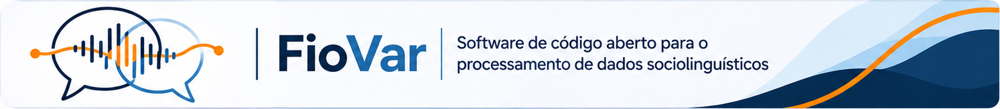

# **Apresentação**

O FioVar é um software de código aberto, em desenvolvimento, voltado à preparação e ao processamento de dados para pesquisas em Sociolinguística Variacionista (Labov, 1972). Sua finalidade é articular ferramentas computacionais em um percurso que compreende a organização das gravações, a transcrição e a anotação linguística, a revisão dos resultados e a preparação das ocorrências para análise. Ao integrar essas etapas, o projeto busca preservar os vínculos entre áudios, transcrições, anotações e dados tabulados, documentando as transformações realizadas ao longo do trabalho.

A ideia do FioVar surgiu a partir do convite da professora Leila Tesch (UFES) para ministrar uma oficina de ferramentas computacionais no IV Encontro Capixaba de Sociolinguistas, realizado de 3 a 5 de novembro de 2026. A preparação da oficina motivou a articulação de recursos que, embora disponíveis, exigem diferentes procedimentos de instalação, configuração e uso. Inspirado na metáfora do fio que orienta o percurso por um labirinto, o FioVar propõe uma estrutura modular, adaptável às necessidades de cada pesquisa e acompanhada de revisão humana.

O processamento reúne a transcrição automática e o alinhamento temporal com o WhisperX (Bain et al., 2023), a diarização com o pyannote.audio (Bredin et al., 2020) e a anotação morfossintática com o Stanza (Qi et al., 2020). Os resultados são organizados em arquivos compatíveis com o ELAN (Wittenburg et al., 2006), permitindo sua inspeção e revisão em associação com a gravação. Conforme o fenômeno investigado, o percurso também contempla a transcrição fonológica derivada da escrita com o SILAC (Oushiro, 2018), sugestões de transcrição fonética a partir do áudio com o modelo wav2vec2-large-xlsr-53-phoneme-portuguese, desenvolvido por Rocha (2024), e a identificação, extração e tabulação de ocorrências com o dmsocio (Oushiro, 2018), preparando os dados para análises posteriores em R (R Core Team, 2026).

A versão **v0.1.0-alpha tem caráter experimental**. O funcionamento integrado das ferramentas e a qualidade dos resultados ainda precisam ser avaliados em diferentes condições de gravação, perfis de fala e contextos de pesquisa. Transcrições, alinhamentos, atribuições de falantes e anotações automáticas constituem resultados preliminares, sujeitos a erros. Em particular, as sugestões de transcrição fonética e a identificação automática de candidatos não equivalem à identificação validada de variantes: sua utilização depende de conferência auditiva, aplicação dos critérios da pesquisa e revisão pelo pesquisador.

Para a Sociolinguística, a contribuição pretendida é reduzir parte do trabalho repetitivo de preparação dos dados e facilitar a articulação entre diferentes níveis de anotação, mantendo as ocorrências vinculadas às gravações e às informações sociais dos participantes. A disponibilização do código-fonte, da documentação e dos registros de processamento e revisão busca tornar os procedimentos examináveis, reproduzíveis e passíveis de aperfeiçoamento coletivo. Essa proposta se orienta pela ciência aberta, com reconhecimento das autorias, respeito às licenças e proteção dos dados dos participantes.

Os próximos passos incluem testar o funcionamento integrado das ferramentas, avaliar a qualidade dos resultados automáticos e aperfeiçoar a documentação e os procedimentos de revisão. Com base nessa avaliação, pretende-se desenvolver protocolos para o estudo de variáveis de natureza fonético-fonológica, morfossintática e, por que não, discursivo-pragmática. Cada protocolo deverá articular as etapas de processamento, a delimitação do envelope de variação, os critérios de seleção e codificação das ocorrências e os procedimentos de validação, considerando as particularidades do fenômeno investigado.

O percurso proposto pelo FioVar começa com a leitura do PDF indicado no README do projeto. Esse documento reúne os tutoriais para acessar e baixar o notebook no GitHub, entrar no Google Colab e abrir o arquivo, criar uma conta no Hugging Face, autorizar o acesso ao modelo de diarização e gerar um token, armazenando-o com segurança nos Segredos do Colab. Também apresenta orientações para criar uma pasta FioVar no computador, organizar os arquivos e conservar os resultados.

Após essa preparação, o pipeline aborda os cuidados com os dados da pesquisa, a preparação do áudio, a identificação do participante e o registro dos preditores sociais, seguidos da instalação das bibliotecas e da verificação do acesso ao modelo. O processamento compreende a transcrição automática, o alinhamento temporal e a diarização, com procedimentos para salvar e recuperar os resultados, exportá-los para o ELAN e revisá-los. Na sequência, são realizadas a preparação das trilhas para anotação linguística, a etiquetagem morfossintática, a representação fonológica derivada da escrita e a produção de sugestões de transcrição fonética automática. Na versão apresentada, as etapas finais se concentram na identificação de contextos de variação de /r/ em coda, na revisão e codificação das ocorrências e na tabulação dos dados, reunindo informações sociais e linguísticas para análise.


**Emerson Souza**  
DEDU/PPGEL/UEFS  
Versão v0.1.0-alpha — Atualizado em 2 de novembro de 2026.

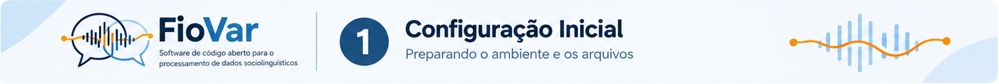

# **1. Verificação e preparação do áudio**

Nesta etapa, vamos preparar uma versão do áudio para a transcrição e o alinhamento, procedimento que identifica em que momento as palavras são pronunciadas na gravação.

Antes de enviar qualquer arquivo, leia a seção “Cuidados com os dados antes de enviar o áudio”.

# **Cuidados com os dados antes de enviar o áudio**

Antes de enviar uma gravação ao Colab, confira se o uso dos dados e desse serviço está de acordo com as condições da pesquisa e as orientações da instituição.

## **O áudio pode identificar uma pessoa?**

Sim. A voz, os nomes mencionados e o conteúdo da conversa podem permitir identificar quem fala ou outras pessoas. A gravação também pode revelar informações sensíveis, como dados sobre saúde, religião ou opinião política. Essas informações recebem proteção da [Lei Geral de Proteção de Dados Pessoais — LGPD](https://www.planalto.gov.br/ccivil_03/_ato2015-2018/2018/lei/l13709.htm).

Trocar o nome por um pseudônimo não torna o áudio anônimo, porque a pessoa ainda pode ser reconhecida pela voz ou pelo conteúdo.

## **Posso utilizar a gravação na pesquisa?**

Antes de enviar o áudio, confirme qual é a base legal, isto é, a condição prevista na LGPD que permite utilizar esses dados. O consentimento é uma possibilidade, mas não é a única. Quando ele for utilizado, deve ser livre, informado e específico; autorizar uma gravação não significa autorizar qualquer uso posterior.

A finalidade acadêmica não dispensa essa avaliação. Siga as orientações da instituição e as exigências éticas aplicáveis, consultando o [guia da ANPD sobre dados pessoais em pesquisas](https://www.gov.br/anpd/pt-br/centrais-de-conteudo/materiais-educativos-e-publicacoes/guia-orientativo-tratamento-de-dados-pessoais-para-fins-academicos-e-para-a-realizacao-de-estudos-e-pesquisas).

## **Para onde o áudio é enviado no Colab?**

Neste procedimento, o áudio é enviado a um computador remoto do Google, que executa o código. Esse envio já ocorre na etapa de conversão, antes da transcrição.

O código apresentado não salva o áudio automaticamente no Google Drive. O ambiente de processamento é temporário e pode ser excluído após inatividade ou ao atingir seu tempo máximo de uso. Fechar a aba não garante exclusão imediata. Consulte as [perguntas frequentes do Colab](https://research.google.com/colaboratory/faq.html).

## **O Google guarda os dados ou os utiliza para treinar IA?**

O armazenamento temporário do áudio não significa, por si só, que ele será utilizado para treinar modelos de IA. Também não permite garantir a exclusão imediata de todos os registros do serviço. Os prazos variam conforme o tipo de informação, segundo a [política de retenção do Google](https://policies.google.com/technologies/retention?hl=pt-BR).

Usar o assistente de IA do Colab é uma atividade diferente de executar o código apresentado e envolve regras específicas de coleta e uso de informações. Antes de fornecer dados ao assistente, consulte a [seção sobre IA nas perguntas frequentes do Colab](https://research.google.com/colaboratory/faq.html), os [termos do serviço](https://research.google.com/colaboratory/tos_v6.html) e a [Política de Privacidade do Google](https://policies.google.com/privacy?hl=pt-BR).

## **1.1 Preciso converter meu arquivo?**

O procedimento de conversão produz um arquivo no formato WAV, com o som armazenado sem compressão, em PCM de 16 bits. PCM é uma forma de representar o som por números, e os 16 bits indicam a precisão usada para registrar cada amostra do sinal sonoro.

O áudio terá um único canal, chamado mono. Se a gravação tiver dois canais, como ocorre em áudios estéreo, eles serão combinados. A frequência de amostragem será de 16.000 Hz, o que significa que cada segundo de áudio será representado por 16 mil amostras do sinal sonoro.

Se o áudio já tiver essas características, você pode seguir para a etapa de identificação do participante e organização do áudio. A extensão `.wav`, sozinha, não confirma todas essas condições.

Se o arquivo estiver em outro formato, tiver características diferentes ou você não souber verificá-las, utilize a conversão abaixo. O código cria uma versão preparada de qualquer áudio enviado, inclusive de um WAV.

## **1.2 O que a conversão permite e quais são seus limites?**

A conversão padroniza arquivos como MP3, M4A, OGG e FLAC para o fluxo de processamento do FioVar.

Ela não melhora a gravação, não remove ruídos e não recupera informações perdidas. Transformar um MP3 em WAV, por exemplo, não restaura os detalhes descartados na compressão. O arquivo convertido também pode ocupar mais espaço.

Ao reunir os canais em mono, a conversão deixa de preservar sua separação. Se cada canal contiver uma pessoa diferente, avalie se é necessário mantê-los separados antes de prosseguir.

Preserve sempre o original. Para análises acústicas, a escolha do arquivo deve considerar o objetivo da pesquisa. Prefira gravações originalmente produzidas sem perdas e preserve suas características de gravação.

## **1.3 Como organizar os arquivos de áudio por participante?**

Desde a catalogação, utilize o pseudônimo previamente atribuído a cada participante para nomear seus arquivos. Mantenha a mesma escrita em todas as etapas.

Altere apenas o nome e preserve a extensão original, isto é, a parte final que indica o formato, como `.mp3`, `.m4a` ou `.wav`. Por exemplo, se o pseudônimo for `CarlosC`, um arquivo chamado `gravacao.mp3` pode ser renomeado para `CarlosC.mp3`.

Não escreva `.wav` no lugar da extensão existente. Essa troca não converte o áudio e pode dificultar sua abertura. A conversão será feita pelo código. Um arquivo chamado `CarlosC.mp3` dará origem a `CarlosC_preparado.wav`.

Se o computador não mostrar a extensão, altere somente o nome visível, sem acrescentar `.wav` ou outra extensão.

Essa organização facilita a construção do `ID_PARTICIPANTE`, identificador que relaciona cada pessoa aos seus arquivos e resultados. Também ajuda a associar os preditores sociais, características consideradas na análise, como idade, gênero e escolaridade, aos respectivos códigos.

Se houver mais de uma gravação da mesma pessoa, acrescente uma numeração ao nome, preservando a extensão. Por exemplo, utilize `CarlosC_01.mp3` e `CarlosC_02.mp3`. Essa numeração identifica as gravações; o identificador da pessoa deve permanecer o mesmo.



## **1.4 Como executar a conversão?**

Execute o código no Google Colab, pelo navegador. Ele utiliza o FFmpeg, programa responsável pela conversão, que precisa estar disponível no ambiente.

Você não precisa alterar o código nem digitar o nome do arquivo.

1. Clique no botão ▶, à esquerda da célula de código.
2. Selecione apenas um arquivo de áudio no computador.
3. Aguarde o envio e a conversão. O tempo depende do tamanho do arquivo e da conexão.
4. Confira se apareceu a mensagem “Áudio preparado”, seguida do nome do arquivo.
5. Autorize o download, se o navegador solicitar, e salve o resultado.

Ao selecionar o arquivo, uma cópia será enviada ao ambiente remoto do Colab para processamento.

## **1.5 Como conferir o resultado?**

O arquivo manterá o nome original, com a extensão substituída por `_preparado.wav`. Por exemplo, `CarlosC.mp3` dará origem a `CarlosC_preparado.wav`.

Após o download, reproduza o arquivo para conferir se ele contém a gravação esperada. Essa escuta ajuda a identificar problemas evidentes, mas não garante a qualidade da futura transcrição.

Salve o resultado no computador, pois o armazenamento do Colab é temporário. Se você repetir a conversão, o código poderá substituir o arquivo preparado por outro de mesmo nome no ambiente do Colab.

Ao executar o código a seguir, a instrução da linha 53 abrirá uma janela para que você localize e selecione o arquivo de áudio no computador. Essa janela aparecerá sempre que uma etapa do pipeline solicitar o envio de um arquivo.

In [ ]:
from google.colab import files
from pathlib import Path
import subprocess

# ============================================================
# 1. ENVIAR O ÁUDIO
# ============================================================

uploaded = files.upload()

if len(uploaded) != 1:
    raise ValueError("Envie apenas um arquivo por vez.")

audio_original = next(iter(uploaded))

# ============================================================
# 2. DEFINIR O NOME DO ARQUIVO PREPARADO
# ============================================================

# Usa um nome diferente para preservar o arquivo original.

audio_wav = str(
    Path(audio_original).with_name(
        Path(audio_original).stem + "_preparado.wav"
    )
)

# ============================================================
# 3. CONVERTER PARA WAV
# ============================================================

# Prepara o áudio com um canal (mono), 16.000 Hz e PCM de 16 bits.
# Se a conversão falhar, a execução será interrompida

subprocess.run(
    [
        "ffmpeg", "-y",
        "-i", audio_original,
        "-vn",
        "-ac", "1",
        "-ar", "16000",
        "-c:a", "pcm_s16le",
        audio_wav
    ],
    check=True
)

# ============================================================
# 4. CONFERIR E BAIXAR O ÁUDIO PREPARADO
# ============================================================

print("Áudio preparado:", audio_wav)
files.download(audio_wav)

# **2. Identificação do participante e organização do áudio**

Nesta etapa, vamos definir os preditores sociais da pesquisa, preencher os dados do participante e criar uma etiqueta de identificação para o arquivo de áudio.

Essa etiqueta reunirá, em códigos, o pseudônimo do participante e suas características sociais. Ela será mantida nos nomes dos arquivos até a geração dos arquivos EAF. Nas etapas seguintes, esses códigos serão recuperados para associar os fatores sociais às ocorrências analisadas.

## **2.1 Como definir os preditores sociais?**

Preditores sociais são características dos participantes consideradas na análise, como idade, gênero e escolaridade. Sua escolha deve seguir os objetivos e as hipóteses da pesquisa.

Antes de preencher os dados do participante, localize o bloco `PREDITORES` no código. Nele, você define quais características serão registradas, os valores aceitos e os códigos usados na etiqueta de identificação do áudio.

Veja o exemplo de configuração da escolaridade:

```python
"escolaridade": {
    "codigo": "ESC",
    "tipo": "categorico",
    "categorias": {
        "fundamental": "FUND",
        "medio": "MED",
        "superior": "SUP",
        "nao_informado": "NI",
    },
},
```

Nesse bloco:

- `"codigo": "ESC"` define a sigla que identifica o preditor escolaridade.
- `"tipo": "categorico"` indica que o valor informado deve corresponder a uma das opções de `"categorias"`.
- `"categorias"` associa cada opção ao código que será incluído na etiqueta. Por exemplo, `"superior"` corresponde a `SUP`.

Assim, quando a escolaridade do participante for informada como `"superior"`, a etiqueta reunirá a sigla `ESC` e o código `SUP`, formando `ESCSUP`.

Antes de processar as gravações, ajuste os preditores e suas categorias ao planejamento da pesquisa. Depois, utilize as mesmas regras para todos os participantes, garantindo que os códigos tenham um significado consistente em todo o conjunto de dados.

## **2.2 Como acrescentar um novo preditor?**

Primeiro, defina sua regra em `PREDITORES`. Depois, acrescente o valor ao cadastro do participante.

Vamos usar como exemplo o tempo de residência de um migrante na comunidade anfitriã.

Dentro de `PREDITORES`, após o bloco de escolaridade e antes da chave final, acrescente o trecho abaixo.

```python
    "tempo_residencia": {
        "codigo": "TEMRES",
        "tipo": "inteiro",
        "obrigatorio": False,
    },
```

`TEMRES` é a sigla escolhida para tempo de residência. Ela reúne `TEM`, de tempo, e `RES`, de residência. O tipo `"inteiro"` indica um número sem casas decimais. Neste exemplo, serão registrados anos completos de residência.

`False` informa que o preenchimento não é obrigatório. Para torná-lo obrigatório, utilize `True`, sem aspas.

Defina o local de referência e mantenha a mesma unidade de tempo para todos os participantes.

## **2.3 Como preencher os dados do participante?**

Depois de definir os preditores, localize o bloco `PARTICIPANTE`. Substitua os valores fictícios pelos dados da pessoa cuja gravação será enviada.

Se você incluiu o tempo de residência em `PREDITORES`, acrescente essa informação também dentro de `"fatores"`.

```python
PARTICIPANTE = {
    "pseudonimo": "CarlosC",
    "fatores": {
        "idade": 62,
        "genero": "homem",
        "escolaridade": "superior",
        "tempo_residencia": 10,
    },
}
```

Em `"pseudonimo"`, substitua `CarlosC` pelo pseudônimo atribuído na catalogação. Mantenha as aspas e a mesma escrita nas diferentes etapas.

Em `"idade"`, substitua `62` pela idade do participante. Em `"tempo_residencia"`, substitua `10` pelo número de anos completos de residência. Digite esses números sem aspas.

Em `"genero"` e `"escolaridade"`, utilize exatamente uma das categorias definidas em `PREDITORES`. Por exemplo, ensino médio está representado por `"medio"`, sem acento.

Para uma informação opcional ausente, use `None`, sem aspas.

```python
"tempo_residencia": None,
```

Nesse caso, a etiqueta receberá `TEMRESAUS`. A idade é obrigatória na configuração apresentada.

**Preserve os nomes dos campos, as aspas, as vírgulas e as chaves.** Se você não acrescentou tempo de residência em `PREDITORES`, não o inclua no cadastro.

## **2.4 Como a etiqueta é formada?**

O código combina o pseudônimo com as siglas dos preditores e os valores codificados. Com os dados do exemplo, o nome será o seguinte.

```text
CarlosC_IDA62_GENHOM_ESCSUP_TEMRES10.wav
```

`CarlosC` identifica o pseudônimo; `IDA62` indica idade de 62 anos; `GENHOM` corresponde à categoria “homem”; `ESCSUP`, à escolaridade “superior”; e `TEMRES10`, a dez anos completos de residência.

Sem o preditor tempo de residência, o nome será formado desta maneira.

```text
CarlosC_IDA62_GENHOM_ESCSUP.wav
```

## **2.5 Como essa etiqueta será utilizada depois?**

A etiqueta acompanhará os arquivos produzidos pelo FioVar até a geração dos arquivos EAF, que armazenam as anotações da gravação para uso no ELAN.

A identificação será mantida no nome, enquanto a extensão mudará conforme o tipo de arquivo. Posteriormente, os códigos da etiqueta serão recuperados para associar os fatores sociais a cada dado analisado.

A recuperação de um novo preditor, como `TEMRES`, também precisa estar prevista no código da etapa que organiza os resultados. Acrescentá-lo à etiqueta não cria automaticamente uma coluna na tabela final.

**Não altere nem apague partes da etiqueta nas próximas etapas.** Isso pode impedir a recuperação correta das informações.

## **2.6 Como enviar e baixar o áudio etiquetado?**

Após conferir as regras e os dados do participante, clique em ▶ e selecione apenas um arquivo WAV, preparado conforme a etapa anterior.

O código confere a extensão e a estrutura inicial do arquivo. Ele não verifica se o áudio é mono, tem frequência de amostragem de 16.000 Hz ou utiliza PCM de 16 bits.

Ao concluir, aparecerá a mensagem “Etiquetagem concluída!”, seguida do nome do áudio. O navegador solicitará o download. Salve o arquivo na pasta de trabalho criada no seu computador.

A etiquetagem cria uma cópia com o novo nome, sem modificar o som. Uma cópia ficará temporariamente no ambiente do Colab para uso nas próximas etapas.

Se já existir um áudio diferente com a mesma etiqueta nesse ambiente, a operação será interrompida. Confira o cadastro e a gravação antes de continuar.

In [ ]:
from pathlib import Path
from google.colab import files
import math
import re

# ============================================================
# 1. DEFINIR OS PREDITORES E OS CÓDIGOS
# ============================================================

# Defina estas regras antes de preencher os dados do participante.
# Mantenha o mesmo padrão em todas as gravações da pesquisa.

PREDITORES = {
    "idade": {
        "codigo": "IDA",
        "tipo": "inteiro",
        "obrigatorio": True,
    },
    "genero": {
        "codigo": "GEN",
        "tipo": "categorico",
        "categorias": {
            "mulher": "MUL",
            "homem": "HOM",
            "outro": "OUT",
            "nao_informado": "NI",
        },
    },
    "escolaridade": {
        "codigo": "ESC",
        "tipo": "categorico",
        "categorias": {
            "fundamental": "FUND",
            "medio": "MED",
            "superior": "SUP",
            "nao_informado": "NI",
        },
    },

    # Exemplo: tempo de residência no local pesquisado.
    # TEMRES reúne TEM, de tempo, e RES, de residência.
    # Neste exemplo, o valor representa anos completos.
    #
    # Para utilizar, retire o # das cinco linhas abaixo.
    # Depois, preencha tempo_residencia no cadastro do participante.

    # "tempo_residencia": {
    #     "codigo": "TEMRES",
    #     "tipo": "inteiro",
    #     "obrigatorio": False,
    # },
}

# ============================================================
# 2. PREENCHER OS DADOS DO PARTICIPANTE
# ============================================================

# Substitua os dados fictícios pelos dados da gravação enviada.
# Textos ficam entre aspas. Números ficam sem aspas.
# Para uma informação opcional ausente, utilize None, sem aspas.

PARTICIPANTE = {
    "pseudonimo": "CarlosC",
    "fatores": {
        "idade": 62,
        "genero": "homem",
        "escolaridade": "superior",

        # Ative a linha abaixo somente se também tiver ativado
        # a regra tempo_residencia no bloco PREDITORES.
        # Substitua 10 pelos anos completos de residência.

        # "tempo_residencia": 10,
    },
}

# ============================================================
# 3. CONFERIR OS DADOS E CRIAR A ETIQUETA
# ============================================================

def codigo_valido(valor):
    """Confere se o código utiliza letras maiúsculas e números."""
    return (
        isinstance(valor, str)
        and re.fullmatch(r"[A-Z][A-Z0-9]*", valor) is not None
    )


def criar_etiqueta():
    pseudonimo = PARTICIPANTE.get("pseudonimo", "")

    if not isinstance(pseudonimo, str) or not pseudonimo.strip():
        raise ValueError("Informe o pseudônimo do participante.")

    pseudonimo = pseudonimo.strip()

    if (
        re.search(r'[<>:"/\\|?*\x00-\x1f]', pseudonimo)
        or pseudonimo.endswith(".")
        or pseudonimo in {".", ".."}
    ):
        raise ValueError(
            "O pseudônimo contém caracteres inválidos "
            "para nomes de arquivos."
        )

    fatores = PARTICIPANTE.get("fatores")

    if not isinstance(fatores, dict):
        raise ValueError(
            "Mantenha as informações sociais no bloco "
            "'fatores', entre chaves."
        )

    extras = set(fatores) - set(PREDITORES)

    if extras:
        raise ValueError(
            "Defina primeiro as regras destes fatores "
            "no bloco PREDITORES: "
            + ", ".join(sorted(extras))
        )

    partes = [pseudonimo]
    siglas = set()

    for fator, regra in PREDITORES.items():
        if (
            not isinstance(fator, str)
            or not re.fullmatch(r"[a-z][a-z0-9_]*", fator)
        ):
            raise ValueError(f"Nome de preditor inválido: {fator}")

        if not isinstance(regra, dict):
            raise ValueError(f"Confira as regras de {fator}.")

        sigla = regra.get("codigo")
        tipo = regra.get("tipo")

        if not codigo_valido(sigla) or sigla in siglas:
            raise ValueError(
                f"Sigla inválida ou repetida: {sigla}. "
                "Use uma sigla diferente para cada preditor."
            )

        siglas.add(sigla)

        if tipo not in {
            "inteiro", "numero", "categorico", "texto", "booleano"
        }:
            raise ValueError(
                f"Tipo inválido para {fator}. "
                "Use inteiro, numero, categorico, texto ou booleano."
            )

        mapa = {}

        if tipo in {"categorico", "texto"}:
            campo = (
                "categorias"
                if tipo == "categorico"
                else "codigos_valores"
            )

            mapa = regra.get(campo, {})

            if not isinstance(mapa, dict) or not mapa:
                raise ValueError(f"Defina {campo} para {fator}.")

            if any(
                not isinstance(valor, str) or not valor.strip()
                for valor in mapa
            ):
                raise ValueError(f"Categorias inválidas em {fator}.")

            codigos = list(mapa.values())

            if any(
                not codigo_valido(codigo) or codigo == "AUS"
                for codigo in codigos
            ):
                raise ValueError(
                    f"Confira os códigos de {fator}. "
                    "Use letras maiúsculas e números. "
                    "AUS é reservado para ausência de informação."
                )

            if len(codigos) != len(set(codigos)):
                raise ValueError(f"Há códigos repetidos em {fator}.")

        valor = fatores.get(fator)

        if valor is None:
            if regra.get("obrigatorio", False):
                raise ValueError(
                    f"Preencha o fator obrigatório: {fator}."
                )

            partes.append(sigla + "AUS")
            continue

        if tipo == "inteiro":
            valido = type(valor) is int

        elif tipo == "numero":
            valido = (
                type(valor) in (int, float)
                and math.isfinite(valor)
            )

        elif tipo == "booleano":
            valido = type(valor) is bool

        else:
            valido = isinstance(valor, str) and valor in mapa

        if not valido:
            raise ValueError(
                f"Valor inválido para {fator}: {valor!r}. "
                "Confira a escrita e as regras em PREDITORES."
            )

        if tipo in {"categorico", "texto"}:
            codigo = mapa[valor]

        elif tipo == "booleano":
            codigo = "SIM" if valor else "NAO"

        else:
            codigo = (
                str(valor)
                .upper()
                .replace("-", "NEG")
                .replace(".", "P")
                .replace("+", "POS")
            )

        partes.append(sigla + codigo)

    etiqueta = "_".join(partes)

    if len(etiqueta) > 150:
        raise ValueError(
            "A etiqueta ficou longa demais. "
            "Revise o tamanho do pseudônimo e dos códigos."
        )

    PARTICIPANTE["pseudonimo"] = pseudonimo

    return etiqueta


# Preserve esta etiqueta nos nomes dos arquivos até o EAF.
ETIQUETA = criar_etiqueta()

# ============================================================
# 4. ENVIAR O ÁUDIO WAV
# ============================================================

print("Participante:", PARTICIPANTE["pseudonimo"])
print("Etiqueta:", ETIQUETA)
print("Selecione apenas um arquivo WAV preparado.")

enviados = files.upload()

if len(enviados) != 1:
    raise ValueError("Envie exatamente um arquivo WAV.")

nome_original, dados_wav = next(iter(enviados.items()))

if Path(nome_original).suffix.lower() != ".wav":
    raise ValueError(
        "Selecione um arquivo WAV. "
        "Se necessário, execute a conversão da etapa anterior."
    )

# Conferência básica da estrutura WAV.
# Não verifica canais, frequência de amostragem ou precisão.
if (
    len(dados_wav) < 12
    or dados_wav[:4] not in (b"RIFF", b"RF64")
    or dados_wav[8:12] != b"WAVE"
):
    raise ValueError(
        "A estrutura inicial do arquivo não foi reconhecida como WAV. "
        "Confira o arquivo ou refaça a conversão."
    )

# ============================================================
# 5. PREPARAR O ÁUDIO COM A ETIQUETA PADRÃO
# ============================================================

# Usa a área temporária do Colab.
# Não cria pasta no Google Drive, cadastro JSON ou pacote ZIP.
audio_path = Path.cwd() / f"{ETIQUETA}.wav"

# Mantém a etiqueta sem acrescentar sufixos.
# Se existir um arquivo diferente com esse nome, interrompe.
if audio_path.exists():
    if audio_path.read_bytes() != dados_wav:
        raise FileExistsError(
            "Já existe um áudio diferente com essa etiqueta no Colab. "
            "Confira o cadastro e a gravação antes de continuar."
        )
else:
    # Copia o áudio sem modificar os dados sonoros.
    with audio_path.open("xb") as arquivo:
        arquivo.write(dados_wav)

# Caminho utilizado pelas próximas etapas para acessar o áudio.
audio_wav = str(audio_path)

# ============================================================
# 6. PREPARAR AS FUNÇÕES PARA AS PRÓXIMAS ETAPAS
# ============================================================

def rotulo_participante():
    """Retorna o pseudônimo para títulos, mensagens e gráficos."""
    return PARTICIPANTE["pseudonimo"]


def caminho_saida(etapa, nome_arquivo):
    """
    Indica um caminho na área temporária do Colab.
    A célula que gerar o arquivo deve preservar ETIQUETA no nome.
    O argumento etapa mantém compatibilidade com outras células.
    """
    if (
        not isinstance(nome_arquivo, str)
        or not nome_arquivo.strip()
        or re.search(r'[<>:"/\\|?*\x00-\x1f]', nome_arquivo)
        or nome_arquivo.endswith((".", " "))
        or nome_arquivo in {".", ".."}
    ):
        raise ValueError("Informe um nome de arquivo válido.")

    return Path.cwd() / nome_arquivo

# ============================================================
# 7. CONFERIR E BAIXAR O ÁUDIO ETIQUETADO
# ============================================================

print("Etiquetagem concluída!")
print("Participante:", rotulo_participante())
print("Áudio:", audio_path.name)
print("Preserve a etiqueta nos arquivos das próximas etapas.")
print("Salve o áudio na pasta de trabalho do seu computador.")

files.download(audio_wav)

## **2.7 O que conferir antes de continuar?**

Confira se o pseudônimo e os fatores sociais correspondem à pessoa da gravação. O código verifica regras de preenchimento, mas não confirma se você selecionou o áudio correto.

# **3. Instalação das bibliotecas para transcrição, alinhamento e criação de arquivos EAF**

Nesta etapa, vamos instalar as bibliotecas utilizadas nessas tarefas. Bibliotecas são conjuntos de recursos prontos que o código utiliza, por exemplo, para transcrever áudios e criar arquivos.

A instalação acontece no ambiente do Colab, não no seu computador.

## **3.1 O que será instalado?**

O WhisperX realiza a transcrição automática da fala e o alinhamento temporal, que identifica em que momento as palavras são pronunciadas.

O NumPy permite trabalhar com os dados numéricos que representam o áudio.

O pympi-ling permite criar e manipular arquivos EAF, utilizados pelo ELAN para relacionar as anotações aos trechos da gravação.

A instalação também inclui outras bibliotecas necessárias ao funcionamento dessas ferramentas, chamadas dependências. Você não precisa instalar cada uma delas separadamente.

## **2.2 Por que a versão do NumPy está indicada no código?**

As versões das bibliotecas precisam funcionar em conjunto. Por isso, o comando solicita uma versão específica do NumPy.

```python
"numpy==2.2.6"
```

O sinal `==` significa “exatamente esta versão”.

As versões do WhisperX, do pympi-ling e das dependências não estão fixadas nesse comando. Portanto, a instalação não garante, sozinha, a reprodução completa do ambiente testado. A célula de verificação ajudará a conferir as versões instaladas.

## **3.3 Como executar a instalação?**

Clique em ▶ na célula de código abaixo e aguarde a execução terminar. A instalação pode levar alguns minutos.

O comando utiliza `-q` para reduzir as mensagens exibidas. Por isso, podem aparecer poucas informações enquanto ele trabalha. Avisos e erros ainda podem ser apresentados.

Se ocorrer um erro, confira a mensagem antes de continuar. O fim da execução, sozinho, não confirma que todas as bibliotecas funcionam corretamente. Execute também a célula de verificação.

In [3]:
%pip install -q whisperx pympi-ling "numpy==2.2.6"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.


## **3.4 Avisos de instalação**

Durante a instalação, pode aparecer uma mensagem como esta.

```text
ERROR: pip's dependency resolver does not currently take into
account all the packages that are installed.
```

Isso significa que o instalador identificou conflitos entre versões de bibliotecas. Uma ferramenta pode precisar de uma versão diferente daquela instalada no ambiente.

O exemplo abaixo apresenta um desses conflitos.

```text
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0,
but you have huggingface-hub 0.36.2 which is incompatible.
```

Nesse caso, o Diffusers exige uma versão do Hugging Face Hub igual ou superior a 1.32.0 e inferior a 3.0, mas encontrou a versão 0.36.2. No aviso observado, também foram apontados conflitos envolvendo Gradio, Gradio Client e Google ADK.

A palavra `ERROR` não significa, necessariamente, que toda a instalação falhou. Será preciso executar a verificação do ambiente para conferir o carregamento dos componentes utilizados pelo FioVar.

## **3.5 O que fazer agora?**

Não altere as versões apenas com base nesse aviso. Primeiro, reinicie a sessão pelo menu `Ambiente de execução`, escolhendo a opção de reiniciar a sessão, sem excluir o ambiente.

A reinicialização limpa as informações mantidas na memória. Se alguma etapa seguinte depender de dados definidos anteriormente, será necessário executar novamente as células correspondentes.

Depois, execute a célula “Verificação do ambiente”.

Se aparecer “Bibliotecas necessárias carregadas.”, os componentes verificados foram carregados e você poderá continuar. Isso não corrige os conflitos anteriores nem garante o funcionamento de todos os modelos e etapas.

Se a verificação apresentar erro, guarde a mensagem completa para identificar o ajuste necessário antes de prosseguir.

## **3.6 Verificação do ambiente**

Após a instalação e a reinicialização da sessão, execute a célula abaixo. Ela confere as versões do NumPy e do Numba, o carregamento das bibliotecas necessárias e a disponibilidade de GPU.



In [4]:
import numpy as np
import numba
import torch
import whisperx

from transformers import pipeline
from whisperx import load_align_model, align

print("NumPy:", np.__version__)
print("Numba:", numba.__version__)
print("GPU disponível:", torch.cuda.is_available())
print("Bibliotecas necessárias carregadas.")

NumPy: 2.4.6
Numba: 0.64.0
GPU disponível: True
Bibliotecas necessárias carregadas.


## **3.7 Como interpretar o resultado da verificação?**

No teste realizado, a verificação apresentou:

```text
NumPy: 2.2.6
Numba: 0.61.2
GPU disponível: True
Bibliotecas necessárias carregadas.
```

As duas primeiras linhas mostram as versões carregadas do NumPy e do Numba. `GPU disponível: True` indica que o código conseguiu acessar a GPU, recurso que pode acelerar o processamento do áudio.

A mensagem “Bibliotecas necessárias carregadas.” confirma que os componentes verificados foram disponibilizados para uso. Nesse teste, os avisos de instalação não impediram seu carregamento.

**Com esse resultado, você pode seguir para a próxima etapa.** A verificação não corrige os conflitos anteriores nem garante o funcionamento de todos os modelos.

Se aparecer `GPU disponível: False`, o código não conseguiu acessar uma GPU naquele momento. Isso, sozinho, não significa que a instalação falhou.


# **4. Verificação do acesso ao modelo de diarização**

Nesta etapa, vamos conferir se o FioVar consegue utilizar sua credencial do Hugging Face e acessar o modelo Community-1, que será utilizado para separar os trechos de fala por falante.

Antes de executar, conclua o tutorial de preparação do acesso apresentado no início do notebook. O token deve estar armazenado nos Segredos do Colab com o nome `HF_TOKEN` e com o acesso ao notebook ativado.

## **4.1 Como executar?**

Clique em ▶ na célula de código abaixo. O código recuperará o token, verificará a conta e tentará baixar um pequeno arquivo de configuração do modelo.

Não é necessário alterar o código nem colar sua credencial nele.

In [5]:
from google.colab import userdata
from huggingface_hub import HfApi, hf_hub_download

# ============================================================
# 1. RECUPERAR O TOKEN DOS SEGREDOS DO COLAB
# ============================================================

HF_TOKEN = userdata.get("HF_TOKEN").strip()

# ============================================================
# 2. VERIFICAR A AUTENTICAÇÃO DA CONTA
# ============================================================

usuario = HfApi().whoami(token=HF_TOKEN)
print("Conta autenticada:", usuario["name"])

# ============================================================
# 3. TESTAR O ACESSO AO MODELO DE DIARIZAÇÃO
# ============================================================

hf_hub_download(
    repo_id="pyannote/speaker-diarization-community-1",
    filename="config.yaml",
    token=HF_TOKEN
)

# ============================================================
# 4. CONFIRMAR O RESULTADO DA VERIFICAÇÃO
# ============================================================

print("Acesso ao modelo autorizado!")

Conta autenticada: Emerson1985


config.yaml:   0%|          | 0.00/444 [00:00<?, ?B/s]

Acesso ao modelo autorizado!


## **4.2 Qual resultado esperar?**

Se a verificação for concluída, aparecerão mensagens semelhantes a estas.

```text
Conta autenticada: seu_nome_de_usuario
Acesso ao modelo autorizado!
```

A primeira mensagem confirma que o token foi reconhecido. A segunda indica que o arquivo de configuração do modelo pôde ser acessado.

Essa verificação ainda não processa o áudio nem confirma o carregamento completo do modelo.

## **4.3 O que fazer se aparecer um erro?**

Confira se o segredo está nomeado exatamente como `HF_TOKEN` e se o acesso ao notebook está ativado.

Verifique também se o token pertence à mesma conta que recebeu autorização para acessar o Community-1.

Se o problema continuar, guarde a mensagem de erro, sem compartilhar o token, para identificar o ajuste necessário.

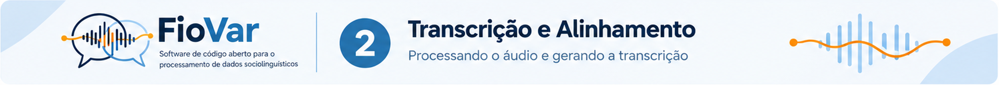

# **5. Transcrição automática do áudio**

Nesta etapa, o WhisperX transformará a fala da gravação em texto. O código utiliza o modelo `large-v2` e está configurado para transcrever áudios em português.

## **5.1 Qual arquivo devo selecionar?**

Utilize o arquivo WAV preparado e etiquetado nas etapas anteriores. Preserve o nome que contém o pseudônimo e os códigos dos fatores sociais, pois essa identificação acompanhará os próximos arquivos.

Esta célula solicita o envio do áudio novamente. Você pode selecionar a versão que salvou no computador.

## **5.2 Como executar a transcrição?**

Clique em ▶ na célula de código abaixo. A instrução da linha 61 abrirá uma janela para que você localize e selecione **apenas um arquivo de áudio** no computador.

Após a seleção, o código verificará se há uma GPU disponível e informará qual recurso será utilizado:

- **“Processamento com: GPU”**: a transcrição utilizará a GPU para acelerar os cálculos.
- **“Processamento com: CPU”**: a transcrição utilizará o processador comum do computador remoto do Colab, o que pode levar mais tempo.

Em seguida, o código carregará o modelo e iniciará a transcrição. Se os arquivos do modelo ainda não estiverem disponíveis no ambiente do Colab, eles serão baixados nessa etapa.

Aguarde o término da execução antes de continuar.

In [6]:
from pathlib import Path
from google.colab import files
import torch
import whisperx

# ============================================================
# 1. ENVIAR O ÁUDIO WAV
# ============================================================

print("Selecione o arquivo WAV etiquetado na etapa anterior.")

uploaded = files.upload()

if len(uploaded) != 1:
    raise ValueError("Envie apenas um arquivo de áudio por vez.")

audio_wav = next(iter(uploaded))

if Path(audio_wav).suffix.lower() != ".wav":
    raise ValueError("Selecione o arquivo WAV preparado e etiquetado.")

# ============================================================
# 2. VERIFICAR A DISPONIBILIDADE DE GPU
# ============================================================

device = "cuda" if torch.cuda.is_available() else "cpu"
compute_type = "float16" if device == "cuda" else "int8"

print("Arquivo selecionado:", audio_wav)
print("Processamento com:", "GPU" if device == "cuda" else "CPU")

# ============================================================
# 3. CARREGAR O MODELO DE TRANSCRIÇÃO
# ============================================================

model = whisperx.load_model(
    "large-v2",
    device,
    compute_type=compute_type,
    language="pt"
)

# ============================================================
# 4. CARREGAR E TRANSCREVER O ÁUDIO
# ============================================================

audio = whisperx.load_audio(audio_wav)

result = model.transcribe(
    audio,
    batch_size=4
)

# ============================================================
# 5. EXIBIR A TRANSCRIÇÃO
# ============================================================

print("Transcrição concluída!")

for segmento in result["segments"]:
    print(segmento["text"])

Selecione o arquivo WAV etiquetado na etapa anterior.


Saving CarlosC_IDA62_GENHOM_ESCSUP.wav to CarlosC_IDA62_GENHOM_ESCSUP (1).wav
Arquivo selecionado: CarlosC_IDA62_GENHOM_ESCSUP (1).wav
Processamento com: GPU


model.bin:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

vocabulary.txt: 0.00B [00:00, ?B/s]

config.json: 0.00B [00:00, ?B/s]

2026-11-03 10:16:32 - whisperx.vads.pyannote - INFO - Performing voice activity detection using Pyannote...


INFO: Lightning automatically upgraded your loaded checkpoint from v1.5.4 to v2.6.6. To apply the upgrade to your files permanently, run `python -m lightning.pytorch.utilities.upgrade_checkpoint ../usr/local/lib/python3.13/dist-packages/whisperx/assets/pytorch_model.bin`
INFO:lightning.pytorch.utilities.migration.utils:Lightning automatically upgraded your loaded checkpoint from v1.5.4 to v2.6.6. To apply the upgrade to your files permanently, run `python -m lightning.pytorch.utilities.upgrade_checkpoint ../usr/local/lib/python3.13/dist-packages/whisperx/assets/pytorch_model.bin`
/usr/local/lib/python3.13/dist-packages/pyannote/audio/utils/reproducibility.py:74: ReproducibilityWarning: TensorFloat-32 (TF32) has been disabled as it might lead to reproducibility issues and lower accuracy.
It can be re-enabled by calling
   >>> import torch
   >>> torch.backends.cuda.matmul.allow_tf32 = True
   >>> torch.backends.cudnn.allow_tf32 = True
See https://github.com/pyannote/pyannote-audio/issue

Transcrição concluída!
 A Rádio USP apresenta Via Samba, um passeio cultural pelo melhor da metrópole.
 Olá, boa tarde, você está na sua Rádio USP noventa e três vírgula sete megahertz de São Paulo. Eu sou Roberto Castro e junto comigo na mesa de som o radialista Tales Almeida, Tales, boa tarde Tales. Na produção executiva do programa, Eloísa Granito. A nossa equipe tem ainda Rocha Júnior, Benê Ribeiro, Marcos de Rosa, Eva Alves e Cristiane Pradela. A direção da Rádio USP é de
 E o Via Sampa Estúdio começa agora com o novo álbum do grande cantor e compositor paraibano Chico César. O amor é um ato revolucionário.
 ♪ ♪
 E aí E aí
 O amor é um ato revolucionário Quem vive amando, dando amor e sendo amado Colhendo o que lhe é oferecido E a si mesmo se coloca ofertado Se este está vivo Veste o manto sagrado Que ao que ama o infinito faz vestido De Deus e os deuses sim é o mais querido Mesmo no escuro Seu incidir é iluminado O amor é um ato revolucionário
 O amor é um ato revolucionário, é o

## **5.3 Qual resultado esperar?**

Ao concluir, aparecerá a mensagem “Transcrição concluída!”, seguida do texto reconhecido, dividido em trechos.

O resultado também ficará guardado temporariamente na variável `result`, um nome utilizado pelo código para armazenar informações e retomá-las nas próximas etapas.

**Esta célula exibe a transcrição, mas ainda não cria um arquivo para download.** Se a sessão for reiniciada, o resultado mantido na memória será perdido.

# **6. Alinhamento temporal da transcrição**

Nesta etapa, o WhisperX utiliza o áudio e a transcrição para estimar quando cada palavra começa e termina na gravação. Esse procedimento é chamado de alinhamento temporal.

## **6.1 O que precisa estar pronto?**

Execute esta célula depois da transcrição, na mesma sessão do Colab. Ela utiliza o áudio, o resultado da transcrição e a configuração de processamento definidos na etapa anterior.

Não é necessário enviar o arquivo novamente. Se a sessão tiver sido reiniciada, será preciso executar novamente a transcrição antes de continuar.

## **6.2 Como executar o alinhamento?**

Clique em ▶ na célula de código abaixo e aguarde. O código carregará um modelo de alinhamento para português e relacionará as palavras transcritas aos momentos correspondentes no áudio.

A configuração apresentada solicita o alinhamento das palavras, sem produzir marcações individuais para cada letra ou caractere.

In [7]:
# ============================================================
# 1. CARREGAR O MODELO DE ALINHAMENTO PARA PORTUGUÊS
# ============================================================

model_a, metadata = whisperx.load_align_model(
    language_code="pt",
    device=device
)

# ============================================================
# 2. ALINHAR AS PALAVRAS DA TRANSCRIÇÃO AO ÁUDIO
# ============================================================

result = whisperx.align(
    result["segments"],
    model_a,
    metadata,
    audio,
    device,
    return_char_alignments=False
)

# ============================================================
# 3. CONFIRMAR A CONCLUSÃO DO ALINHAMENTO
# ============================================================

print("Alinhamento concluído!")

preprocessor_config.json:   0%|          | 0.00/262 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

vocab.json:   0%|          | 0.00/430 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/85.0 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/1.26G [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.26G [00:00<?, ?B/s]

Alinhamento concluído!


## **6.3 Qual resultado esperar?**

Ao terminar, aparecerá a mensagem “Alinhamento concluído!”.

O resultado ficará armazenado na variável `result`, agora com as informações de alinhamento disponíveis. Essas marcações serão utilizadas nas próximas etapas para relacionar a transcrição aos trechos da gravação.

Esta célula não exibe todas as marcações nem cria um arquivo para download. O resultado permanece temporariamente na memória da sessão.

# **7. Diarização**

Nesta etapa, o código identifica os trechos atribuídos a diferentes falantes e associa essas identificações à transcrição alinhada. Esse procedimento é chamado de diarização.

O sistema utiliza rótulos como `SPEAKER_00` e `SPEAKER_01`. Eles distinguem as vozes encontradas, mas não informam os nomes nem os pseudônimos das pessoas.

## **7.1 O que precisa estar pronto?**

Execute primeiro a transcrição e o alinhamento, sem reiniciar a sessão entre as etapas. O código precisa acessar o áudio e os resultados mantidos na memória do Colab.

Também é necessário ter acesso ao modelo Community-1 e um token válido armazenado como `HF_TOKEN` nos Segredos do Colab, conforme o tutorial inicial.

## **7.2 Como executar a diarização?**

Clique em ▶ na célula de código abaixo e aguarde. O código verificará os resultados anteriores, selecionará GPU ou CPU e recuperará o token de acesso.

Depois, carregará o modelo, identificará os trechos de fala e associará os rótulos dos falantes à transcrição. Se os arquivos do modelo ainda não estiverem no ambiente, será necessário baixá-los.

Nesta configuração, o número de falantes é estimado automaticamente. Você não precisa informá-lo.

In [8]:
import torch
import whisperx
from google.colab import userdata
from whisperx.diarize import DiarizationPipeline

# ============================================================
# 1. CONFERIR A TRANSCRIÇÃO E O ALINHAMENTO
# ============================================================

if "audio" not in globals() or "result" not in globals():
    raise RuntimeError(
        "Execute primeiro a transcrição e o alinhamento, "
        "sem reiniciar a sessão entre as etapas."
    )

if not any(s.get("words") for s in result["segments"]):
    raise RuntimeError("Execute o alinhamento antes da diarização.")

# ============================================================
# 2. SELECIONAR GPU OU CPU
# ============================================================

device = "cuda" if torch.cuda.is_available() else "cpu"

# ============================================================
# 3. RECUPERAR O TOKEN DE ACESSO
# ============================================================

# Reutiliza o token disponível ou o recupera dos Segredos do Colab.
if not globals().get("HF_TOKEN"):
    HF_TOKEN = userdata.get("HF_TOKEN").strip()

if not HF_TOKEN:
    raise ValueError("Cadastre um token válido no segredo HF_TOKEN.")

# ============================================================
# 4. CARREGAR O MODELO DE DIARIZAÇÃO
# ============================================================

diarize_model = DiarizationPipeline(
    model_name="pyannote/speaker-diarization-community-1",
    token=HF_TOKEN,
    device=device
)

# ============================================================
# 5. IDENTIFICAR OS TRECHOS DE FALA DE CADA FALANTE
# ============================================================

diarize_segments = diarize_model(audio)

# ============================================================
# 6. ASSOCIAR OS FALANTES À TRANSCRIÇÃO ALINHADA
# ============================================================

result = whisperx.assign_word_speakers(
    diarize_segments,
    result
)

# ============================================================
# 7. EXIBIR A TRANSCRIÇÃO COM OS RÓTULOS DOS FALANTES
# ============================================================

print("Diarização concluída!")

for segmento in result["segments"]:
    print(
        segmento.get("speaker", "SEM_SPEAKER"),
        "->",
        segmento["text"]
    )

2026-11-03 10:26:19 - whisperx.diarize - INFO - Loading diarization model: pyannote/speaker-diarization-community-1


segmentation/pytorch_model.bin:   0%|          | 0.00/5.91M [00:00<?, ?B/s]

plda/xvec_transform.npz:   0%|          | 0.00/134k [00:00<?, ?B/s]

plda/plda.npz:   0%|          | 0.00/134k [00:00<?, ?B/s]

embedding/pytorch_model.bin:   0%|          | 0.00/26.6M [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/pyannote/audio/models/blocks/pooling.py:103: UserWarning: std(): degrees of freedom is <= 0. Correction should be strictly less than the reduction factor (input numel divided by output numel). (Triggered internally at /pytorch/aten/src/ATen/native/ReduceOps.cpp:1839.)
  std = sequences.std(dim=-1, correction=1)


Diarização concluída!
SPEAKER_00 ->  A Rádio USP apresenta Via Samba, um passeio cultural pelo melhor da metrópole.
SPEAKER_03 ->  Olá, boa tarde, você está na sua Rádio USP noventa e três vírgula sete megahertz de São Paulo.
SPEAKER_03 -> Eu sou Roberto Castro e junto comigo na mesa de som o radialista Tales Almeida, Tales, boa tarde Tales.
SPEAKER_03 -> Na produção executiva do programa, Eloísa Granito.
SPEAKER_03 -> A nossa equipe tem ainda Rocha Júnior, Benê Ribeiro, Marcos de Rosa, Eva Alves e Cristiane Pradela.
SPEAKER_03 -> A direção da Rádio USP é de
SPEAKER_03 ->  E o Via Sampa Estúdio começa agora com o novo álbum do grande cantor e compositor paraibano Chico César.
SPEAKER_03 -> O amor é um ato revolucionário.
SPEAKER_01 ->  ♪ ♪
SPEAKER_01 ->  E aí E aí
SPEAKER_06 ->  O amor é um ato revolucionário Quem vive amando, dando amor e sendo amado Colhendo o que lhe é oferecido E a si mesmo se coloca ofertado Se este está vivo Veste o manto sagrado Que ao que ama o infinito faz ves

## **7.3 Qual resultado esperar?**

Ao terminar, aparecerá “Diarização concluída!”, seguida de linhas semelhantes a estas.

```text
SPEAKER_00 -> Bom dia, podemos começar?
SPEAKER_01 -> Sim, podemos.
```

Os rótulos indicam os falantes aos quais o sistema atribuiu cada trecho. Para descobrir qual pessoa corresponde a cada rótulo, será necessário ouvir a gravação.

Se aparecer `SEM_SPEAKER`, o trecho não recebeu uma identificação de falante no resultado apresentado.

A transcrição com essas informações ficará armazenada em `result`. Esta célula não cria um arquivo para download.

# **8. Cópia de segurança dos resultados**

Nesta etapa, vamos salvar os resultados disponíveis da transcrição, do alinhamento e da diarização em um arquivo JSON. Esse formato armazena informações organizadas que podem ser recuperadas pelo código.

A cópia permite retomar os resultados salvos em outra sessão, sem repetir o processamento já concluído.

## **8.1 Como salvar e baixar?**

Clique em ▶ na célula de código abaixo e aguarde o download. Não é necessário enviar o áudio novamente nem alterar o código.

O arquivo terá a mesma etiqueta do áudio, com a extensão `.json`. O exemplo abaixo mostra os nomes correspondentes.

```text
Áudio:      CarlosC_IDA62_GENHOM_ESCSUP.wav
Resultados: CarlosC_IDA62_GENHOM_ESCSUP.json
```

Salve o JSON na mesma pasta de trabalho do áudio.

In [9]:
import json
from pathlib import Path
from google.colab import files

# ============================================================
# 1. CONFERIR OS RESULTADOS DISPONÍVEIS
# ============================================================

if "result" not in globals() or "audio_wav" not in globals():
    raise RuntimeError(
        "Execute o processamento do áudio antes de salvar os resultados."
    )

# ============================================================
# 2. REUNIR AS INFORMAÇÕES PARA RETOMADA
# ============================================================

wav = Path(audio_wav)

checkpoint = {
    "audio_nome": wav.name,
    "result": result,
}

# ============================================================
# 3. SALVAR COM A MESMA ETIQUETA DO ÁUDIO
# ============================================================

json_path = Path(wav.name).with_suffix(".json")

json_path.write_text(
    json.dumps(checkpoint, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

# ============================================================
# 4. BAIXAR O ARQUIVO JSON
# ============================================================

print("Resultados salvos:", json_path.name)
files.download(str(json_path))

Resultados salvos: CarlosC_IDA62_GENHOM_ESCSUP (1).json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## **8.2 O que fica guardado?**

O JSON reúne o nome do áudio e os resultados disponíveis, incluindo o texto transcrito, as marcações temporais e os rótulos de falantes produzidos nas etapas anteriores.

O som não fica incorporado ao JSON. Preserve também o arquivo WAV correspondente.

# **9. Recuperação dos resultados salvos**

Execute esta etapa somente se precisar retomar os resultados de uma sessão anterior. Se acabou de concluir o processamento e os resultados continuam disponíveis na sessão atual, passe para a próxima etapa.

Para recuperar, clique em ▶ e selecione o arquivo `.json` baixado na cópia de segurança. Ele tem a mesma etiqueta do áudio.

Ao aparecer “Resultados recuperados!”, siga para a próxima etapa. O JSON recupera as informações salvas, mas não inclui o áudio. Mantenha o WAV correspondente no computador para abrir e revisar as anotações no ELAN.


In [10]:
import json
from pathlib import Path
from google.colab import files

# ============================================================
# 1. ENVIAR O JSON DE RESULTADOS
# ============================================================

print("Selecione o arquivo JSON salvo na cópia de segurança.")

uploaded = files.upload()

if len(uploaded) != 1:
    raise ValueError("Selecione apenas um arquivo JSON.")

nome_json, conteudo = next(iter(uploaded.items()))

if Path(nome_json).suffix.lower() != ".json":
    raise ValueError("Selecione o arquivo com extensão .json.")

# ============================================================
# 2. LER E CONFERIR O CONTEÚDO
# ============================================================

try:
    checkpoint = json.loads(conteudo.decode("utf-8-sig"))
except (UnicodeDecodeError, json.JSONDecodeError) as erro:
    raise ValueError(
        "Não foi possível ler o JSON. "
        "Selecione o arquivo produzido pela cópia de segurança."
    ) from erro

if not isinstance(checkpoint, dict):
    raise ValueError("O JSON não apresenta a estrutura esperada.")

nome_audio = checkpoint.get("audio_nome")
resultado_salvo = checkpoint.get("result")

if (
    not isinstance(nome_audio, str)
    or not nome_audio
    or "/" in nome_audio
    or "\\" in nome_audio
    or Path(nome_audio).suffix.lower() != ".wav"
):
    raise ValueError("O JSON não contém um nome de áudio WAV válido.")

if (
    not isinstance(resultado_salvo, dict)
    or not isinstance(resultado_salvo.get("segments"), list)
    or not resultado_salvo["segments"]
    or any(
        not isinstance(segmento, dict)
        or not {"start", "end", "text"}.issubset(segmento)
        for segmento in resultado_salvo["segments"]
    )
):
    raise ValueError(
        "O JSON não contém os segmentos de transcrição esperados."
    )

# ============================================================
# 3. RECUPERAR OS RESULTADOS E A ETIQUETA
# ============================================================

result = resultado_salvo
ETIQUETA = Path(nome_audio).stem

# Registra o caminho esperado, mas não cria nem envia o WAV.
audio_path = Path.cwd() / nome_audio
audio_wav = str(audio_path)

# Remove um áudio anterior da memória para evitar sua reutilização.
globals().pop("audio", None)

# ============================================================
# 4. CONFIRMAR A RECUPERAÇÃO
# ============================================================

print("Resultados recuperados!")
print("Etiqueta:", ETIQUETA)
print("Áudio correspondente:", nome_audio)
print("Segmentos:", len(result["segments"]))

if audio_path.is_file():
    print("Há um arquivo com esse nome no ambiente.")
    print("Confira se ele corresponde à gravação recuperada.")
else:
    print("O WAV não está no ambiente. O JSON não inclui o áudio.")

print("A exportação deverá preservar a etiqueta recuperada.")

Selecione o arquivo JSON salvo na cópia de segurança.


Saving CarlosC_IDA62_GENHOM_ESCSUP.json to CarlosC_IDA62_GENHOM_ESCSUP.json
Resultados recuperados!
Etiqueta: CarlosC_IDA62_GENHOM_ESCSUP (1)
Áudio correspondente: CarlosC_IDA62_GENHOM_ESCSUP (1).wav
Segmentos: 107
Há um arquivo com esse nome no ambiente.
Confira se ele corresponde à gravação recuperada.
A exportação deverá preservar a etiqueta recuperada.


# **10. Exportação para o ELAN**

Nesta etapa, vamos criar um arquivo EAF com a transcrição, os intervalos de tempo e os rótulos de falantes. Esse arquivo permitirá abrir e revisar as anotações no ELAN.

## **10.1 O que precisa estar pronto?**

Conclua a transcrição, o alinhamento e a diarização na sessão atual ou utilize a etapa de recuperação para carregar o JSON salvo anteriormente.

Se os resultados foram recuperados do JSON, não é necessário reenviar o áudio para criar o EAF. Entretanto, o WAV será necessário para ouvir a gravação no ELAN.

## **10.2 Como executar a exportação?**

Clique em ▶ na célula de código abaixo e aguarde o download. O código organizará os trechos em camadas, chamadas de trilhas no ELAN, utilizando os rótulos dos falantes.

Cada segmento da transcrição será uma anotação com texto, tempo inicial e tempo final. Trechos sem identificação de falante ficarão na trilha `SEM_SPEAKER`.

Esta versão exporta os segmentos completos. Ela não cria uma anotação separada para cada palavra.

In [ ]:
from pathlib import Path
import math
import pympi
from google.colab import files

# ============================================================
# 1. CONFERIR OS RESULTADOS DISPONÍVEIS
# ============================================================

if "result" not in globals() or "audio_wav" not in globals():
    raise RuntimeError(
        "Conclua o processamento ou recupere o JSON de resultados "
        "antes de exportar para o ELAN."
    )

segmentos = result.get("segments")

if not isinstance(segmentos, list) or not segmentos:
    raise ValueError("Não há segmentos disponíveis para exportação.")

# Usa o nome do áudio para preservar a etiqueta.
nome_wav = Path(audio_wav).name

if Path(nome_wav).suffix.lower() != ".wav":
    raise ValueError("O nome do áudio deve ter extensão .wav.")

eaf_file = Path.cwd() / Path(nome_wav).with_suffix(".eaf")

# ============================================================
# 2. CRIAR O DOCUMENTO DO ELAN
# ============================================================

eaf = pympi.Elan.Eaf()

# Retira a camada vazia criada automaticamente pela biblioteca.
if "default" in eaf.get_tier_names():
    eaf.remove_tier("default")

# ============================================================
# 3. ORGANIZAR OS SEGMENTOS POR FALANTE
# ============================================================

total_anotacoes = 0
sem_falante = 0

for numero, segmento in enumerate(segmentos, start=1):
    if not isinstance(segmento, dict):
        raise ValueError(f"Confira a estrutura do segmento {numero}.")

    inicio_seg = segmento.get("start")
    fim_seg = segmento.get("end")
    texto = segmento.get("text")

    if (
        not isinstance(inicio_seg, (int, float))
        or not isinstance(fim_seg, (int, float))
        or not math.isfinite(inicio_seg)
        or not math.isfinite(fim_seg)
        or inicio_seg < 0
        or fim_seg <= inicio_seg
    ):
        raise ValueError(
            f"O segmento {numero} apresenta tempos inválidos. "
            "Revise os resultados antes de exportar."
        )

    if not isinstance(texto, str):
        raise ValueError(
            f"O segmento {numero} não apresenta um texto válido."
        )

    texto = texto.strip()

    # O ELAN utiliza tempos em milissegundos.
    inicio = round(inicio_seg * 1000)
    fim = round(fim_seg * 1000)

    if fim <= inicio:
        raise ValueError(
            f"O segmento {numero} tem duração inferior "
            "à precisão utilizada na exportação."
        )

    speaker = segmento.get("speaker")

    if not isinstance(speaker, str) or not speaker.strip():
        speaker = "SEM_SPEAKER"
        sem_falante += 1
    else:
        speaker = speaker.strip()

    if speaker not in eaf.get_tier_names():
        eaf.add_tier(speaker)

    eaf.add_annotation(
        speaker,
        inicio,
        fim,
        texto
    )

    total_anotacoes += 1

# ============================================================
# 4. VINCULAR O NOME DO ÁUDIO AO EAF
# ============================================================

# O WAV não é incorporado ao EAF.
# A referência relativa permite procurar o áudio na mesma pasta.
eaf.add_linked_file(
    file_path=nome_wav,
    relpath=f"./{nome_wav}",
    mimetype="audio/x-wav"
)

# ============================================================
# 5. SALVAR O EAF COM A MESMA ETIQUETA DO ÁUDIO
# ============================================================

eaf.to_file(str(eaf_file))

print("EAF criado:", eaf_file.name)
print("Anotações exportadas:", total_anotacoes)

if sem_falante:
    print("Trechos na camada SEM_SPEAKER:", sem_falante)

print("Guarde o EAF e o WAV etiquetado na mesma pasta.")
print("Revise a transcrição, os tempos e os falantes no ELAN.")

# ============================================================
# 6. BAIXAR O ARQUIVO EAF
# ============================================================

files.download(str(eaf_file))

## **10.3 Qual arquivo será produzido?**

O EAF terá a mesma etiqueta do áudio, mudando apenas a extensão.

```text
CarlosC_IDA62_GENHOM_ESCSUP.wav
CarlosC_IDA62_GENHOM_ESCSUP.eaf
```

## **10.4 Como abrir no ELAN?**

Guarde o EAF e o WAV etiquetado na mesma pasta, preservando seus nomes. Abra o EAF no ELAN.

**O EAF contém as anotações, mas não incorpora o áudio.** Se o programa não localizar a gravação, indique o WAV correspondente quando solicitado.

Confira se o áudio abre e se as anotações aparecem nas trilhas dos falantes.

# **11. Revisão humana com base nos critérios de transcrição**

A transcrição, o alinhamento e a diarização produzem uma versão inicial. Antes da análise, revise o EAF no ELAN, comparando as anotações com o áudio e seguindo os critérios de transcrição da pesquisa.

## **11.1 O que revisar?**

1. Abra o EAF e confira se o áudio associado é o correto.
2. Ouça cada trecho e corrija palavras reconhecidas incorretamente, omissões e acréscimos.
3. Confira os falantes. Reúna as falas de uma mesma pessoa na trilha correspondente e separe aquelas atribuídas incorretamente a ela.
4. Ajuste o início e o fim das anotações conforme a gravação.
5. Revise pausas, repetições, hesitações, palavras interrompidas, sobreposições e trechos ininteligíveis conforme as convenções adotadas.

Não adapte automaticamente a fala à norma escrita. Sua representação deve seguir os objetivos e os critérios da pesquisa.

## **11.2 Como identificar os falantes?**

Após conferir as vozes pela escuta, substitua os rótulos automáticos das trilhas pelos identificadores adotados no FioVar.

Em entrevistas no modelo laboviano, utilize `D1` para o documentador, a pessoa que conduz a entrevista, e `S1` para o participante-alvo. Se houver outros participantes, utilize `S2`, `S3` e assim por diante.

Se não houver documentador, identifique os participantes como `S1`, `S2`, `S3` etc.

Não presuma que `SPEAKER_00` corresponde ao documentador ou ao participante-alvo. A numeração automática não informa o papel de cada pessoa.

## **11.3 GPU e CPU podem produzir resultados diferentes?**

No código utilizado, GPU e CPU trabalham com configurações numéricas diferentes, `float16` e `int8`. Essas configurações podem contribuir para diferenças na transcrição do mesmo áudio. Não há garantia de resultados idênticos.

Registre o recurso utilizado e revise o texto pela escuta, independentemente de ter utilizado GPU ou CPU. A [documentação do CTranslate2](https://github.com/OpenNMT/CTranslate2/blob/master/docs/quantization.md) explica essas configurações de cálculo.

## **11.4 Como salvar o EAF revisado?**

Ao concluir a revisão humana no ELAN, utilize Salvar como e acrescente `_REV` ao final da etiqueta, antes da extensão `.eaf`. A abreviação indica que o arquivo passou por revisão humana.

```text
Antes da revisão
CarlosC_IDA62_GENHOM_ESCSUP.eaf

Após a revisão
CarlosC_IDA62_GENHOM_ESCSUP_REV.eaf
```

Preserve o arquivo anterior para distinguir o resultado automático da versão revisada. Não altere o pseudônimo nem os códigos dos fatores sociais.

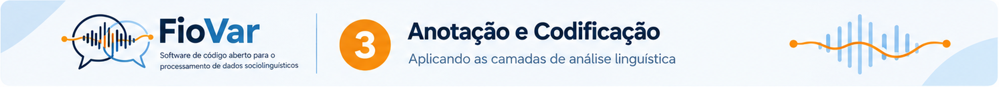

# **12. Preparação para anotação linguística**

Nesta etapa, vamos carregar o EAF revisado e selecionar os textos de uma trilha para a anotação linguística. Nenhuma etiqueta linguística será acrescentada ao arquivo neste momento.

## **12.1 Qual arquivo enviar?**

Utilize o EAF salvo após a revisão humana no ELAN, identificado pelo sufixo `_REV`.

```text
CarlosC_IDA62_GENHOM_ESCSUP_REV.eaf
```

`REV` indica que o arquivo passou por revisão humana. Preserve o EAF anterior e mantenha o pseudônimo e os códigos sociais sem alterações.

Ao executar o código, selecione apenas o EAF revisado. Por padrão, ele procura a trilha identificada exatamente como `S1`, com letra maiúscula e sem espaços.

## **12.2 Como selecionar outra trilha?**

Para preparar outra trilha, como `S2`, localize a seção “2. LOCALIZAR A TRILHA S1” no código e encontre a linha abaixo.

```python
if trilha.get("TIER_ID") == "S1"
```

Substitua apenas `"S1"` por `"S2"`.

```python
if trilha.get("TIER_ID") == "S2"
```

O nome deve corresponder exatamente ao da trilha no ELAN. A seleção considera esse nome, não a posição da trilha na tela.

Na versão atual, as mensagens e a variável `registros_s1` continuarão mencionando `S1`, mesmo que você selecione outra trilha. Essa variável guardará os dados da trilha escolhida. Preserve seu nome no código.

**Prepare e processe uma trilha por vez.** Executar novamente esta célula substitui os dados preparados anteriormente na memória.

Nas próximas etapas, confira também a seleção das trilhas. A escolha realizada aqui não configura automaticamente as demais células.

## **12.3 O que o código prepara?**

O código localiza a trilha selecionada, confere suas anotações e reúne o texto, o identificador e os tempos de cada trecho.

Essas informações ficam disponíveis na memória da sessão. A cópia do EAF preserva todas as trilhas e não registra, por si só, qual delas foi selecionada para a análise.

Clique em ▶ na célula de código abaixo e envie o EAF revisado na caixa que vai abrir na linha 175.

In [ ]:
from pathlib import Path
import xml.etree.ElementTree as ET
from google.colab import files

# ============================================================
# 1. ENVIAR O EAF REVISADO NO ELAN
# ============================================================

print("Envie o EAF revisado, com a trilha do participante chamada S1.")

enviados = files.upload()

if len(enviados) != 1:
    raise ValueError("Envie exatamente um arquivo EAF.")

nome, conteudo = next(iter(enviados.items()))

if Path(nome).suffix.lower() != ".eaf":
    raise ValueError("O arquivo deve ter extensão .eaf.")

try:
    raiz = ET.fromstring(conteudo)
except ET.ParseError as erro:
    raise ValueError(
        "Não foi possível ler o EAF. Confira o arquivo enviado."
    ) from erro

if raiz.tag != "ANNOTATION_DOCUMENT":
    raise ValueError(
        "O arquivo não apresenta a estrutura esperada de um EAF."
    )

# ============================================================
# 2. LOCALIZAR A TRILHA S1
# ============================================================

trilhas = [
    trilha
    for trilha in raiz.findall("TIER")
    if trilha.get("TIER_ID") == "S1"
]

if len(trilhas) != 1:
    raise ValueError(
        "O arquivo deve conter exatamente uma trilha S1."
    )

s1 = trilhas[0]

slots = {
    slot.get("TIME_SLOT_ID"): slot.get("TIME_VALUE")
    for slot in raiz.findall("./TIME_ORDER/TIME_SLOT")
}

# ============================================================
# 3. EXTRAIR TEXTOS E TEMPOS PARA A PRÓXIMA ETAPA
# ============================================================

registros = []
ids = set()

for ordem, anotacao in enumerate(
    s1.findall("ANNOTATION"), start=1
):
    item = anotacao.find("ALIGNABLE_ANNOTATION")

    if item is None:
        raise ValueError(
            "S1 contém anotação por referência. "
            "Esta etapa exige anotações diretamente alinhadas ao tempo."
        )

    identificador = item.get("ANNOTATION_ID")

    if not identificador or identificador in ids:
        raise ValueError(
            "Há um identificador ausente ou duplicado em S1."
        )

    ids.add(identificador)

    ref_inicio = item.get("TIME_SLOT_REF1")
    ref_fim = item.get("TIME_SLOT_REF2")

    for referencia in (ref_inicio, ref_fim):
        if referencia not in slots or slots[referencia] is None:
            raise ValueError(
                f"Vínculo temporal ausente em {identificador}."
            )

    try:
        inicio = int(slots[ref_inicio])
        fim = int(slots[ref_fim])
    except (TypeError, ValueError) as erro:
        raise ValueError(
            f"Valor temporal inválido em {identificador}."
        ) from erro

    if inicio < 0 or fim <= inicio:
        raise ValueError(
            f"Intervalo inválido em {identificador}."
        )

    registros.append({
        "ordem_original": ordem,
        "id": identificador,
        "inicio_ms": inicio,
        "fim_ms": fim,
        "duracao_ms": fim - inicio,
        "texto": item.findtext(
            "ANNOTATION_VALUE", default=""
        ),
    })

if not registros:
    raise ValueError("S1 não contém anotações.")

registros.sort(
    key=lambda registro: (
        registro["inicio_ms"],
        registro["fim_ms"],
        registro["ordem_original"],
    )
)

# Mantém os dados disponíveis para a próxima célula.
registros_s1 = registros

# ============================================================
# 4. PREPARAR O EAF COM A ETIQUETA ORIGINAL
# ============================================================

# Preserva a etiqueta, incluindo o sufixo REV.
nome_base = Path(nome).stem

# Evita acrescentar PRE_ETIQ novamente.
if not nome_base.endswith("_PRE_ETIQ"):
    nome_base += "_PRE_ETIQ"

nome_saida = f"{nome_base}.eaf"

# Não cria uma pasta de trabalho.
# Salva apenas a cópia temporária necessária ao download.
caminho_eaf_saida = Path(nome_saida)

if caminho_eaf_saida.exists():
    if caminho_eaf_saida.read_bytes() != conteudo:
        raise FileExistsError(
            f"Já existe outro arquivo chamado {nome_saida} no Colab. "
            "Confira as versões antes de continuar."
        )
else:
    # Copia o conteúdo integral, sem alterar as trilhas.
    caminho_eaf_saida.write_bytes(conteudo)

# ============================================================
# 5. CONFERIR E BAIXAR DIRETAMENTE O EAF
# ============================================================

print("Preparação concluída!")
print("Arquivo:", nome_saida)
print("Anotações extraídas:", len(registros_s1))
print(
    "Textos vazios:",
    sum(
        not registro["texto"].strip()
        for registro in registros_s1
    ),
)
print("Todas as trilhas do EAF foram preservadas.")
print("O Stanza ainda não foi executado.")
print("Textos e tempos estão disponíveis em registros_s1.")
print("Salve o EAF na pasta de trabalho do seu computador.")

files.download(str(caminho_eaf_saida))

## **12.4 Qual resultado esperar?**

Ao concluir, aparecerá “Preparação concluída!”, seguida da quantidade de anotações extraídas e de textos vazios encontrados.

O código também disponibilizará uma cópia integral do EAF com o sufixo `_PRE_ETIQ`.

```text
CarlosC_IDA62_GENHOM_ESCSUP_REV_PRE_ETIQ.eaf
```

`PRE_ETIQ` significa “preparado para a etiquetagem”. Ele sinaliza que a etapa de preparação foi realizada. Não significa que o arquivo já recebeu etiquetas linguísticas.

Salve o arquivo no computador para utilizá-lo na próxima etapa.

# **13. Etiquetagem morfológica e sintática**

Nesta etapa, o Stanza realizará a anotação morfossintática das transcrições nas trilhas selecionadas. Os resultados serão acrescentados ao arquivo EAF em novas trilhas, preservando as anotações originais.

A etiquetagem morfológica atribuirá às palavras categorias gramaticais e traços morfológicos, como gênero, número, pessoa, tempo e modo, conforme a análise produzida pelo modelo. A análise sintática identificará relações de dependência entre as palavras, como as de sujeito, objeto e modificador em relação aos seus respectivos núcleos.

As anotações serão produzidas automaticamente e deverão ser revisadas, considerando as particularidades da fala transcrita e os objetivos da pesquisa.

## **13.1 Como preparar o Stanza?**

Execute a célula de código a seguir para instalar o Stanza, baixar os modelos de português e carregar o analisador.

Aguarde a mensagem “Modelo de português carregado.” antes de executar a célula seguinte. O download dos modelos pode levar alguns minutos.

Essa configuração utiliza a CPU, mesmo que uma GPU esteja disponível.

In [13]:
# ============================================================
# 1. INSTALAR O STANZA
# ============================================================

%pip install -q stanza

# ============================================================
# 2. IMPORTAR A BIBLIOTECA
# ============================================================

import stanza

# ============================================================
# 3. DEFINIR AS ETAPAS DA ANÁLISE LINGUÍSTICA
# ============================================================

# tokenize: separar o texto em sentenças e unidades de análise.
# mwt: expandir unidades que representam mais de uma palavra.
# pos: atribuir classes gramaticais e características morfológicas.
# lemma: identificar a forma de referência de cada palavra.
# depparse: identificar relações sintáticas entre as palavras.

PROCESSADORES = "tokenize,mwt,pos,lemma,depparse"

# ============================================================
# 4. BAIXAR OS MODELOS PARA PORTUGUÊS
# ============================================================

stanza.download(
    lang="pt",
    processors=PROCESSADORES
)

# ============================================================
# 5. CARREGAR O ANALISADOR LINGUÍSTICO
# ============================================================

# O analisador será utilizado pela próxima célula.
# use_gpu=False configura esta etapa para utilizar a CPU.

nlp = stanza.Pipeline(
    lang="pt",
    processors=PROCESSADORES,
    use_gpu=False
)

# ============================================================
# 6. CONFIRMAR O CARREGAMENTO
# ============================================================

print("Modelo de português carregado.")

INFO:stanza:Downloaded file to /root/.cache/stanza/1.15.0/resources/resources.json
INFO:stanza:Downloading these customized packages for language: pt (Portuguese)...
| Processor       | Package         |
-------------------------------------
| tokenize        | bosque_nocharlm |
| mwt             | bosque          |
| pos             | bosque_charlm   |
| lemma           | bosque_nocharlm |
| depparse        | bosque_charlm   |
| pretrain        | conll17         |
| forward_charlm  | oscar2023       |
| backward_charlm | oscar2023       |



models/tokenize/bosque_nocharlm.pt:   0%|          | 0.00/637k [00:00<?, ?B/s]

INFO:stanza:Downloaded file to /root/.cache/stanza/1.15.0/resources/pt/tokenize/bosque_nocharlm.pt


models/mwt/bosque.pt:   0%|          | 0.00/597k [00:00<?, ?B/s]

INFO:stanza:Downloaded file to /root/.cache/stanza/1.15.0/resources/pt/mwt/bosque.pt


models/pos/bosque_charlm.pt:   0%|          | 0.00/33.5M [00:00<?, ?B/s]

... (9 outputs left out)

models/backward_charlm/oscar2023.pt:   0%|          | 0.00/30.3M [00:00<?, ?B/s]

INFO:stanza:Downloaded file to /root/.cache/stanza/1.15.0/resources/pt/backward_charlm/oscar2023.pt
INFO:stanza:Finished downloading models and saved to /root/.cache/stanza/1.15.0/resources
INFO:stanza:Checking for updates to resources.json in case models have been updated.  Note: this behavior can be turned off with download_method=None or download_method=DownloadMethod.REUSE_RESOURCES


INFO:stanza:Downloaded file to /root/.cache/stanza/1.15.0/resources/resources.json
INFO:stanza:Loading these models for language: pt (Portuguese):
| Processor | Package         |
-------------------------------
| tokenize  | bosque_nocharlm |
| mwt       | bosque          |
| pos       | bosque_charlm   |
| lemma     | bosque_nocharlm |
| depparse  | bosque_charlm   |

INFO:stanza:Using device: cpu
INFO:stanza:Loading: tokenize
INFO:stanza:Loading: mwt
INFO:stanza:Loading: pos
INFO:stanza:Loading: lemma
INFO:stanza:Loading: depparse
INFO:stanza:Done loading processors!


Modelo de português carregado.


## **13.2 Aplicar a análise ao EAF preparado**

Antes de executar, confira se a célula anterior terminou com a mensagem “Modelo de português carregado.” Mantenha a mesma sessão do Colab.

No início do código, indique quais trilhas serão analisadas:

```python
TRILHAS_ALVO = ["S1"]
```

Para analisar outra trilha, substitua `"S1"` pelo nome correspondente. Para incluir mais de uma, utilize, por exemplo, `["S1", "S2"]`. Os nomes devem ser exatamente iguais aos do ELAN.

Depois, clique em ▶ e envie o EAF gerado na etapa 12, com o final `_REV_PRE_ETIQ.eaf`.

In [ ]:
# ============================================================
# 1. IMPORTAR RECURSOS E ESCOLHER AS TRILHAS
# ============================================================

import io
import re
import xml.etree.ElementTree as ET
from pathlib import Path
from google.colab import files

# Informe os nomes exatos das trilhas que deseja analisar.
TRILHAS_ALVO = ["S1"]

if "nlp" not in globals():
    raise RuntimeError(
        "Execute primeiro a célula que carrega o Stanza."
    )

if (
    not TRILHAS_ALVO
    or any(
        not isinstance(t, str) or not t.strip()
        for t in TRILHAS_ALVO
    )
    or len(set(TRILHAS_ALVO)) != len(TRILHAS_ALVO)
):
    raise ValueError(
        "Informe uma lista de nomes de trilhas sem repetições."
    )

# ============================================================
# 2. ENVIAR E LER O EAF REVISADO
# ============================================================

print("Selecione um único EAF revisado, ainda sem análises do Stanza.")

enviados = files.upload()

if len(enviados) != 1:
    raise ValueError("Envie exatamente um arquivo EAF.")

nome, conteudo = next(iter(enviados.items()))

if Path(nome).suffix.lower() != ".eaf":
    raise ValueError("O arquivo deve ter extensão .eaf.")

# Preservar comentários e instruções de processamento do XML.
parser = ET.XMLParser(
    target=ET.TreeBuilder(
        insert_comments=True,
        insert_pis=True,
    )
)

raiz = ET.parse(
    io.BytesIO(conteudo),
    parser=parser,
).getroot()

if raiz.tag != "ANNOTATION_DOCUMENT":
    raise ValueError("Estrutura de EAF não reconhecida.")

# ============================================================
# 3. CONFERIR TRILHAS, ANOTAÇÕES E TEMPOS
# ============================================================

trilhas = {}

for trilha in raiz.findall("TIER"):
    identificador = trilha.get("TIER_ID")

    if not identificador or identificador in trilhas:
        raise ValueError("Nome de trilha ausente ou repetido.")

    trilhas[identificador] = trilha

anotacoes = {}

for item in raiz.findall("./TIER/ANNOTATION/*"):
    identificador = item.get("ANNOTATION_ID")

    if not identificador or identificador in anotacoes:
        raise ValueError("ID de anotação ausente ou repetido.")

    anotacoes[identificador] = item

ids_usados = set(anotacoes)

slots = {
    item.get("TIME_SLOT_ID"): item.get("TIME_VALUE")
    for item in raiz.findall("./TIME_ORDER/TIME_SLOT")
}

# Guardar as trilhas originais para conferência.
originais = [
    ET.tostring(trilha)
    for trilha in raiz.findall("TIER")
]

for nome_trilha in TRILHAS_ALVO:
    if nome_trilha not in trilhas:
        raise ValueError(f"Trilha ausente: {nome_trilha}")

    for sufixo in ("palavras", "morfologia", "sintaxe", "lemas"):
        nome_nova_trilha = f"{nome_trilha}_{sufixo}"

        if nome_nova_trilha in trilhas:
            raise ValueError(
                f"A trilha {nome_nova_trilha} já existe. "
                "Envie o EAF anterior à inclusão das análises "
                "do Stanza."
            )

    for wrapper in trilhas[nome_trilha].findall("ANNOTATION"):
        itens = list(wrapper)

        if (
            len(itens) != 1
            or itens[0].tag != "ALIGNABLE_ANNOTATION"
        ):
            raise ValueError(
                f"{nome_trilha} deve conter apenas anotações "
                "diretamente alinhadas ao tempo."
            )

        item = itens[0]
        identificador = item.get("ANNOTATION_ID")

        try:
            inicio = int(slots[item.get("TIME_SLOT_REF1")])
            fim = int(slots[item.get("TIME_SLOT_REF2")])
        except (KeyError, TypeError, ValueError) as erro:
            raise ValueError(
                f"Tempo ausente ou inválido em {identificador}."
            ) from erro

        if inicio < 0 or fim <= inicio:
            raise ValueError(
                f"Intervalo inválido em {identificador}."
            )

if not raiz.findall("LINGUISTIC_TYPE"):
    raise ValueError("O EAF não contém tipos linguísticos.")

# ============================================================
# 4. CRIAR IDENTIFICADORES SEM REPETIÇÕES
# ============================================================

contadores = {}


def novo_id(prefixo, usados):
    """Criar um ID numerado que ainda não exista."""
    numero = contadores.get(prefixo, 0) + 1

    while f"{prefixo}_{numero}" in usados:
        numero += 1

    contadores[prefixo] = numero
    identificador = f"{prefixo}_{numero}"
    usados.add(identificador)

    return identificador


tipos_usados = {
    tipo.get("LINGUISTIC_TYPE_ID")
    for tipo in raiz.findall("LINGUISTIC_TYPE")
}

tipo_palavras = novo_id("stanza_palavras", tipos_usados)
tipo_atributos = novo_id("stanza_atributos", tipos_usados)

# ============================================================
# 5. DEFINIR OS VÍNCULOS DAS NOVAS TRILHAS
# ============================================================

# Palavras: subdivisões simbólicas do trecho original.
# Não são criados tempos individuais para as palavras.
novos_tipos = [
    ET.Element(
        "LINGUISTIC_TYPE",
        LINGUISTIC_TYPE_ID=tipo_palavras,
        TIME_ALIGNABLE="false",
        GRAPHIC_REFERENCES="false",
        CONSTRAINTS="Symbolic_Subdivision",
    ),
    ET.Element(
        "LINGUISTIC_TYPE",
        LINGUISTIC_TYPE_ID=tipo_atributos,
        TIME_ALIGNABLE="false",
        GRAPHIC_REFERENCES="false",
        CONSTRAINTS="Symbolic_Association",
    ),
]


def adicionar_referencia(
    trilha, identificador, pai, texto, anterior=None
):
    """Criar uma anotação vinculada a outra anotação."""
    dados = {
        "ANNOTATION_ID": identificador,
        "ANNOTATION_REF": pai,
    }

    if anterior is not None:
        dados["PREVIOUS_ANNOTATION"] = anterior

    wrapper = ET.SubElement(trilha, "ANNOTATION")
    item = ET.SubElement(wrapper, "REF_ANNOTATION", dados)

    ET.SubElement(
        item, "ANNOTATION_VALUE"
    ).text = texto

# ============================================================
# 6. ANALISAR CADA TRILHA COM O STANZA
# ============================================================

novas_trilhas = []

for nome_trilha in TRILHAS_ALVO:
    palavras = ET.Element(
        "TIER",
        TIER_ID=f"{nome_trilha}_palavras",
        PARENT_REF=nome_trilha,
        LINGUISTIC_TYPE_REF=tipo_palavras,
    )

    atributos = {}

    for sufixo in ("morfologia", "sintaxe"):
        atributos[sufixo] = ET.Element(
            "TIER",
            TIER_ID=f"{nome_trilha}_{sufixo}",
            PARENT_REF=f"{nome_trilha}_palavras",
            LINGUISTIC_TYPE_REF=tipo_atributos,
        )

    total_palavras = 0
    trechos_vazios = 0

    for wrapper in trilhas[nome_trilha].findall("ANNOTATION"):
        trecho = wrapper.find("ALIGNABLE_ANNOTATION")
        id_trecho = trecho.get("ANNOTATION_ID")

        texto = trecho.findtext(
            "ANNOTATION_VALUE",
            default="",
        )

        if not texto.strip():
            trechos_vazios += 1
            continue

        documento = nlp(texto)
        anterior = None

        for numero_sentenca, sentenca in enumerate(
            documento.sentences,
            start=1,
        ):
            mapa_ids = {
                palavra.id: novo_id("stanza_p", ids_usados)
                for palavra in sentenca.words
            }

            mapa_textos = {
                palavra.id: palavra.text
                for palavra in sentenca.words
            }

            for palavra in sentenca.words:
                id_palavra = mapa_ids[palavra.id]

                adicionar_referencia(
                    palavras,
                    id_palavra,
                    id_trecho,
                    palavra.text,
                    anterior,
                )

                anterior = id_palavra

                morfologia = f"UPOS={palavra.upos or '_'}"

                if palavra.xpos:
                    morfologia += f" | XPOS={palavra.xpos}"

                if palavra.feats:
                    morfologia += f" | {palavra.feats}"

                if palavra.head == 0:
                    texto_nucleo = "ROOT"
                    id_nucleo = "ROOT"
                else:
                    texto_nucleo = mapa_textos[palavra.head]
                    id_nucleo = mapa_ids[palavra.head]

                sintaxe = (
                    f"rel={palavra.deprel or '_'}"
                    f" | nucleo={texto_nucleo}"
                    f" | id_nucleo={id_nucleo}"
                    f" | sentenca={numero_sentenca}"
                )

                valores = {
                    "morfologia": morfologia,
                    "sintaxe": sintaxe,
                }

                for sufixo, valor in valores.items():
                    adicionar_referencia(
                        atributos[sufixo],
                        novo_id("stanza_a", ids_usados),
                        id_palavra,
                        valor,
                    )

                total_palavras += 1

    novas_trilhas.extend([
        palavras,
        atributos["morfologia"],
        atributos["sintaxe"],
    ])

    print(f"\nTrilha: {nome_trilha}")
    print(f"Palavras analisadas: {total_palavras}")
    print(f"Trechos vazios ignorados: {trechos_vazios}")

# ============================================================
# 7. INSERIR AS NOVAS TRILHAS E OS TIPOS NO EAF
# ============================================================

posicao = max(
    i for i, elemento in enumerate(raiz)
    if elemento.tag == "TIER"
) + 1

for trilha in novas_trilhas:
    raiz.insert(posicao, trilha)
    posicao += 1

posicao = max(
    i for i, elemento in enumerate(raiz)
    if elemento.tag == "LINGUISTIC_TYPE"
) + 1

for tipo in novos_tipos:
    raiz.insert(posicao, tipo)
    posicao += 1

restricoes = {
    "Symbolic_Subdivision":
        "Ordered symbolic subdivision of a parent annotation",
    "Symbolic_Association":
        "One-to-one symbolic association with a parent annotation",
}

existentes = {
    item.get("STEREOTYPE")
    for item in raiz.findall("CONSTRAINT")
}

for nome_restricao, descricao in restricoes.items():
    if nome_restricao in existentes:
        continue

    posicao = next(
        (
            i for i, elemento in enumerate(raiz)
            if elemento.tag in {
                "CONTROLLED_VOCABULARY",
                "LEXICON_REF",
                "EXTERNAL_REF",
            }
        ),
        len(raiz),
    )

    raiz.insert(
        posicao,
        ET.Element(
            "CONSTRAINT",
            STEREOTYPE=nome_restricao,
            DESCRIPTION=descricao,
        ),
    )

# ============================================================
# 8. CONFERIR A PRESERVAÇÃO DAS TRILHAS ORIGINAIS
# ============================================================

quantidade_originais = len(originais)

depois = [
    ET.tostring(trilha)
    for trilha in raiz.findall("TIER")[:quantidade_originais]
]

if originais != depois:
    raise RuntimeError("Uma trilha original foi alterada.")

todos_ids = {
    item.get("ANNOTATION_ID")
    for item in raiz.findall("./TIER/ANNOTATION/*")
}

for item in raiz.findall("./TIER/ANNOTATION/REF_ANNOTATION"):
    if item.get("ANNOTATION_REF") not in todos_ids:
        raise RuntimeError("Referência de anotação inexistente.")

    anterior = item.get("PREVIOUS_ANNOTATION")

    if anterior is not None and anterior not in todos_ids:
        raise RuntimeError("Referência de sequência inexistente.")

# ============================================================
# 9. AJUSTAR O NOME, SALVAR E BAIXAR SOMENTE O EAF
# ============================================================

nome_base = Path(nome).stem

# Remover numerações de cópia: (1), (2), etc.
nome_base = re.sub(r"\s*\(\d+\)", "", nome_base).strip()

# Padronizar Rev/rev como REV.
nome_base = re.sub(
    r"(^|_)rev(?=_|$)",
    r"\1REV",
    nome_base,
    flags=re.IGNORECASE,
)

# Remover terminações antigas para não repetir STZ.
nome_base = re.sub(
    r"(?:_stanza_sem_lemas|_stanza|_STZ)+$",
    "",
    nome_base,
    flags=re.IGNORECASE,
)

destino = Path(f"{nome_base}_STZ.eaf")

ET.ElementTree(raiz).write(
    destino,
    encoding="utf-8",
    xml_declaration=True,
)

ET.parse(destino)

print("Arquivo gerado:", destino.name)
files.download(str(destino))

## **13.3 Quais trilhas serão criadas?**

Para cada trilha selecionada, serão acrescentadas três novas trilhas. Para `S1`, serão criadas as seguintes.

- `S1_palavras`, com as unidades de palavra produzidas pelo analisador.
- `S1_morfologia`, com as classes gramaticais e características morfológicas de cada palavra.
- `S1_sintaxe`, com a relação sintática e a indicação da palavra à qual cada unidade se vincula.

As palavras ficam vinculadas aos segmentos originais. Nesta etapa, não são criados tempos individuais de início e fim para cada palavra.

## **13.4 Qual resultado esperar?**

Durante a execução, serão exibidas a quantidade de palavras analisadas e a de trechos vazios ignorados em cada trilha.

Ao concluir, o navegador solicitará o download direto do EAF. O código manterá a etiqueta do arquivo e acrescentará `_STZ`, indicando a inclusão das análises do Stanza.

```text
CarlosC_IDA62_GENHOM_ESCSUP_REV_PRE_ETIQ_STZ.eaf
```

Salve o resultado na pasta de trabalho e preserve o arquivo da etapa anterior. Para ouvir a gravação no ELAN, mantenha o WAV correspondente disponível.

## **13.5 O que precisa ser revisado?**

As etiquetas são sugestões automáticas e podem apresentar erros, especialmente em trechos com hesitações, interrupções, formas não convencionais ou pontuação ambígua.

Confira as classes gramaticais, as características morfológicas e as relações sintáticas conforme os critérios da pesquisa.

As unidades produzidas pelo analisador também podem diferir da escrita original, por exemplo, ao separar contrações.

# **14. Etiquetagem fonológica-ortográfica com o SILAC**

Nesta etapa, utilizaremos o SILAC para produzir uma representação fonológica a partir da escrita das palavras.

O SILAC aplica regras de conversão ao texto, incluindo marcações de sílabas e sua tonicidade.

Essa representação é uma previsão baseada na escrita. Ela não resulta da escuta do áudio e não confirma como o participante pronunciou cada palavra.

## **14.1 Como instalar o R?**

O SILAC foi desenvolvido em R, uma linguagem de programação. Por isso, precisamos instalar os recursos que permitem executar seus comandos no Colab.

Clique em ▶ na célula de código abaixo e aguarde a instalação terminar. Ela acontece no ambiente do Colab, não no seu computador.

Não é necessário conhecer R nem alterar os comandos.

In [15]:
# ============================================================
# 1. INSTALAR O R PARA EXECUTAR O SILAC
# ============================================================

!apt-get -qq update
!apt-get -qq install -y r-base-core

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
(Reading database ... 127324 files and directories currently installed.)
Preparing to unpack .../r-base-core_4.6.2-1.2404.0_amd64.deb ...
Unpacking r-base-core (4.6.2-1.2404.0) over (4.6.1-9.2404.0) ...
Preparing to unpack .../r-base_4.6.2-1.2404.0_all.deb ...
Unpacking r-base (4.6.2-1.2404.0) over (4.6.1-9.2404.0) ...
Preparing to unpack .../r-recommended_4.6.2-1.2404.0_all.deb ...
Unpacking r-recommended (4.6.2-1.2404.0) over (4.6.1-9.2404.0) ...
Preparing to unpack .../r-base-dev_4.6.2-1.2404.0_all.deb ...
Unpacking r-base-dev (4.6.2-1.2404.0) over (4.6.1-9.2404.0) ...
Setting up r-base-core (4.6.2-1.2404.0) ...
Installing new version of config file /etc/R/Makeconf ...
Replacing config file /etc/R/Renviron with new version
Setting up r-recommended (4.6.2-1.2404.0) ...
Setting up r-base-dev (4.6.2-

## **14.2 Como preparar os recursos do SILAC?**

Depois da instalação do R, execute a próxima célula de código.

Ela prepara as regras de conversão do SILAC e a função `executar_silac`, que será utilizada para analisar as palavras. Uma função é um conjunto de comandos reunidos para realizar uma tarefa.

As regras e os arquivos de apoio já estão incluídos na célula. Não é necessário copiá-los, editá-los ou enviá-los separadamente.

Esta célula ainda não solicita o EAF nem produz um arquivo de resultados para download.

In [17]:
# ============================================================
# 1. IMPORTAR OS RECURSOS
# ============================================================

from pathlib import Path
import csv
import subprocess

# ============================================================
# 2. DEFINIR A FUNÇÃO QUE EXECUTA O SILAC
# ============================================================

def executar_silac(tokens, r_source, key_path, out):
    lexical = [t for t in tokens if t["lexical"]]

    source = Path(r_source).read_text(
        encoding="utf-8-sig"
    )

    url = (
        "https://raw.githubusercontent.com/oushiro/"
        "silac/master/chave_fonologica_utf8.csv"
    )

    if source.count(url) != 1:
        raise ValueError(
            "Versão SILAC diferente: conferir leitura "
            "da chave antes de executar."
        )

    local_key = str(
        Path(key_path).resolve()
    ).replace("\\", "/")

    source = source.replace(url, local_key)

    patched = out / "silac_local.R"

    patched.write_text(
        source,
        encoding="utf-8"
    )

    entrada = out / "silac_entrada.csv"

    with entrada.open(
        "w",
        encoding="utf-8",
        newline=""
    ) as arquivo:
        writer = csv.writer(arquivo)
        writer.writerow(["token"])

        writer.writerows(
            [[t["text"]] for t in lexical]
        )

    runner = out / "executar_silac.R"

    runner.write_text(
        '''args <- commandArgs(trailingOnly=TRUE)
source(args[1], encoding="UTF-8")
entrada <- read.csv(args[2], stringsAsFactors=FALSE, fileEncoding="UTF-8")
resultado <- silac(as.character(entrada$token))
if (length(resultado) != nrow(entrada)) stop("SILAC mudou a quantidade de registros")
write.csv(data.frame(fonologia=resultado), args[3], row.names=FALSE, fileEncoding="UTF-8", na="")
''',
        encoding="utf-8"
    )

    result_path = out / "silac_saida.csv"

    subprocess.run(
        [
            "Rscript",
            str(runner),
            str(patched),
            str(entrada),
            str(result_path),
        ],
        check=True
    )

    with result_path.open(
        encoding="utf-8-sig",
        newline=""
    ) as arquivo:
        results = list(csv.DictReader(arquivo))

    if len(results) != len(lexical):
        raise ValueError(
            "Quantidade de resultados SILAC divergente."
        )

    for token, resultado in zip(lexical, results):
        token["phon"] = resultado["fonologia"]

        if not token["phon"].strip():
            raise ValueError(
                f"SILAC vazio para {token['text']!r}."
            )

        token["silac_review"] = (
            "rever_hifen_ou_expansao"
            if (
                "-" in token["text"]
                or " " in token["phon"].strip()
            )
            else ""
        )

# ============================================================
# 3. PREPARAR O CÓDIGO DO SILAC
# ============================================================

Path("silacShiny.R").write_text(
    r'''
silac <- function(data = data()){

  ###silac
  transc<-gsub("\\?|\\!|\\.|\\'|\"|\\{|\\}|\\(|\\)|\\/|\\[|\\]|\\,", "", data)#nao consegui colocar backslash
  transc<-gsub("-", " ", transc) #<---- novo
  transc<-gsub("  ", " ", transc) #<---- novo
  transc<-tolower(transc); head(transc,30)

  #marcacoes de silabas##
  #marcar - apos todas as vogais
  apagar<-gsub("(a|ã|á|â|à|e|ê|é|i|í|o|õ|ó|ô|u|ú)", "\\1-", transc, ignore.case=T)

  #ajustar marcacoes
  #as regras abaixo valem para o corpus do SP2010;
  #outros corpora podem conter outras palavras em que
  #as regras abaixo precisam ser ajustadas

  #eliminar consoantes duplas
  apagar<-gsub("bb", "b", apagar, ignore.case=T)
  apagar<-gsub("dd", "d", apagar, ignore.case=T)
  apagar<-gsub("ff", "f", apagar, ignore.case=T)
  apagar<-gsub("gg", "g", apagar, ignore.case=T)
  apagar<-gsub("hh", "h", apagar, ignore.case=T)
  apagar<-gsub("ll", "l", apagar, ignore.case=T)
  apagar<-gsub("mm", "m", apagar, ignore.case=T)
  apagar<-gsub("nn", "n", apagar, ignore.case=T)
  apagar<-gsub("pp", "p", apagar, ignore.case=T)
  apagar<-gsub("tt", "t", apagar, ignore.case=T)
  apagar<-gsub("zz", "z", apagar, ignore.case=T)
  apagar<-gsub("cc", "kI-s", apagar, ignore.case=T)

  #ditongos decrescentes
  apagar<-gsub("(a|ã|á|â|e|ê|é|o|õ|ó|ô|i|u)-(i|u|y|h)", "\\1\\2", apagar, ignore.case=T)
  apagar<-gsub("(a|ã|á|â|e|ê|é|o|õ|ó|ô|i|u)-(i|u|y|h)", "\\1\\2", apagar, ignore.case=T)

  #ditongos crescentes
  apagar<-gsub("(u|ã|õ)-(a|ã|á|â|e|ê|é|o|õ|ó|ô|i|u|h)", "\\1\\2", apagar, ignore.case=T)
  apagar<-gsub("(i)-(a|o)", "\\1\\2", apagar, ignore.case=T)

  #silabas com coda
  apagar<-gsub("(a|ã|á|â|e|ê|é|i|í|o|õ|ó|ô|u|ú)-(r|s|l|m|n|z|x)(b|c|ç|d|f|g|j|k|p|q|t|v|x|z|s|m|n|l|\\W|$)", "\\1\\2-\\3", apagar, ignore.case=T)
  apagar<-gsub("(a|ã|á|â|e|ê|é|i|í|o|õ|ó|ô|u|ú)-([ns])(r)", "\\1\\2-\\3", apagar, ignore.case=T) #<----- novo
  apagar<-gsub("i(a|o)(r|n|l)", "i-\\1\\2", apagar, ignore.case=T)
  apagar<-gsub("(a|ã|á|â|e|ê|é|i|í|o|õ|ó|ô|u|ú)-(r)(s)(b|c|ç|d|f|g|h|j|k|p|q|t|v|x|z|\\W)", "\\1\\2\\3-\\4", apagar, ignore.case=T)

  #silabas com coda seguidas de consoante -s
  apagar<-gsub("(a|ã|á|â|e|ê|é|i|í|o|õ|ó|ô|u|ú)-(r)(s)(a|ã|á|â|e|ê|é|i|í|o|õ|ó|ô|u|ú)", "\\1\\2-\\3\\4", apagar, ignore.case=T)
  apagar<-gsub("(a|ã|á|â|e|ê|é|i|í|o|õ|ó|ô|u|ú)(n)-(s)(b|c|ç|d|f|g|h|j|k|l|m|p|q|t|v|x|z|\\W)", "\\1\\2\\3-\\4", apagar, ignore.case=T)

  #encontro consonantal (mudar pra baixo com epentese?)
  apagar<-gsub("-(b|c|ç|d|f|g|j|k|p|q|t|v|x|z)(b|c|ç|d|f|g|j|k|p|q|t|v|x|z)", "-\\1-\\2", apagar, ignore.case=T)

  #juntar rr, ss, sc/ç, nh, lh
  apagar<-gsub("(r)-(r)", "-\\1\\2", apagar, ignore.case=T)
  apagar<-gsub("(s)-(s)", "-\\1\\2", apagar, ignore.case=T)
  apagar<-gsub("s-c(i|í|e|ê|é)", "-sc\\1", apagar, ignore.case=T)
  apagar<-gsub("s-ç(o|a)", "-sç\\1", apagar, ignore.case=T)
  apagar<-gsub("(n|l)-h", "-\\1h", apagar, ignore.case=T)

  #eliminar hifen de fins de palavra
  apagar<-gsub("-(\\W|$)", "\\1", apagar, ignore.case=T)

  #excecoes (palavras estrangeiras)
  apagar<-gsub("in-gs\\b", "ins", apagar, ignore.case=T)
  apagar<-gsub("in-g\\b", "in", apagar, ignore.case=T)
  apagar<-gsub("c-k", "k", apagar, ignore.case=T)

  #coda complexa (mudar pra cima?)
  apagar<-gsub("(u)(a|o)(r|n|l)", "\\1-\\2\\3", apagar, ignore.case=T)
  apagar<-gsub("(q|g)u-a(r|n|l)", "\\1ua\\2", apagar, ignore.case=T)
  apagar<-gsub("(i|u)ais\\b", "\\1-ais", apagar, ignore.case=T)
  apagar<-gsub("uo-", "u-o", apagar, ignore.case=T)

  #tritongos e ditongos
  apagar<-gsub("([aeo])ia", "\\1i-a", apagar, ignore.case=T)
  apagar<-gsub("oio", "oi-o", apagar, ignore.case=T)
  apagar<-gsub("ain", "a-in", apagar, ignore.case=T)
  apagar<-gsub("([qg])u-í", "\\1uí", apagar, ignore.case=T)
  apagar<-gsub("i([ao])-", "i-\\1-", apagar, ignore.case=T)
  apagar<-gsub("([bcçdfjklmnprstvxz])u([aeo])", "\\1u-\\2", apagar, ignore.case=T)
  apagar<-gsub("([bcçdfjklmnprstvxz])ui([rnmuz])", "\\1u-i\\2", apagar, ignore.case=T)
  apagar<-gsub("aiu", "a-iu", apagar, ignore.case=T)

  #itens lexicais especificos
  apagar<-gsub("mpb", "e-me-pe-bÊ", apagar, ignore.case=T)
  apagar<-gsub("dvd", "de-ve-dÊ", apagar, ignore.case=T)
  apagar<-gsub("cpe", "ci-pi-Í", apagar, ignore.case=T)
  apagar<-gsub("bahia", "ba-hia", apagar, ignore.case=T)

  #epentese
  apagar<-gsub("(b|c|d|f|g|k|p|t)s\\b", "\\1Is", apagar)
  apagar<-gsub("bst", "bIs-t", apagar)
# apagar<-gsub("n-s-(m|b|c|f|g|l|p|t|v)", "ns-\\1", apagar)
  apagar<-gsub("\\bs([kmpt])", "Is-\\1", apagar, ignore.case=T)
  apagar<-gsub("(b|d|f|g|k|p|t)(b|c|d|f|g|j|k|m|n|p|q|s|t|v|x|z)", "\\1I-\\2", apagar)
  apagar<-gsub("c(b|c|d|f|g|j|k|m|n|p|q|s|t|v|x|z)", "kI-\\1", apagar)
  apagar<-gsub("-(b|d|f|g|k|p|t)\\b", "-\\1I", apagar)
  apagar<-gsub("-c-", "-kI-", apagar)
  apagar<-gsub("-(s|z)\\b", "\\1", apagar)
  apagar<-gsub("reu-", "re-u-", apagar)
  apagar<-gsub("iam\\b", "i-am", apagar)
  apagar<-gsub("ã-o", "ão", apagar)
  apagar<-gsub("a-o(s)?\b", "ao\\1", apagar)
  apagar<-gsub("quios-", "qui-os-", apagar)
  apagar<-gsub("([oae])i([mnr])", "\\1-i\\2", apagar)
  apagar<-gsub("iu([mnr])", "i-u\\1", apagar)
  apagar<-gsub("([oaeã])(i-nh)", "\\1-\\2", apagar)
  apagar<-gsub("([aeo])i([ao])", "\\1i-\\2", apagar)
  apagar<-gsub("i([oa])u", "i-\\1u", apagar)
  apagar<-gsub("([pash])u([áãâéêíóôú])", "\\1u-\\2", apagar)
  apagar<-gsub("proi-b", "pro-i-b", apagar)
  apagar<-gsub("nui-da-de", "nu-i-da-de", apagar)
  apagar<-gsub("jui-za-", "ju-i-za-", apagar)
  apagar<-gsub("e-gois-ti", "e-go-is-ti", apagar)
  apagar<-gsub("hai-ti", "ha-i-ti", apagar)
  apagar<-gsub("hai-ti", "ha-i-ti", apagar)
  apagar<-gsub("miu-de", "mi-u-de", apagar)
  apagar<-gsub("rui-nh", "ru-i-nh", apagar)
  apagar<-gsub("raiz", "ra-iz", apagar)
  apagar<-gsub("coha-b", "co-ha-b", apagar)
  apagar<-gsub("os([oa])(s)?\\b", "o-s\\1\\2", apagar)
  apagar<-gsub("per-Is-p", "pers-p", apagar)
  apagar<-gsub("(s-p)\\b", "\\1I", apagar)
  apagar<-gsub("u-ni-cam-p", "u-ni-cam-pI", apagar)
  apagar<-gsub("fa-a-p", "fa-a-pI", apagar)
  apagar<-gsub("in-ter-ne-t", "in-ter-ne-tI", apagar)
  apagar<-gsub("i-po-d", "i-po-dI", apagar)
  apagar<-gsub("ner-d", "ner-dI", apagar)
  apagar<-gsub("chi-p", "chi-pI", apagar)
  apagar<-gsub("ca-tI-chu-p", "ca-tI-chu-pI", apagar)
  apagar<-gsub("ci-ne-mar-k", "ci-ne-mar-kI", apagar)
  apagar<-gsub("cul-t\\b", "cul-tI", apagar)
  apagar<-gsub("me-c\\b", "me-kI", apagar)
  apagar<-gsub("u-ni-ci-d", "u-ni-ci-dI", apagar)
  apagar<-gsub("boyzi", "boy-zi", apagar)
  apagar<-gsub("gaydar", "gay-dar", apagar)
  apagar<-gsub("gayzi", "gay-zi", apagar)
  apagar<-gsub("playboy", "play-boy", apagar)
  apagar<-gsub("playground", "play-ground", apagar)
  apagar<-gsub("toyo-", "toy-o", apagar)
  apagar<-gsub("f(r)?ios\\b", "f\\1i-os", apagar)
  apagar<-gsub("\\bfria(s)?", "fri-a\\1", apagar)
  apagar<-gsub("\\bfria(s)?", "fri-a\\1", apagar)
  apagar<-gsub("\\bju-di([ao])(s)?", "ju-di-\\1\\2", apagar)

  ###tokenizador###
  tokens1<-gsub("(\\W)", "\\1", apagar)
  tokens2<-unlist(strsplit(tokens1, " +"))
  length(tokens2)

  ###SEPARAR PALAVRAS COM ACENTO GRAFICO###
  palavras.AG<-grep("ã|á|â|ê|é|í|õ|ó|ô|ú", tokens2, value=T); head(palavras.AG)
  loc.palavras.AG<-grep("ã|á|â|ê|é|í|õ|ó|ô|ú", tokens2, value=F); head(loc.palavras.AG)

  palavras.H<-grep("-", tokens2, value=T); head(palavras.H)
  loc.palavras.H<-grep("-", tokens2, value=F); head(loc.palavras.H)

  overlap.AG.H<-which(palavras.AG %in% palavras.H == T)
  overlap.tokens2.AG<-which(tokens2 %in% palavras.AG[overlap.AG.H] == T)
  palavras.AG.polissilabos<-tokens2[overlap.tokens2.AG]

  palavras.sem.H<-tokens2[-loc.palavras.H]; palavras.sem.H
  loc.palavras.sem.H<-which(tokens2 %in% palavras.sem.H == T)

  overlap.AG.sem.H<-which(palavras.AG %in% palavras.sem.H == T)
  overlap.tokens2.AG2<-which(tokens2 %in% palavras.AG[overlap.AG.sem.H] == T)
  palavras.AG.monossilabos<-tokens2[overlap.tokens2.AG2]

  ###PALAVRAS SEM ACENTO GRAFICO##
  palavras.sem.AG<-tokens2[-loc.palavras.AG]; palavras.sem.AG
  extensao.tokens2<-1:length(tokens2)
  head(loc.palavras.AG)
  loc.palavras.sem.AG<-which(extensao.tokens2 %in% loc.palavras.AG == F)

  ##PALAVRAS SEM ACENTO GRAFICO > MONOSSILABOS##
  overlap.semAG.semH<-which(palavras.sem.AG %in% palavras.sem.H == T)
  head(overlap.semAG.semH)
  overlap.tokens2.semAG2<-which(tokens2 %in% palavras.sem.AG[overlap.semAG.semH] == T)
  monossilabos.sem.AG<-tokens2[overlap.tokens2.semAG2]

  ##PALAVRAS SEM ACENTO GRAFICO > MONOSSILABOS > ATONOS##
  monossilabos.atonos<-c(
    "o", "a", "e", "em", "n[ao]s?", "um", "[ao]s",
    "d[eao]s?", "pr[ao]s?", "que", "ou", "uns", "nuns",
    "[stm]e", "lhe", "mas", "com", "por", "[aoe]h",
    "num", "pra", "aos?"
  )

  monossilabos.atonos.sep<-paste(
    "^", monossilabos.atonos, "$", sep=""
  )
  monossilabos.atonos.sep

  monossilabos.atonos.collapse<-paste(
    monossilabos.atonos.sep,
    collapse="|"
  )
  monossilabos.atonos.collapse

  loc.monossilabos.atonos<-grep(
    monossilabos.atonos.collapse,
    tokens2
  )
  loc.monossilabos.atonos

  monossilabos.atonos<-tokens2[loc.monossilabos.atonos]
  head(monossilabos.atonos)

  ##PALAVRAS SEM ACENTO GRAFICO > MONOSSILABOS > TONICOS##
  monossilabos.tonicos<-which(
    monossilabos.sem.AG %in% monossilabos.atonos == F
  )
  head(monossilabos.tonicos)

  overlap.mon.semAG.ton<-monossilabos.sem.AG[monossilabos.tonicos]
  overlap.mon.semAG.ton

  overlap.tokens2.semAG.ton<-which(
    tokens2 %in% overlap.mon.semAG.ton == T
  )
  monossilabos.tonicos<-tokens2[overlap.tokens2.semAG.ton]

  ###PALAVRAS SEM ACENTO GRAFICO > POLISSILABOS##
  palavras.sem.AG
  palavras.H

  overlap.semAG.comH<-which(
    palavras.sem.AG %in% palavras.H == T
  )

  overlap.palavras.semAG.comH<-palavras.sem.AG[overlap.semAG.comH]

  loc.polissilabos.semAG<-which(
    tokens2 %in% overlap.palavras.semAG.comH == T
  )
  head(loc.polissilabos.semAG, 15)

  polissilabos.sem.AG<-tokens2[loc.polissilabos.semAG]
  head(polissilabos.sem.AG)

  ##PALAVRAS SEM ACENTO GRAFICO > POLISSILABOS > OXITONOS##
  pol.oxit1<-grep("[r|l|z]$", polissilabos.sem.AG, value=T); pol.oxit1
  pol.oxit2<-grep("[aeio]us?$", polissilabos.sem.AG, value=T); pol.oxit2
  pol.oxit3<-grep("[aeou]is?$", polissilabos.sem.AG, value=T); pol.oxit3
  pol.oxit4<-grep("i[aeou]s?$", polissilabos.sem.AG, value=T); pol.oxit4
  pol.oxit5<-grep("u[aio]s?$", polissilabos.sem.AG, value=T); pol.oxit5
  pol.oxit6<-grep("[ui][mn]s?$", polissilabos.sem.AG, value=T); pol.oxit6
  pol.oxit7<-grep("[bcçdfghjklmnprstvwxyz][iu]s?$", polissilabos.sem.AG, value=T); pol.oxit7

  pol.oxitonas<-c(
    pol.oxit1, pol.oxit2, pol.oxit3, pol.oxit4,
    pol.oxit5, pol.oxit6, pol.oxit7
  )
  head(pol.oxitonas)

  loc.pol.oxitonas<-which(tokens2 %in% pol.oxitonas == T)
  palavras.pol.oxitonas<-tokens2[loc.pol.oxitonas]
  head(palavras.pol.oxitonas)

  ##PALAVRAS SEM ACENTO GRAFICO > POLISSILABOS > PAROXITONOS##
  overlap.pol.semAG.pol.paroxit<-which(
    polissilabos.sem.AG %in% pol.oxitonas == F
  )

  overlap.pal.pol.semAG.paroxit<-polissilabos.sem.AG[
    overlap.pol.semAG.pol.paroxit
  ]
  head(overlap.pal.pol.semAG.paroxit)

  loc.polissilabos.parox<-which(
    tokens2 %in% overlap.pal.pol.semAG.paroxit == T
  )
  palavras.pol.parox<-tokens2[loc.polissilabos.parox]
  head(palavras.pol.parox)

  ###fim localizacoes grupos 1:6###
  overlap.tokens2.AG2
  overlap.tokens2.AG
  loc.monossilabos.atonos
  overlap.tokens2.semAG.ton
  loc.pol.oxitonas
  loc.polissilabos.parox

  loc.todas.palavras<-c(
    overlap.tokens2.AG2,
    overlap.tokens2.AG,
    loc.monossilabos.atonos,
    overlap.tokens2.semAG.ton,
    loc.pol.oxitonas,
    loc.polissilabos.parox
  )

  ######palavras###
  palavras.AG.monossilabos
  palavras.AG.polissilabos
  monossilabos.atonos
  monossilabos.tonicos
  palavras.pol.oxitonas
  palavras.pol.parox

  todas.palavras<-c(
    palavras.AG.monossilabos,
    palavras.AG.polissilabos,
    monossilabos.atonos,
    monossilabos.tonicos,
    palavras.pol.oxitonas,
    palavras.pol.parox
  )
  palavras.unicas<-unique(todas.palavras)

  transc.final<-apagar
  transc.final<-gsub("$", " ", transc.final)
  transc.final<-gsub("^", " ", transc.final)

  for (l in 1:length(palavras.unicas)) {

    #grupo 1: monossilabos com AG
    if (palavras.unicas[l] %in% palavras.AG.monossilabos == T) {

      asubst<-paste(
        "( )", "(", palavras.unicas[l], ")", "( )",
        sep=""
      )
      subst<-"\\1\\'\\2\\3"
      transc.final<-gsub(asubst, subst, transc.final)
      transc.final<-gsub("-\\'", "-", transc.final)

    } else {

      #grupo 2: polissilabos com AG
      if (palavras.unicas[l] %in% palavras.AG.polissilabos == T) {

        loc.hifens<-gregexpr("-", palavras.unicas[l])
        loc.hifens

        num.hifens<-sapply(loc.hifens, length)
        num.hifens

        loc.acento<-gregexpr(
          "ã|á|â|ê|é|í|õ|ó|ô|ú",
          palavras.unicas[l]
        )
        loc.acento[[1]][1]

        if (
          length(
            which(loc.acento[[1]][1] > min(loc.hifens[[1]]))
          ) == 0
        ) {

          asubst<-paste(
            "( )", "(", palavras.unicas[l], ")", "( )",
            sep=""
          )
          subst<-"\\1\\'\\2\\3"
          transc.final<-gsub(asubst, subst, transc.final)

        } else {

          asubst<-paste(
            "( )",
            "(",
            substr(
              palavras.unicas[l],
              1,
              loc.hifens[[1]][
                max(which(loc.hifens[[1]] < loc.acento[[1]]))
              ]
            ),
            ")",
            "(",
            substr(
              palavras.unicas[l],
              loc.hifens[[1]][
                max(which(loc.hifens[[1]] < loc.acento[[1]]))
              ] + 1,
              nchar(palavras.unicas[l])
            ),
            ")",
            "( )",
            sep=""
          )

          subst<-"\\1\\2\\'\\3\\4"
          transc.final<-gsub(asubst, subst, transc.final)
        }

      } else {

        #grupo 3: monossilabos atonos sem AG
        if (palavras.unicas[l] %in% monossilabos.atonos == T) {

          next

        } else {

          #grupo 4: monossilabos tonicos sem AG
          if (palavras.unicas[l] %in% monossilabos.tonicos == T) {

            asubst<-paste(
              "( )", "(", palavras.unicas[l], ")", "( )",
              sep=""
            )
            subst<-"\\1\\'\\2\\3"
            transc.final<-gsub(asubst, subst, transc.final)

          } else {

            #grupo 5: polissilabos oxitonos
            if (palavras.unicas[l] %in% palavras.pol.oxitonas == T) {

              loc.hifens<-gregexpr("-", palavras.unicas[l])
              loc.hifens

              num.hifens<-sapply(loc.hifens, length)
              num.hifens

              asubst<-paste(
                "( )",
                "(",
                substr(
                  palavras.unicas[l],
                  1,
                  loc.hifens[[1]][num.hifens]
                ),
                ")",
                "(",
                substr(
                  palavras.unicas[l],
                  loc.hifens[[1]][num.hifens] + 1,
                  nchar(palavras.unicas[l])
                ),
                ")",
                "( )",
                sep=""
              )

              subst<-"\\1\\2\\'\\3\\4"
              transc.final<-gsub(asubst, subst, transc.final)

            } else {

              #grupo 6: polissilabos paroxitonos
              if (palavras.unicas[l] %in% palavras.pol.parox == T) {

                loc.hifens<-gregexpr("-", palavras.unicas[l])
                loc.hifens

                num.hifens<-sapply(loc.hifens, length)
                num.hifens

                if (num.hifens == 1) {

                  asubst<-paste(
                    "( )", "(", palavras.unicas[l], ")", "( )",
                    sep=""
                  )
                  subst<-"\\1\\'\\2\\3"
                  transc.final<-gsub(asubst, subst, transc.final)

                } else {

                  asubst<-paste(
                    "( )",
                    "(",
                    substr(
                      palavras.unicas[l],
                      1,
                      loc.hifens[[1]][num.hifens - 1]
                    ),
                    ")",
                    "(",
                    substr(
                      palavras.unicas[l],
                      loc.hifens[[1]][num.hifens - 1] + 1,
                      nchar(palavras.unicas[l])
                    ),
                    ")",
                    "( )",
                    sep=""
                  )

                  subst<-"\\1\\2\\'\\3\\4"
                  transc.final<-gsub(asubst, subst, transc.final)
                }
              }
            }
          }
        }
      }
    }
  }

  transc.final<-gsub(" $", "", transc.final)
  transc.final<-gsub("^ ", "", transc.final)

  ###PARTE 3
  chave<-read.csv(
    "https://raw.githubusercontent.com/oushiro/silac/master/chave_fonologica_utf8.csv",
    sep=";",
    encoding="UTF-8"
  )

  transc.fonologica<-transc.final

  for (m in 1:length(chave[,1])) {
    asubst<-paste(chave[m,1], sep="")
    subst<-paste(chave[m,2], sep="")

    transc.fonologica<-gsub(
      asubst,
      subst,
      transc.fonologica,
      ignore.case=F
    )
  }

  transc.fonologica2<-gsub("'por-ke", "por-'ke", transc.fonologica)
  transc.fonologica3<-gsub("R", "!", transc.fonologica2)
  transc.fonologica4<-gsub("r", "R", transc.fonologica3)
  transc.fonologica5<-gsub("\\!", "r", transc.fonologica4)

  transc.fonologica5
}
''',
    encoding="utf-8"
)

# ============================================================
# 4. PREPARAR A CHAVE FONOLÓGICA
# ============================================================

Path("chave_fonologica_utf8.csv").write_text(
    r"""grafema;fonema;pensar
xxx;XXX;ininteligiveis
[áâà];a;TIRAR ACENTOS GRAFICOS...
[éê];e;na
í;i;na
[óô];o;na
ú;u;na
ão;ãw;...exceto nasais
õe;õj;na
y;i;na
a-chi-ro-\'pi-ta;a-ki-ro-\'pi-ta;EXCECOES
am-Is-ter-\'dã;a-mis-ter-\'dã;PALAVRAS ESTRANGEIRAS
\'baha-mas;ba-\'rra-mas;na
\'brahma;brah-ma;na
ca-tu-\'pi-ri;ca-tu-pi-\'ri;na
\b\'gai(s)?;\'guei\1;na
gai-(\')dar;guei-\1dar;na
ce-(\')peus-pI;ce-\1pe-us-pI;na
gron-\'chi;gron-\'ki;na
hi-pi-e-;ri-pi-;na
hos-\'tel;ros-\'tel;na
i-(\')po-dI;ai-\1po-dI;na
\'re-vei-lon;re-vei-\'on;na
\'je-ans;\'dins;na
jun-g;i-un-g;na
ma-ken-\'zi-e;ma-\'ken-zi;na
ma-\'nha-tan;man-\'rra-tan;na
mer-co-\'sul;mer-co-'ssul;na
mo-\'to-boi;mo-to-\'boi;na
\'pan a-me-ri-\'ca-n([oa])(s)?;pa-na-me-ri-\'ca-n\1\2;na
pi-za;pi-tsa;(pizza)
\'ses-c;\'ses-kI;na
\'sidI-nei;\'si-dI-nei;na
ca-tI-\'chu-p;ke-tI-'xu-pI;na
(\')tI-chan;\1tSan;na
tI-(\')chau;\1tSau;na
tI-(\')che;\1tSe;na
tI-(\')chi;\1tSi;na
tI-(\')chum;\1tSum;na
ca-ra-(\')tI-cho;ca-\1ra-tSo;na
te-le-ca-(\')tI-ch;te-le-\1ke-tS;na
\'chi;\'ki;na
Is-ki-nhe-\'a-dIs;Is-kin-\'he-dIs;na
ge-\'e-kIs;\'gui-ks;na
ho-lywo-\'o-d;ro-li-\'u-dI;na
fa-ce-bo-\'o-k;fei-ssi-\'bu-kI;na
\'bo-om;\'bum;na
bro-o-\'klin;\'bru-klin;na
go-\'o-gle;\'gu-gou;na
su-\'per;\'su-per;na
hi-\'per;\'hi-per;na
mas-\'ter;\'mas-ter;na
clu-\'ber;\'clu-ber;na
mo-\'le-tom;mo-le-\'tom;na
ul-\'tra-ssom;ul-tra-\'ssom;na
fe-e-\'lin;\'fi-lin;Palavras estrangeiras menos frequentes (lista certamente incompleta)
fo-\'o-d;\'fu-dI;na
fre-\'e-dom;\'fri-dom;na
que-\'ens-town;\'kwins-town;na
we-\'e-k;\'wik;na
ben-\'çãw;\'ben-çãw;AUMENTATIVO - ACENTO
pre-di-\'ãw-zãw;pre-di-ãw-\'zãw;na
a-\'guen;a-\'gwen;gu-> gw
a-guen;a-gwen;na
en-xa-\'guei;en-xa-\'gwei;na
lin-(\')?guis-ti-ca;lin-\1gwis-ti-ca;na
lin-(\')?gua;lin-\1gwa;na
mo-no-\'lin-gues;mo-no-\'lin-gwes;na
bi-ri-\'gui;bi-ri-\'gwi;na
a-\'gui-nha;a-\'gwi-nha;na
gui-\'a-nas;gwi-\'a-nas;na
tran-(\')?qui-;tran-\1kwi-;qu -> kw
con-se-(\')?qu;con-se-\1kw;na
fre-(\')?qu;fre-\1kw;na
se-(\')?que([ns]);se-\1kwe\2;na
se-\'que-la;se-'kwe-la;na
qu-\'ais;\'kwais;na
qu-ais-\'quer;kwais-\'quer;na
\'quã-o;\'kwãw;na
i-gu-\'ais;i-\'gwais;na
gui-\'a-nas;gwi-\'a-nas;na
cin-(\')?quen;cin-\1kwen;na
pro-(\')?xi-(\')?m;pro-\1ssi-\2m;PALAVRAS COM X
au-(\')?xi-li;au-\1ssi-li;X -> SS
\'ma-xi-m([ao])(s)?;\'ma-ssi-m\1\2;na
trou-(\')?xe;trou-\1sse;na
\'a-lex;\'a-leks;X -> KS
\'bo-xe;\'bo-kse;na
com-\'ple-x([ao])(s)?;com-\'ple-ks\1\2;na
co-ne-\'xãw;co-ne-\'ksãw;na
\'fe-nix;\'fe-niks;na
\'fi-x([ao])(s)?;\'fi-ks\1\2;na
fle-(\')?x;fle-\1ks;na
flu-xo(s)?;flu-kso\1;na
\'fox;\'foks;na
se-x([aeiou]);se-ks\1;na
\'mar-x;\'mar-ks;na
\'mix;\'miks;na
\'xe-rox;\'Se-roks;na
do-x([ao])(s)?;do-ks\1\2;paradoxo ortodoxas
o-xi-(\')?g;o-ksi-\1g;oxigênio oxigenada
pra-\'fren-tex;pra-\'fren-teks;na
\'ro-lex;\'ro-leks;na
ta-(\')?xi;ta-\1ksi;na
\'xbox;\'e-kis-boks;na
(\')?le-xi;\1le-ksi;na
e-xa-(\')?ge;e-za-\1ge;X -> Z
e-(\')?xal-(\')?t;e-\1zal-\2t;na
\be-(\')?xa-([mt]);e-\1za-\2;exame exato
\b\'e-xa\b;\'e-za;na
e-xe-cu-;e-ze-cu-;na
\b(\')?e-(\')?xem;\1e-\2zem;na
e-(\')?xer-(\')?c;e-\1zer-\2c;na
\be-xi-(\')?b;e-zi-\1b;na
\be-(\')?xi-(\')?([gj]);e-\1zi-\2\3;na
\be-(\')?xis;e-\1zis;na
e-\'xi-mi([ao])(s)?;e-\'zi-mi\1\2;na
\be-xor-b;e-zor-b;na
\be-\'xo-t;e-\'zo-t;na
ex-(\')?c([ei]);e-\1ss\2;'X's'
x-;s-;na
x;S;o restante dos x são S
nh;N;REGRAS GERAIS
lh;L;na
ch;S;na
sh;S;na
ph;f;na
zh;z;na
h[aã];a;na
h[e];e;na
h[i];i;na
h[oõ];o;na
h[u];u;na
(\')aam;a-\1ham;excecao aa regra de hV
(\')uum;u-\1hum;na
uhn;un;na
([aãeioõu])-(\')?s([aãeioõu]);\1-\2z\3;s-> z entre vogais
([aãeioõu])-(\')?r([aãeioõu]);\1-\2R\3;R tepe entre vogais
([aãeioõu])-(\')?r([aãeioõu]);\1-\2R\3;R tepe entre vogais (2x na mesma palavra)
([aãeioõu])-(\')?r([aãeioõu]);\1-\2R\3;R tepe entre vogais (3x na mesma palavra)
([aãeioõu])-(\')?r([aãeioõu]);\1-\2R\3;R tepe entre vogais (4x na mesma palavra)
([bcdfgkptv])r([aãeioõu]);\1R\2;R tepe em ataque complexo
([bcdfgkptv])r([aãeioõu]);\1R\2;R tepe em ataque complexo (2x na mesma palavra)
([bcdfgkptv])r([aãeioõu]);\1R\2;R tepe em ataque complexo (3x na mesma palavra)
rr;h;R forte -> h
\br;h;R forte -> h
ss;s;na
s[cç];s;na
ç;s;na
ge;Ze;na
gi;Zi;na
j([aãeioõu]);Z\1;na
que;ke;na
qua;kwa;na
qui;ki;na
quo;kwo;na
gua;gwa;na
guã;gwã;na
gue;ge;na
gui;gi;na
guo;gwo;na
z\b;s;z seguido de espaço: final de palavra
ce;se;na
ci;si;na
c([aãoõu]);k\1;na
c([Rl])([aeiouã]);k\1\2;na
ah;a;interjeicoes
eh;e;na
oh;o;na
al$;aw;vocalizacao de /l/
al-;aw-;na
al ;aw ;seguido de espaço
el$;ew;na
el-;ew-;na
el ;ew ;na
il$;iw;na
il-;iw-;na
il ;iw ;na
ol$;ow;na
ol-;ow-;na
ol ;ow ;na
ul$;uw;na
ul-;uw-;na
ul ;uw ;na
([aeou])i;\1j;na
au;aw;na
eu;ew;na
iu;iw;na
ou;ow;na
(.{2}-)(\')(.{1}I);\2\1\3;EPENTESE - ACENTO
(.{1}-)(\')(.{1}I);\2\1\3;na
b\'li-tIs;\'bli-tIs;na
b(\')ur-gI-mA;\1bur-gI-mA;nao ta funfando nao sei pq!
u-(\')dI-sO;\1hu-dI-sO;nao ta funfando nao sei pq!
I;i;I epentético -> i
(\')(.)(ãw-)(zi-N)([oa])(s)?;\2\3\1\4\5\6;DIMINUTIVO ZINHO - ACENTO
ã;\~a;VOGAIS NASAIS
õ;\~o;ditongos nasais
a([mn]);\~a;na
e([mn]);\~e;na
i([mn]);\~i;na
o([mn]);\~o;na
u([mn]);\~u;na
ke-ti-(\')Su-pii;ke-ti-\1Su-pi;nao sei porque tá acontecendo ii mas isso resolve
(\')ses-kiis;\'ses-kis;na
""",
    encoding="utf-8"
)

# ============================================================
# 5. CONFIRMAR A PREPARAÇÃO
# ============================================================

print("Recursos do SILAC preparados.")

Recursos do SILAC preparados.


## **14.3 Como conferir a preparação?**

Ao terminar, deverá aparecer a mensagem “Recursos do SILAC preparados.”.

Ela indica que a função foi definida e os arquivos de apoio foram gravados no ambiente. A execução do SILAC sobre as palavras será realizada na próxima célula.

Continue na mesma sessão do Colab. Se a sessão for reiniciada, execute novamente a célula de preparação dos recursos. Se o ambiente for excluído ou substituído, repita também a instalação do R.

## **15.4 Qual arquivo enviar?**

Utilize o EAF produzido pelo Stanza na etapa 16, após conferir e revisar as palavras no ELAN. Preserve o final `_STZ.eaf`.

```text
CarlosC_IDA62_GENHOM_ESCSUP_REV_PRE_ETIQ_STZ.eaf
```

O arquivo deve conter a trilha de palavras do participante selecionado, como `S1_palavras`, e ainda não deve conter a trilha `S1_fonologia`.

Não é necessário enviar o áudio. O SILAC utiliza a escrita das palavras armazenadas no EAF.

## **15.5 Como selecionar a trilha e executar?**

No início do código, confira a configuração `TRILHAS_ALVO`.

```python
TRILHAS_ALVO = ["S1"]
```

Essa configuração indica que serão analisadas as palavras de `S1_palavras`. Para analisar outro participante, como `S2`, substitua `"S1"` por `"S2"`.

```python
TRILHAS_ALVO = ["S2"]
```

A trilha de palavras correspondente precisa existir no EAF.

Clique em ▶ e selecione apenas um arquivo EAF. Aguarde o processamento e o download.

Execute esta célula na mesma sessão em que preparou os recursos do SILAC.

In [ ]:
# ============================================================
# 1. IMPORTAR RECURSOS E ESCOLHER AS TRILHAS
# ============================================================

import io
import re
import shutil
import tempfile
import xml.etree.ElementTree as ET

from pathlib import Path
from google.colab import files

TRILHAS_ALVO = ["S1"]

# ============================================================
# 2. CONFERIR OS RECURSOS NECESSÁRIOS
# ============================================================

# Preparados pela célula 17.1.
if not callable(globals().get("executar_silac")):
    raise RuntimeError(
        "Execute primeiro a célula 17.1, que prepara "
        "a função e os recursos do SILAC."
    )

fonte_silac = Path("silacShiny.R")
chave_silac = Path("chave_fonologica_utf8.csv")

for recurso in (fonte_silac, chave_silac):
    if not recurso.is_file():
        raise FileNotFoundError(
            f"Recurso ausente: {recurso}. "
            "Execute novamente a célula 17.1."
        )

if shutil.which("Rscript") is None:
    raise RuntimeError(
        "O R não está instalado. Execute a instalação "
        "do r-base-core antes de continuar."
    )

if (
    not TRILHAS_ALVO
    or any(
        not isinstance(nome, str) or not nome.strip()
        for nome in TRILHAS_ALVO
    )
    or len(set(TRILHAS_ALVO)) != len(TRILHAS_ALVO)
):
    raise ValueError(
        "Informe nomes de trilhas válidos, sem repetições."
    )

# ============================================================
# 3. ENVIAR O EAF REVISADO
# ============================================================

print("Selecione o EAF com as palavras do Stanza revisadas.")

enviados = files.upload()

if len(enviados) != 1:
    raise ValueError("Envie exatamente um arquivo EAF.")

nome_arquivo, conteudo = next(iter(enviados.items()))

if Path(nome_arquivo).suffix.lower() != ".eaf":
    raise ValueError("O arquivo deve ter extensão .eaf.")

parser = ET.XMLParser(
    target=ET.TreeBuilder(
        insert_comments=True,
        insert_pis=True,
    )
)

raiz = ET.parse(
    io.BytesIO(conteudo),
    parser=parser,
).getroot()

if raiz.tag != "ANNOTATION_DOCUMENT":
    raise ValueError("Estrutura de EAF não reconhecida.")

# ============================================================
# 4. CONFERIR TRILHAS E ANOTAÇÕES EXISTENTES
# ============================================================

trilhas = {}

for trilha in raiz.findall("TIER"):
    nome = trilha.get("TIER_ID")

    if not nome or nome in trilhas:
        raise ValueError("Nome de trilha ausente ou repetido.")

    trilhas[nome] = trilha

anotacoes = {}

for trilha in trilhas.values():
    for wrapper in trilha.findall("ANNOTATION"):
        itens = list(wrapper)

        if len(itens) != 1:
            raise ValueError("Estrutura de anotação inesperada.")

        item = itens[0]
        identificador = item.get("ANNOTATION_ID")

        if not identificador or identificador in anotacoes:
            raise ValueError("ID de anotação ausente ou repetido.")

        anotacoes[identificador] = item

originais = {
    nome: ET.tostring(trilha)
    for nome, trilha in trilhas.items()
}

tipos_existentes = raiz.findall("LINGUISTIC_TYPE")

if not tipos_existentes:
    raise ValueError("O EAF não contém tipos linguísticos.")

for participante in TRILHAS_ALVO:
    nome_palavras = f"{participante}_palavras"
    nome_fonologia = f"{participante}_fonologia"
    nome_antigo = f"{participante}_SILAC"

    if nome_palavras not in trilhas:
        raise ValueError(f"Trilha ausente: {nome_palavras}")

    # Evitar duplicar uma análise já existente.
    for nome_existente in (nome_fonologia, nome_antigo):
        if nome_existente in trilhas:
            raise ValueError(
                f"A trilha {nome_existente} já existe. "
                "Envie o EAF anterior à inclusão do SILAC "
                "para preservar a análise e a revisão existentes."
            )

    if not trilhas[nome_palavras].findall("ANNOTATION"):
        raise ValueError(f"A trilha {nome_palavras} está vazia.")

# ============================================================
# 5. CRIAR IDENTIFICADORES SEM REPETIÇÕES
# ============================================================

def criar_id(prefixo, usados):
    numero = 1

    while f"{prefixo}_{numero}" in usados:
        numero += 1

    identificador = f"{prefixo}_{numero}"
    usados.add(identificador)

    return identificador


ids_usados = set(anotacoes)

tipos_usados = {
    tipo.get("LINGUISTIC_TYPE_ID")
    for tipo in tipos_existentes
}

tipo_silac = criar_id("silac_associacao", tipos_usados)

# Pasta temporária interna para executar o SILAC.
pasta_trabalho = Path(
    tempfile.mkdtemp(prefix="fiovar_silac_")
)

novas_trilhas = []

# ============================================================
# 6. EXECUTAR O SILAC E CRIAR AS TRILHAS DE FONOLOGIA
# ============================================================

for numero, participante in enumerate(TRILHAS_ALVO, start=1):
    nome_palavras = f"{participante}_palavras"
    nome_fonologia = f"{participante}_fonologia"

    tokens = []

    for wrapper in trilhas[nome_palavras].findall("ANNOTATION"):
        item = list(wrapper)[0]

        if item.tag not in {
            "REF_ANNOTATION",
            "ALIGNABLE_ANNOTATION",
        }:
            raise ValueError(
                f"Anotação de palavra não reconhecida "
                f"em {nome_palavras}."
            )

        texto = item.findtext(
            "ANNOTATION_VALUE",
            default="",
        ).strip()

        lexical = any(
            caractere.isalnum()
            for caractere in texto
        )

        if lexical and any(c.isspace() for c in texto):
            raise ValueError(
                f"A anotação {item.get('ANNOTATION_ID')} "
                f"contém mais de uma palavra: {texto!r}. "
                "Revise sua segmentação no ELAN."
            )

        tokens.append({
            "id_eaf": item.get("ANNOTATION_ID"),
            "text": texto,
            "lexical": lexical,
        })

    lexicais = [
        token for token in tokens
        if token["lexical"]
    ]

    if not lexicais:
        raise ValueError(
            f"Nenhuma palavra foi encontrada em {nome_palavras}."
        )

    pasta_participante = pasta_trabalho / f"trilha_{numero}"
    pasta_participante.mkdir()

    # A função acrescenta o resultado na chave "phon".
    executar_silac(
        tokens,
        fonte_silac,
        chave_silac,
        pasta_participante,
    )

    trilha_fonologia = ET.Element(
        "TIER",
        TIER_ID=nome_fonologia,
        PARENT_REF=nome_palavras,
        LINGUISTIC_TYPE_REF=tipo_silac,
    )

    pessoa = trilhas[nome_palavras].get("PARTICIPANT")

    if pessoa:
        trilha_fonologia.set("PARTICIPANT", pessoa)

    for token in lexicais:
        resultado = token.get("phon", "")

        if not resultado.strip():
            raise ValueError(
                "O SILAC não retornou resultado para "
                f"{token['text']!r}."
            )

        wrapper = ET.SubElement(
            trilha_fonologia,
            "ANNOTATION",
        )

        item = ET.SubElement(
            wrapper,
            "REF_ANNOTATION",
            ANNOTATION_ID=criar_id(
                "silac_a", ids_usados
            ),
            ANNOTATION_REF=token["id_eaf"],
        )

        ET.SubElement(
            item,
            "ANNOTATION_VALUE",
        ).text = resultado

    novas_trilhas.append(trilha_fonologia)

    revisar = sum(
        bool(token.get("silac_review"))
        for token in lexicais
    )

    print(f"\nTrilha criada: {nome_fonologia}")
    print(f"Palavras transcritas: {len(lexicais)}")
    print(
        "Anotações vazias ou de pontuação sem transcrição:",
        len(tokens) - len(lexicais),
    )
    print(
        "Palavras sinalizadas para conferir hífen ou expansão:",
        revisar,
    )

    for token in lexicais:
        if token.get("silac_review"):
            print(
                "  Conferir:",
                token["id_eaf"],
                repr(token["text"]),
                "→",
                token["phon"],
            )

# ============================================================
# 7. INSERIR FONOLOGIA APÓS CADA TRILHA DE PALAVRAS
# ============================================================

for trilha_fonologia in novas_trilhas:
    nome_pai = trilha_fonologia.get("PARENT_REF")
    trilha_pai = trilhas[nome_pai]

    posicao = list(raiz).index(trilha_pai) + 1
    raiz.insert(posicao, trilha_fonologia)

posicao = max(
    i for i, elemento in enumerate(raiz)
    if elemento.tag == "LINGUISTIC_TYPE"
) + 1

raiz.insert(
    posicao,
    ET.Element(
        "LINGUISTIC_TYPE",
        LINGUISTIC_TYPE_ID=tipo_silac,
        TIME_ALIGNABLE="false",
        GRAPHIC_REFERENCES="false",
        CONSTRAINTS="Symbolic_Association",
    ),
)

if not any(
    item.get("STEREOTYPE") == "Symbolic_Association"
    for item in raiz.findall("CONSTRAINT")
):
    posicao = next(
        (
            i for i, elemento in enumerate(raiz)
            if elemento.tag in {
                "CONTROLLED_VOCABULARY",
                "LEXICON_REF",
                "EXTERNAL_REF",
            }
        ),
        len(raiz),
    )

    raiz.insert(
        posicao,
        ET.Element(
            "CONSTRAINT",
            STEREOTYPE="Symbolic_Association",
            DESCRIPTION=(
                "One-to-one symbolic association "
                "with a parent annotation"
            ),
        ),
    )

# ============================================================
# 8. CONFERIR A PRESERVAÇÃO DAS TRILHAS E DOS VÍNCULOS
# ============================================================

for trilha in raiz.findall("TIER"):
    nome = trilha.get("TIER_ID")

    if nome in originais:
        if ET.tostring(trilha) != originais[nome]:
            raise RuntimeError(
                f"A trilha original {nome} foi alterada."
            )

for trilha_fonologia in novas_trilhas:
    nome_pai = trilha_fonologia.get("PARENT_REF")

    ids_palavras = {
        item.get("ANNOTATION_ID")
        for item in trilhas[nome_pai].findall("./ANNOTATION/*")
    }

    for item in trilha_fonologia.findall(
        "./ANNOTATION/REF_ANNOTATION"
    ):
        if item.get("ANNOTATION_REF") not in ids_palavras:
            raise RuntimeError(
                "Uma anotação de fonologia perdeu seu vínculo "
                "com a palavra original."
            )

# ============================================================
# 9. PADRONIZAR O NOME DO ARQUIVO
# ============================================================

nome_base = Path(nome_arquivo).stem

# Retirar a numeração acrescentada ao enviar arquivos repetidos.
# Exemplo: arquivo_STZ (1).eaf passa a arquivo_STZ.
nome_base = re.sub(r"\s*\(\d+\)$", "", nome_base)

if not nome_base.endswith("_STZ"):
    raise ValueError(
        "Selecione o EAF da etapa 16, com final _STZ.eaf."
    )

nome_saida = f"{nome_base}_SLC.eaf"
destino = Path(nome_saida)
# ============================================================
# 10. SALVAR E BAIXAR SOMENTE O EAF
# ============================================================

ET.ElementTree(raiz).write(
    destino,
    encoding="utf-8",
    xml_declaration=True,
)

ET.parse(destino)

print("\nArquivo gerado:", destino.name)
print("Palavras, morfologia e sintaxe foram preservadas.")
print("Nenhum tempo individual foi criado ou alterado.")
print("Abra no ELAN e revise a trilha S1_fonologia.")
print("O áudio não está incorporado ao EAF.")

files.download(str(destino))

## **15.6 O que será acrescentado ao EAF?**

Para cada participante selecionado, será criada uma trilha de fonologia. Para `S1`, ela receberá o nome `S1_fonologia`.

Cada resultado ficará vinculado à palavra correspondente em `S1_palavras`. As trilhas anteriores, incluindo palavras, morfologia e sintaxe, serão preservadas.

Anotações vazias ou compostas somente por pontuação não receberão representação fonológica.

Esta etapa não cria nem altera os tempos individuais das palavras.

## **15.7 Qual resultado esperar?**

Durante a execução, serão exibidos o nome da trilha criada, a quantidade de palavras analisadas e o número de anotações vazias ou de pontuação ignoradas.

Também poderão aparecer palavras sinalizadas para revisão por conterem hífen ou por produzirem mais de uma unidade no resultado.

Ao concluir, será iniciado o download direto do EAF. O nome receberá o sufixo `_SLC`, que identifica a inclusão dos resultados do SILAC.

```text
CarlosC_IDA62_GENHOM_ESCSUP_REV_PRE_ETIQ_STZ_SLC.eaf
```

Salve o arquivo na pasta de trabalho e preserve a versão anterior.

## **15.8 O que conferir antes de continuar?**

Abra o resultado no ELAN e revise a trilha `S1_fonologia`, ou a trilha correspondente ao participante selecionado. Confira especialmente as palavras sinalizadas durante a execução.

# **16. Transcrição fonética automática**

Nesta etapa, vamos produzir sugestões de transcrição fonética para todas as palavras da trilha selecionada, por padrão `S1`.

A transcrição fonética procura representar os sons da fala. Diferentemente do SILAC, que aplica regras à escrita, esta etapa utiliza recortes do áudio.

Os resultados são sugestões automáticas e precisam ser revisados pela escuta no ELAN.

## **16.1 Quais arquivos serão necessários?**

Primeiro, envie o EAF produzido na etapa 15, após revisar as análises anteriores.

```text
CarlosC_IDA62_GENHOM_ESCSUP_REV_PRE_ETIQ_STZ_SLC.eaf
```

Depois, quando solicitado, envie o WAV correspondente.

**Utilize o mesmo áudio que serviu de referência para os tempos do EAF.** Cortes ou silêncios acrescentados podem deslocar a correspondência entre as anotações e a gravação.

## **16.2 Qual trilha será analisada?**

Por padrão, o código está configurado para analisar `S1`.

```python
TRILHA_BASE = "S1"
```

Ele utilizará todas as palavras de `S1_palavras` e criará a trilha `S1_fonetica`. A análise não está restrita às palavras que contêm /r/.

Para analisar outro participante, como `S2`, substitua apenas `"S1"` por `"S2"`.

```python
TRILHA_BASE = "S2"
```

O EAF precisa conter a trilha selecionada e sua trilha de palavras correspondente.

## **16.3 Como executar?**

Confira se as bibliotecas das etapas anteriores já estão instaladas no ambiente.

1. Clique em ▶ na célula de código abaixo.
2. Selecione apenas o EAF da etapa anterior.
3. Quando solicitado, selecione apenas o WAV correspondente.
4. Aguarde o alinhamento das palavras e a transcrição fonética.
5. Salve o EAF disponibilizado para download.

O código utiliza GPU quando disponível e CPU quando não encontra esse recurso. Os modelos serão baixados se ainda não estiverem no ambiente.

Como todas as palavras serão processadas, a execução pode levar tempo. Aguarde a conclusão antes de continuar.

In [19]:
# ============================================================
# 18. TRANSCRIÇÃO FONÉTICA
# ============================================================

# ============================================================
# 1. IMPORTAR RECURSOS E ESCOLHER A TRILHA
# ============================================================

import io
import re
import tempfile
import unicodedata
import xml.etree.ElementTree as ET

from pathlib import Path
from google.colab import files

import numpy as np
import torch
import whisperx

from transformers import pipeline

TRILHA_BASE = "S1"
TRILHA_PALAVRAS = f"{TRILHA_BASE}_palavras"
TRILHA_FONETICA = f"{TRILHA_BASE}_fonetica"

MODELO_FONETICO = (
    "caiocrocha/wav2vec2-large-xlsr-53-phoneme-portuguese"
)

MODELO_ALINHAMENTO = (
    "jonatasgrosman/wav2vec2-large-xlsr-53-portuguese"
)

# Esta etapa transcreve todas as palavras da trilha selecionada.
# Não identifica nem codifica ocorrências de /r/.

# ============================================================
# 2. DEFINIR FUNÇÕES AUXILIARES
# ============================================================

def normalizar(texto):
    texto = unicodedata.normalize("NFC", texto).casefold()
    return "".join(c for c in texto if c.isalnum())


def novo_id(prefixo, usados):
    numero = 1

    while f"{prefixo}_{numero}" in usados:
        numero += 1

    identificador = f"{prefixo}_{numero}"
    usados.add(identificador)

    return identificador


def inserir_antes(raiz, elemento, nomes):
    posicao = next(
        (
            i for i, filho in enumerate(raiz)
            if filho.tag in nomes
        ),
        len(raiz),
    )
    raiz.insert(posicao, elemento)


def adicionar_tipo(raiz, identificador, restricao, temporal):
    tipo = ET.Element(
        "LINGUISTIC_TYPE",
        LINGUISTIC_TYPE_ID=identificador,
        TIME_ALIGNABLE="true" if temporal else "false",
        GRAPHIC_REFERENCES="false",
        CONSTRAINTS=restricao,
    )

    posicao = max(
        i for i, filho in enumerate(raiz)
        if filho.tag == "LINGUISTIC_TYPE"
    ) + 1

    raiz.insert(posicao, tipo)


def garantir_restricao(raiz, nome, descricao):
    if any(
        item.get("STEREOTYPE") == nome
        for item in raiz.findall("CONSTRAINT")
    ):
        return

    inserir_antes(
        raiz,
        ET.Element(
            "CONSTRAINT",
            STEREOTYPE=nome,
            DESCRIPTION=descricao,
        ),
        {
            "CONTROLLED_VOCABULARY",
            "LEXICON_REF",
            "EXTERNAL_REF",
        },
    )


# ============================================================
# 3. RECEBER O EAF COM STANZA E SILAC
# ============================================================

print("Selecione o EAF com as palavras e análises revisadas.")
enviados = files.upload()

if len(enviados) != 1:
    raise ValueError("Envie exatamente um EAF.")

nome_arquivo, conteudo = next(iter(enviados.items()))

if Path(nome_arquivo).suffix.lower() != ".eaf":
    raise ValueError("O arquivo deve ter extensão .eaf.")

parser = ET.XMLParser(
    target=ET.TreeBuilder(
        insert_comments=True,
        insert_pis=True,
    )
)

raiz = ET.parse(io.BytesIO(conteudo), parser=parser).getroot()

if raiz.tag != "ANNOTATION_DOCUMENT":
    raise ValueError("Estrutura de EAF não reconhecida.")

trilhas = {}

for trilha in raiz.findall("TIER"):
    nome = trilha.get("TIER_ID")

    if not nome or nome in trilhas:
        raise ValueError("Nome de trilha ausente ou repetido.")

    trilhas[nome] = trilha

for nome in (TRILHA_BASE, TRILHA_PALAVRAS):
    if nome not in trilhas:
        raise ValueError(f"Trilha ausente: {nome}")

if TRILHA_FONETICA in trilhas:
    raise ValueError(
        f"A trilha {TRILHA_FONETICA} já existe. "
        "Envie a versão anterior à transcrição fonética."
    )

if trilhas[TRILHA_PALAVRAS].get("PARENT_REF") != TRILHA_BASE:
    raise ValueError(
        f"{TRILHA_PALAVRAS} deve estar vinculada a {TRILHA_BASE}."
    )

time_order = raiz.find("TIME_ORDER")

if time_order is None or not raiz.findall("LINGUISTIC_TYPE"):
    raise ValueError("Tempos ou tipos linguísticos ausentes.")

base_original = ET.tostring(trilhas[TRILHA_BASE])

anotacoes = {}
trilha_por_id = {}

for nome, trilha in trilhas.items():
    for wrapper in trilha.findall("ANNOTATION"):
        itens = list(wrapper)

        if len(itens) != 1:
            raise ValueError("Estrutura de anotação inválida.")

        item = itens[0]
        aid = item.get("ANNOTATION_ID")

        if not aid or aid in anotacoes:
            raise ValueError("ID de anotação ausente ou repetido.")

        anotacoes[aid] = item
        trilha_por_id[aid] = nome

slots = {
    item.get("TIME_SLOT_ID"): item.get("TIME_VALUE")
    for item in time_order.findall("TIME_SLOT")
}


def cadeia(aid):
    visitados = set()

    while aid:
        if aid in visitados or aid not in anotacoes:
            raise ValueError("Referência ausente ou circular.")

        visitados.add(aid)
        yield aid

        aid = anotacoes[aid].get("ANNOTATION_REF")


def obter_tempos(aid):
    for ancestral in cadeia(aid):
        item = anotacoes[ancestral]

        if item.tag == "ALIGNABLE_ANNOTATION":
            try:
                inicio = int(slots[item.get("TIME_SLOT_REF1")])
                fim = int(slots[item.get("TIME_SLOT_REF2")])
            except (KeyError, TypeError, ValueError) as erro:
                raise ValueError(
                    f"Tempo ausente ou inválido: {ancestral}"
                ) from erro

            if inicio < 0 or fim <= inicio:
                raise ValueError(f"Intervalo inválido: {ancestral}")

            return inicio, fim

    raise ValueError(f"Anotação sem tempo: {aid}")


# ============================================================
# 4. REUNIR AS PALAVRAS E SEUS SEGMENTOS
# ============================================================

trechos = {}

for wrapper in trilhas[TRILHA_BASE].findall("ANNOTATION"):
    item = list(wrapper)[0]
    aid = item.get("ANNOTATION_ID")

    if item.tag != "ALIGNABLE_ANNOTATION":
        raise ValueError(
            f"A trilha {TRILHA_BASE} precisa ter tempos próprios."
        )

    trechos[aid] = obter_tempos(aid)

ordenados = sorted(trechos.items(), key=lambda registro: registro[1])

for (_, anterior), (_, seguinte) in zip(
    ordenados, ordenados[1:]
):
    if anterior[1] > seguinte[0]:
        raise ValueError(
            f"Há segmentos sobrepostos em {TRILHA_BASE}. "
            "Revise os limites no ELAN."
        )

palavras = []
ids_remover = set()

for ordem, wrapper in enumerate(
    trilhas[TRILHA_PALAVRAS].findall("ANNOTATION")
):
    item = list(wrapper)[0]
    aid = item.get("ANNOTATION_ID")
    texto = item.findtext("ANNOTATION_VALUE", default="").strip()

    if not normalizar(texto):
        ids_remover.add(aid)
        continue

    if any(c.isspace() for c in texto):
        raise ValueError(
            f"A anotação {aid} contém mais de uma palavra: {texto!r}."
        )

    inicio, fim = obter_tempos(aid)

    pais = [
        ancestral
        for ancestral in cadeia(aid)
        if trilha_por_id[ancestral] == TRILHA_BASE
    ]

    if not pais:
        pais = [
            identificador
            for identificador, (a, b) in trechos.items()
            if a <= inicio and fim <= b
        ]

    if len(pais) != 1:
        raise ValueError(
            f"Não foi possível identificar o segmento de {texto!r}."
        )

    palavras.append({
        "id": aid,
        "texto": texto,
        "item": item,
        "wrapper": wrapper,
        "trecho": pais[0],
        "ordem": ordem,
        "inicio": inicio,
        "fim": fim,
    })

if not palavras:
    raise ValueError("Nenhuma palavra foi encontrada.")

# Retirar também anotações dependentes dos itens excluídos.
while True:
    adicionais = {
        aid
        for aid, item in anotacoes.items()
        if item.get("ANNOTATION_REF") in ids_remover
        and aid not in ids_remover
    }

    if not adicionais:
        break

    ids_remover.update(adicionais)

grupos = {}

for palavra in palavras:
    grupos.setdefault(palavra["trecho"], []).append(palavra)

for grupo in grupos.values():
    grupo.sort(
        key=lambda palavra: (
            palavra["inicio"],
            palavra["fim"],
            palavra["ordem"],
        )
    )

# ============================================================
# 5. RECEBER O WAV CORRESPONDENTE
# ============================================================

print("Selecione o WAV correspondente, sem cortes ou deslocamentos.")
enviados_audio = files.upload()

if len(enviados_audio) != 1:
    raise ValueError("Envie exatamente um WAV.")

nome_audio, conteudo_audio = next(iter(enviados_audio.items()))

if Path(nome_audio).suffix.lower() != ".wav":
    raise ValueError("O áudio deve ter extensão .wav.")

pasta = Path(tempfile.mkdtemp(prefix="fiovar_fonetica_"))
caminho_audio = pasta / Path(nome_audio).name
caminho_audio.write_bytes(conteudo_audio)

audio = whisperx.load_audio(str(caminho_audio))
frequencia = 16000
duracao_ms = len(audio) * 1000 / frequencia

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Processamento com:", "GPU" if device == "cuda" else "CPU")

# ============================================================
# 6. ESTABELECER OS TEMPOS INDIVIDUAIS DAS PALAVRAS
# ============================================================

tempos = {}
pendentes = []

for id_trecho, grupo in grupos.items():
    inicio, fim = trechos[id_trecho]

    if fim > duracao_ms + 1:
        raise ValueError(
            "Um segmento ultrapassa a duração do WAV. "
            "Confira se o áudio corresponde ao EAF."
        )

    faltantes = []

    for palavra in grupo:
        if palavra["item"].tag == "ALIGNABLE_ANNOTATION":
            tempos[palavra["id"]] = (
                palavra["inicio"],
                palavra["fim"],
            )
        else:
            faltantes.append(palavra["id"])

    if faltantes:
        pendentes.append((id_trecho, grupo, set(faltantes)))

if pendentes:
    modelo, metadados = whisperx.load_align_model(
        language_code="pt",
        device=device,
        model_name=MODELO_ALINHAMENTO,
    )

    for numero, (id_trecho, grupo, faltantes) in enumerate(
        pendentes, start=1
    ):
        inicio, fim = trechos[id_trecho]

        alinhado = whisperx.align(
            [{
                "start": inicio / 1000,
                "end": fim / 1000,
                "text": " ".join(p["texto"] for p in grupo),
            }],
            modelo,
            metadados,
            audio,
            device,
            return_char_alignments=False,
        )

        obtidas = [
            palavra
            for segmento in alinhado["segments"]
            for palavra in segmento.get("words", [])
            if normalizar(palavra.get("word", ""))
        ]

        if (
            len(obtidas) != len(grupo)
            or any(
                normalizar(obtida.get("word", ""))
                != normalizar(esperada["texto"])
                for obtida, esperada in zip(obtidas, grupo)
            )
        ):
            raise ValueError(
                f"A correspondência das palavras se perdeu em {id_trecho}. "
                "Revise o texto e o alinhamento."
            )

        for palavra, obtida in zip(grupo, obtidas):
            if palavra["id"] not in faltantes:
                continue

            a = obtida.get("start")
            b = obtida.get("end")

            if (
                a is None or b is None
                or not np.isfinite(a)
                or not np.isfinite(b)
            ):
                raise ValueError(
                    f"Não foi possível alinhar {palavra['texto']!r}."
                )

            tempos[palavra["id"]] = (
                round(float(a) * 1000),
                round(float(b) * 1000),
            )

        print(f"Segmento alinhado: {numero}/{len(pendentes)}")

    del modelo

    if device == "cuda":
        torch.cuda.empty_cache()

for id_trecho, grupo in grupos.items():
    inicio_trecho, fim_trecho = trechos[id_trecho]
    fim_anterior = None

    for palavra in grupo:
        inicio, fim = tempos[palavra["id"]]

        if not inicio_trecho <= inicio < fim <= fim_trecho:
            raise ValueError(
                f"Intervalo inválido para {palavra['texto']!r}."
            )

        if fim_anterior is not None and inicio < fim_anterior:
            raise ValueError(
                f"Palavras sobrepostas no segmento {id_trecho}. "
                "Revise o alinhamento."
            )

        fim_anterior = fim

# ============================================================
# 7. TRANSCREVER FONETICAMENTE AS PALAVRAS
# ============================================================

transcritor = pipeline(
    task="automatic-speech-recognition",
    model=MODELO_FONETICO,
    device=0 if device == "cuda" else -1,
)

resultados = {}
sem_transcricao = 0

palavras_ordenadas = sorted(
    palavras,
    key=lambda palavra: (
        tempos[palavra["id"]][0],
        palavra["ordem"],
    ),
)

for numero, palavra in enumerate(palavras_ordenadas, start=1):
    inicio, fim = tempos[palavra["id"]]

    recorte = audio[
        round(inicio * frequencia / 1000):
        round(fim * frequencia / 1000)
    ].copy()

    transcricao = ""

    if len(recorte) >= 400:
        resposta = transcritor({
            "raw": recorte,
            "sampling_rate": frequencia,
        })
        transcricao = resposta.get("text", "").strip()

    if transcricao:
        transcricao = (
            "[" + transcricao.strip("[]").strip() + "]"
        )
    else:
        sem_transcricao += 1

    resultados[palavra["id"]] = transcricao

    print(
        f"{numero}/{len(palavras)} — "
        f"{palavra['texto']}: "
        f"{transcricao or '[sem transcrição; revisar]'}"
    )

# ============================================================
# 8. RETIRAR ITENS VAZIOS E DE PONTUAÇÃO
# ============================================================

anteriores = {
    aid: item.get("PREVIOUS_ANNOTATION")
    for aid, item in anotacoes.items()
}

for trilha in trilhas.values():
    for wrapper in list(trilha.findall("ANNOTATION")):
        item = list(wrapper)[0]

        if item.get("ANNOTATION_ID") in ids_remover:
            trilha.remove(wrapper)
            continue

        if item.tag == "REF_ANNOTATION":
            anterior = item.get("PREVIOUS_ANNOTATION")
            visitados = set()

            while anterior in ids_remover:
                if anterior in visitados:
                    raise ValueError("Sequência circular de anotações.")

                visitados.add(anterior)
                anterior = anteriores.get(anterior)

            if anterior:
                item.set("PREVIOUS_ANNOTATION", anterior)
            else:
                item.attrib.pop("PREVIOUS_ANNOTATION", None)

# ============================================================
# 9. ATRIBUIR TEMPOS PRÓPRIOS À TRILHA DE PALAVRAS
# ============================================================

ids_usados = set(anotacoes)
ids_slots = set(slots)

tipos_usados = {
    item.get("LINGUISTIC_TYPE_ID")
    for item in raiz.findall("LINGUISTIC_TYPE")
}

tipo_palavras = novo_id("fiovar_palavras_alinhadas", tipos_usados)

adicionar_tipo(
    raiz, tipo_palavras, "Included_In", temporal=True
)

garantir_restricao(
    raiz,
    "Included_In",
    "Time alignable annotations within the parent interval",
)

slots_por_tempo = {
    int(valor): identificador
    for identificador, valor in slots.items()
    if valor is not None
}


def slot_para_tempo(valor):
    if valor not in slots_por_tempo:
        identificador = novo_id("fiovar_ts", ids_slots)

        ET.SubElement(
            time_order,
            "TIME_SLOT",
            TIME_SLOT_ID=identificador,
            TIME_VALUE=str(valor),
        )

        slots_por_tempo[valor] = identificador

    return slots_por_tempo[valor]


for palavra in palavras:
    inicio, fim = tempos[palavra["id"]]
    antigo = palavra["item"]

    novo = ET.Element(
        "ALIGNABLE_ANNOTATION",
        ANNOTATION_ID=palavra["id"],
        TIME_SLOT_REF1=slot_para_tempo(inicio),
        TIME_SLOT_REF2=slot_para_tempo(fim),
    )

    for atributo, valor in antigo.attrib.items():
        if atributo not in {
            "ANNOTATION_ID",
            "ANNOTATION_REF",
            "PREVIOUS_ANNOTATION",
            "TIME_SLOT_REF1",
            "TIME_SLOT_REF2",
        }:
            novo.set(atributo, valor)

    for filho in list(antigo):
        novo.append(filho)

    wrapper = palavra["wrapper"]
    wrapper.remove(antigo)
    wrapper.append(novo)

trilhas[TRILHA_PALAVRAS].set(
    "LINGUISTIC_TYPE_REF", tipo_palavras
)

# ============================================================
# 10. CRIAR A TRILHA DE TRANSCRIÇÃO FONÉTICA
# ============================================================

tipo_fonetica = novo_id("fiovar_fonetica", tipos_usados)

adicionar_tipo(
    raiz,
    tipo_fonetica,
    "Symbolic_Association",
    temporal=False,
)

garantir_restricao(
    raiz,
    "Symbolic_Association",
    "One-to-one symbolic association with a parent annotation",
)

nova_trilha = ET.Element(
    "TIER",
    TIER_ID=TRILHA_FONETICA,
    PARENT_REF=TRILHA_PALAVRAS,
    LINGUISTIC_TYPE_REF=tipo_fonetica,
    ANNOTATOR="Transcrição automática; revisão humana pendente",
)

participante = (
    trilhas[TRILHA_PALAVRAS].get("PARTICIPANT")
    or trilhas[TRILHA_BASE].get("PARTICIPANT")
)

if participante:
    nova_trilha.set("PARTICIPANT", participante)

for palavra in palavras_ordenadas:
    wrapper = ET.SubElement(nova_trilha, "ANNOTATION")

    item = ET.SubElement(
        wrapper,
        "REF_ANNOTATION",
        ANNOTATION_ID=novo_id("fiovar_fon", ids_usados),
        ANNOTATION_REF=palavra["id"],
    )

    ET.SubElement(
        item, "ANNOTATION_VALUE"
    ).text = resultados[palavra["id"]]

posicao = max(
    i for i, filho in enumerate(raiz)
    if filho.tag == "TIER"
) + 1

raiz.insert(posicao, nova_trilha)

# ============================================================
# 11. CONFERIR E BAIXAR O EAF
# ============================================================

if ET.tostring(trilhas[TRILHA_BASE]) != base_original:
    raise RuntimeError("A trilha original foi alterada.")

ids_finais = set()

for item in raiz.findall("./TIER/ANNOTATION/*"):
    aid = item.get("ANNOTATION_ID")

    if not aid or aid in ids_finais:
        raise RuntimeError("ID ausente ou duplicado na saída.")

    ids_finais.add(aid)

for item in raiz.findall("./TIER/ANNOTATION/REF_ANNOTATION"):
    if item.get("ANNOTATION_REF") not in ids_finais:
        raise RuntimeError("Uma anotação perdeu sua referência.")

slots_ordenados = sorted(
    time_order.findall("TIME_SLOT"),
    key=lambda item: (
        item.get("TIME_VALUE") is None,
        int(item.get("TIME_VALUE") or 0),
    ),
)

for item in list(time_order):
    time_order.remove(item)

for item in slots_ordenados:
    time_order.append(item)

nome_base = re.sub(
    r"(?:\s*\(\d+\))+\s*$",
    "",
    Path(nome_arquivo).stem,
).strip()

destino = pasta / f"{nome_base}_FON.eaf"

ET.ElementTree(raiz).write(
    destino,
    encoding="utf-8",
    xml_declaration=True,
)

ET.parse(destino)

print("\nTranscrição fonética concluída!")
print("Trilha criada:", TRILHA_FONETICA)
print("Palavras com tempos individuais:", len(palavras))
print("Palavras sem transcrição:", sem_transcricao)
print("Anotações retiradas, incluindo dependentes:", len(ids_remover))
print("Arquivo gerado:", destino.name)
print("Revise os tempos e as sugestões fonéticas no ELAN.")
print(
    "Uma transcrição vazia indica ausência de resultado automático. "
    "Ouça o trecho e revise a anotação no ELAN."
)

files.download(str(destino))

Selecione o EAF com as palavras e análises revisadas.


Saving CarlosC_IDA62_GENHOM_ESCSUP_REV_PRE_ETIQ_STZ_SLC.eaf to CarlosC_IDA62_GENHOM_ESCSUP_REV_PRE_ETIQ_STZ_SLC (1).eaf
Selecione o WAV correspondente, sem cortes ou deslocamentos.


Saving CarlosC_IDA62_GENHOM_ESCSUP.wav to CarlosC_IDA62_GENHOM_ESCSUP (2).wav
Processamento com: GPU
Segmento alinhado: 1/103
Segmento alinhado: 2/103
Segmento alinhado: 3/103
Segmento alinhado: 4/103
Segmento alinhado: 5/103
Segmento alinhado: 6/103
Segmento alinhado: 7/103
Segmento alinhado: 8/103
Segmento alinhado: 9/103
Segmento alinhado: 10/103
Segmento alinhado: 11/103
Segmento alinhado: 12/103
Segmento alinhado: 13/103
Segmento alinhado: 14/103
Segmento alinhado: 15/103
Segmento alinhado: 16/103
Segmento alinhado: 17/103
Segmento alinhado: 18/103
Segmento alinhado: 19/103
Segmento alinhado: 20/103
Segmento alinhado: 21/103
Segmento alinhado: 22/103
Segmento alinhado: 23/103
Segmento alinhado: 24/103
Segmento alinhado: 25/103
Segmento alinhado: 26/103
Segmento alinhado: 27/103
Segmento alinhado: 28/103
Segmento alinhado: 29/103
Segmento alinhado: 30/103
Segmento alinhado: 31/103
Segmento alinhado: 32/103
Segmento alinhado: 33/103
Segmento alinhado: 34/103
Segmento alinhado: 35/10

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.26G [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/257 [00:00<?, ?B/s]

... (5 outputs left out)

You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


10/1444 — Roberto: [ta]
11/1444 — Marcos: [sem transcrição; revisar]
12/1444 — Tales: [m]
13/1444 — aqui: [sem transcrição; revisar]
14/1444 — conosco: [sem transcrição; revisar]
15/1444 — em: [sem transcrição; revisar]
16/1444 — a: [sem transcrição; revisar]
17/1444 — técnica: [l]
18/1444 — né: [sa]
19/1444 — É: [sem transcrição; revisar]
20/1444 — sempre: [sem transcrição; revisar]
21/1444 — um: [sem transcrição; revisar]
22/1444 — prazer: [sem transcrição; revisar]
23/1444 — voltar: [sem transcrição; revisar]
24/1444 — a: [sem transcrição; revisar]
25/1444 — a: [sem transcrição; revisar]
26/1444 — Rádio: [sem transcrição; revisar]
27/1444 — USP: [sem transcrição; revisar]
28/1444 — O: [i]
29/1444 — próprio: [ki nãw̃]
30/1444 — caminho: [sem transcrição; revisar]
31/1444 — em: [sem transcrição; revisar]
32/1444 — essa: [sem transcrição; revisar]
33/1444 — trajetória: [tar]
34/1444 — que: [sem transcrição; revisar]
35/1444 — a: [sem transcrição; revisar]
36/1444 — gente: [inadʒitɛstʃi

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## **16.4 Como as palavras recebem tempos individuais?**

O código utiliza o áudio para estimar quando cada palavra começa e termina. Se uma palavra já possuir tempos próprios, eles serão preservados.

Esses intervalos permitem recortar o áudio de cada palavra e encaminhá-lo ao modelo de transcrição fonética.

Os tempos precisam ficar dentro do segmento correspondente e não podem se sobrepor aos da palavra anterior. Mesmo quando essas condições são atendidas, os limites ainda precisam ser conferidos pela escuta.

## **16.5 O que será alterado no EAF?**

A trilha `S1_palavras` passará a ter tempos individuais. Será acrescentada a trilha `S1_fonetica`, com uma anotação vinculada a cada palavra mantida.

Anotações vazias ou compostas somente por pontuação serão retiradas da trilha de palavras, juntamente com as anotações que dependem delas.

Os textos dos segmentos originais de `S1`, incluindo sua pontuação, serão preservados. As palavras mantidas conservarão seus identificadores e os vínculos com as análises anteriores.

## **16.6 Como interpretar as sugestões fonéticas?**

Cada resultado não vazio será apresentado entre um único par de colchetes, abrangendo a palavra inteira.

O código não acrescenta separação silábica nem marca de tonicidade. Os colchetes organizam a apresentação, mas não garantem que os símbolos representem corretamente a pronúncia.

Recortes muito curtos ou palavras para as quais o modelo não produza resultado ficarão com a anotação fonética vazia.

**Uma anotação vazia indica ausência de resultado automático.** Ouça o trecho e revise a transcrição no ELAN.

## **16.7 Qual resultado esperar?**

Durante a execução, aparecerão informações sobre o alinhamento e as sugestões fonéticas de cada palavra.

Ao concluir, será exibida a mensagem “Transcrição fonética concluída!”, acompanhada das quantidades de palavras com tempos individuais, palavras sem transcrição e anotações retiradas.

O navegador iniciará o download direto do EAF. O nome receberá o sufixo `_FON`, indicando a inclusão da transcrição fonética automática.

```text
CarlosC_IDA62_GENHOM_ESCSUP_REV_PRE_ETIQ_STZ_SLC_FON.eaf
```

Salve o resultado na pasta de trabalho e preserve o arquivo anterior. O áudio não fica incorporado ao EAF.

## **16.8 O que revisar antes de continuar?**

Abra o EAF no ELAN, com o WAV correspondente disponível. Confira os limites temporais das palavras e compare as sugestões fonéticas com o áudio.

Corrija os símbolos conforme os critérios de transcrição da pesquisa e preencha as anotações vazias quando a escuta permitir.

A qualidade da sugestão depende tanto do reconhecimento dos sons quanto da precisão do recorte. Se uma transcrição parecer inadequada, confira também o início e o fim da palavra.

Salve o EAF revisado antes de seguir para a identificação e codificação dos contextos da variável sociolinguística.

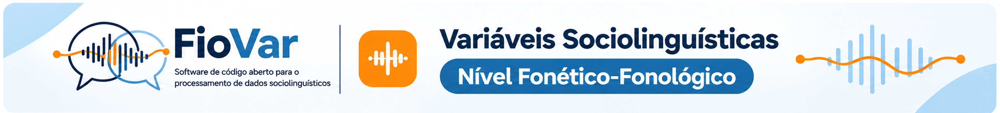

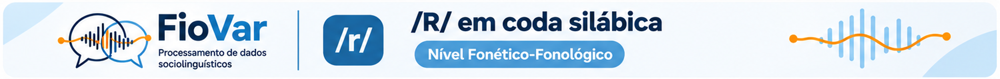

# **17. Identificação de contextos de variação de /r/ em coda**

Nesta etapa, serão identificadas ocorrências candidatas de /r/ em coda silábica, nas posições medial, como em “porta”, e final de palavra, como em “falar”, para a análise da alternância entre realização e apagamento.

A busca parte da representação ortográfica e cria anotações vinculadas às palavras para posterior codificação. A inclusão dos candidatos no envelope de variação e a classificação como realizado ou não realizado dependem da revisão do contexto e da escuta do áudio.

## **17.1 Qual é o envelope de variação?**

O envelope de variação reúne os contextos em que as variantes investigadas podem ocorrer. Sua definição permite comparar ocorrências de um mesmo fenômeno, seguindo critérios consistentes.

Devem ser codificadas as diferentes formas de realização do /R/ em coda silábica.



## **17.2 Quais preditores linguísticos serão considerados?**

A análise considerará os grupos de fatores linguísticos abaixo, recuperados das anotações do EAF na etapa de tabulação.

| Preditor | Fatores |
|---|---|
| Posição da coda na palavra | Medial e final. |
| Tonicidade da sílaba | Tônica e átona. |
| Classe morfológica | Substantivo, adjetivo, numeral, pronome, artigo, verbo, verbo no infinitivo, advérbio, preposição, conjunção e interjeição. |
| Altura da vogal antecedente | Alta, média-alta, média-baixa e baixa. |
| Anterioridade da vogal antecedente | Anterior, central e posterior. |
| Nasalidade da vogal antecedente | Oral e nasalizada. |
| Ponto da consoante seguinte | Labial, coronal e dorsal, com pausa registrada como contexto adicional. |
| Modo da consoante seguinte | Oclusiva, africada, fricativa, nasal, tepe, vibrante, retroflexa e lateral. |
| Vozeamento da consoante seguinte | Vozeada e não vozeada. |



## **17.3 Como executar?**

1. Confira a trilha selecionada e as configurações de busca.
2. Clique em ▶ na célula de código abaixo.
3. Selecione apenas o EAF com a transcrição fonética revisada.
4. Aguarde a identificação dos candidatos e o download do resultado.

Esta etapa não utiliza modelos de transcrição nem solicita o WAV.

Se nenhum candidato for encontrado, aparecerá uma mensagem informando o resultado. Nesse caso, nenhum novo EAF será exportado.

In [ ]:
# ============================================================
# 19. IDENTIFICAÇÃO DOS CONTEXTOS E PREPARAÇÃO DA CODIFICAÇÃO DE /r/
# ============================================================

# ============================================================
# 1. IMPORTAR RECURSOS E DEFINIR A BUSCA
# ============================================================

import io
import json
import re
import tempfile
import xml.etree.ElementTree as ET

from pathlib import Path
from google.colab import files

TRILHA_BASE = "S1"
TRILHA_PALAVRAS = f"{TRILHA_BASE}_palavras"

# Substitua este valor no ELAN pela variante observada.
VALOR_INICIAL = "a_codificar"

# Palavras que não devem ser selecionadas como candidatas.
STOPLIST = []

CONFIGURACOES = {
    "interna": {
        "trilha": "/r/ em coda interna",
        "padrao": r"r(?=[bcçdfgjklmnpqstvxz])",
        "restricao": "Symbolic_Subdivision",
    },
    "final": {
        "trilha": "/r/ em coda final",
        "padrao": r"r$",
        "restricao": "Symbolic_Association",
    },
}

# A busca usa a escrita das palavras.
# A confirmação dos candidatos e a codificação das variantes
# devem ser feitas pela escuta e revisão humana no ELAN.

# ============================================================
# 2. RECEBER O EAF
# ============================================================

print("Selecione o EAF com a transcrição fonética revisada.")
enviados = files.upload()

if len(enviados) != 1:
    raise ValueError("Envie exatamente um EAF.")

nome_arquivo, conteudo = next(iter(enviados.items()))

if Path(nome_arquivo).suffix.lower() != ".eaf":
    raise ValueError("O arquivo deve ter extensão .eaf.")

parser = ET.XMLParser(
    target=ET.TreeBuilder(
        insert_comments=True,
        insert_pis=True,
    )
)

raiz = ET.parse(io.BytesIO(conteudo), parser=parser).getroot()

if raiz.tag != "ANNOTATION_DOCUMENT":
    raise ValueError("Estrutura de EAF não reconhecida.")

header = raiz.find("HEADER")

if header is None:
    raise ValueError("Cabeçalho do EAF ausente.")

# ============================================================
# 3. CONFERIR AS TRILHAS E OS IDENTIFICADORES
# ============================================================

trilhas = {}

for trilha in raiz.findall("TIER"):
    nome = trilha.get("TIER_ID")

    if not nome or nome in trilhas:
        raise ValueError("Nome de trilha ausente ou repetido.")

    trilhas[nome] = trilha

necessarias = (
    TRILHA_BASE,
    TRILHA_PALAVRAS,
    f"{TRILHA_BASE}_fonetica",
)

for nome in necessarias:
    if nome not in trilhas:
        raise ValueError(f"Trilha ausente: {nome}")

if not raiz.findall("LINGUISTIC_TYPE"):
    raise ValueError("Tipos linguísticos ausentes.")

protegidas = {
    "/r/ em coda",
    "/r/ em coda interna",
    "/r/ em coda final",
    f"{TRILHA_BASE}_r_em_final_de_palavra",
}

if protegidas & set(trilhas):
    raise ValueError(
        "O arquivo já contém trilhas de /r/. "
        "Envie a versão anterior à codificação para "
        "preservar as anotações existentes."
    )

originais = {
    nome: ET.tostring(trilha)
    for nome, trilha in trilhas.items()
}

ids_usados = set()

for item in raiz.findall("./TIER/ANNOTATION/*"):
    aid = item.get("ANNOTATION_ID")

    if not aid or aid in ids_usados:
        raise ValueError("ID de anotação ausente ou repetido.")

    ids_usados.add(aid)

tipos_usados = {
    item.get("LINGUISTIC_TYPE_ID")
    for item in raiz.findall("LINGUISTIC_TYPE")
}


def novo_id(prefixo, usados):
    numero = 1

    while f"{prefixo}_{numero}" in usados:
        numero += 1

    identificador = f"{prefixo}_{numero}"
    usados.add(identificador)

    return identificador


# ============================================================
# 4. REUNIR AS PALAVRAS
# ============================================================

palavras = []

for wrapper in trilhas[TRILHA_PALAVRAS].findall("ANNOTATION"):
    itens = list(wrapper)

    if len(itens) != 1:
        raise ValueError("Estrutura de anotação inválida.")

    item = itens[0]

    if item.tag != "ALIGNABLE_ANNOTATION":
        raise ValueError(
            "As palavras ainda não possuem tempos individuais. "
            "Execute primeiro a etapa de transcrição fonética."
        )

    texto = item.findtext("ANNOTATION_VALUE", default="").strip()

    if not any(c.isalnum() for c in texto):
        continue

    if any(c.isspace() for c in texto):
        raise ValueError(
            f"Anotação com mais de uma palavra: {texto!r}."
        )

    palavras.append({
        "id": item.get("ANNOTATION_ID"),
        "texto": texto,
    })

if not palavras:
    raise ValueError("Nenhuma palavra foi encontrada.")

ignorar = {
    palavra.strip().casefold()
    for palavra in STOPLIST
}

participante = (
    trilhas[TRILHA_PALAVRAS].get("PARTICIPANT")
    or trilhas[TRILHA_BASE].get("PARTICIPANT")
)

# ============================================================
# 5. CRIAR AS TRILHAS DE CODIFICAÇÃO
# ============================================================

novas_trilhas = []
novos_tipos = []
mapa_alvos = []
contagens = {}

for contexto, configuracao in CONFIGURACOES.items():
    tipo_id = novo_id(
        f"fiovar_r_{contexto}", tipos_usados
    )

    nova = ET.Element(
        "TIER",
        TIER_ID=configuracao["trilha"],
        PARENT_REF=TRILHA_PALAVRAS,
        LINGUISTIC_TYPE_REF=tipo_id,
        ANNOTATOR="Busca automática; codificação humana pendente",
    )

    if participante:
        nova.set("PARTICIPANT", participante)

    padrao = re.compile(
        configuracao["padrao"],
        flags=re.IGNORECASE,
    )

    quantidade = 0

    for palavra in palavras:
        if palavra["texto"].casefold() in ignorar:
            continue

        anterior = None

        for ordem, ocorrencia in enumerate(
            padrao.finditer(palavra["texto"]),
            start=1,
        ):
            id_alvo = novo_id(
                f"fiovar_r_{contexto}", ids_usados
            )

            atributos = {
                "ANNOTATION_ID": id_alvo,
                "ANNOTATION_REF": palavra["id"],
            }

            if anterior:
                atributos["PREVIOUS_ANNOTATION"] = anterior

            wrapper = ET.SubElement(nova, "ANNOTATION")

            item = ET.SubElement(
                wrapper,
                "REF_ANNOTATION",
                atributos,
            )

            ET.SubElement(
                item, "ANNOTATION_VALUE"
            ).text = VALOR_INICIAL

            mapa_alvos.append({
                "id_alvo": id_alvo,
                "id_palavra": palavra["id"],
                "palavra": palavra["texto"],
                "contexto": contexto,
                "ordem_no_contexto": ordem,
                "posicao_na_escrita": ocorrencia.start() + 1,
            })

            anterior = id_alvo
            quantidade += 1

    contagens[contexto] = quantidade
    novas_trilhas.append(nova)

    novos_tipos.append(
        ET.Element(
            "LINGUISTIC_TYPE",
            LINGUISTIC_TYPE_ID=tipo_id,
            TIME_ALIGNABLE="false",
            GRAPHIC_REFERENCES="false",
            CONSTRAINTS=configuracao["restricao"],
        )
    )

# ============================================================
# 6. INSERIR AS TRILHAS E REGISTRAR OS CRITÉRIOS
# ============================================================

if not mapa_alvos:
    print("Nenhum candidato encontrado.")
    print("Nenhum EAF foi alterado ou exportado.")

else:
    posicao = max(
        i for i, filho in enumerate(raiz)
        if filho.tag == "TIER"
    ) + 1

    for trilha in novas_trilhas:
        raiz.insert(posicao, trilha)
        posicao += 1

    posicao = max(
        i for i, filho in enumerate(raiz)
        if filho.tag == "LINGUISTIC_TYPE"
    ) + 1

    for tipo in novos_tipos:
        raiz.insert(posicao, tipo)
        posicao += 1

    descricoes = {
        "Symbolic_Subdivision": (
            "Ordered symbolic subdivision of a parent annotation"
        ),
        "Symbolic_Association": (
            "One-to-one symbolic association with a parent annotation"
        ),
    }

    for nome, descricao in descricoes.items():
        if any(
            item.get("STEREOTYPE") == nome
            for item in raiz.findall("CONSTRAINT")
        ):
            continue

        posicao = next(
            (
                i for i, filho in enumerate(raiz)
                if filho.tag in {
                    "CONTROLLED_VOCABULARY",
                    "LEXICON_REF",
                    "EXTERNAL_REF",
                }
            ),
            len(raiz),
        )

        raiz.insert(
            posicao,
            ET.Element(
                "CONSTRAINT",
                STEREOTYPE=nome,
                DESCRIPTION=descricao,
            ),
        )

    ET.SubElement(
        header,
        "PROPERTY",
        NAME="fiovar_cod_r_alvos",
    ).text = json.dumps(
        {
            "valor_inicial": VALOR_INICIAL,
            "unidade": "uma anotação por alvo",
            "criterio": (
                "busca ortográfica; revisão humana necessária"
            ),
            "configuracoes": CONFIGURACOES,
            "stoplist": STOPLIST,
            "alvos": mapa_alvos,
        },
        ensure_ascii=False,
    )

    # ========================================================
    # 7. CONFERIR A PRESERVAÇÃO DOS DADOS
    # ========================================================

    for nome, original in originais.items():
        if ET.tostring(trilhas[nome]) != original:
            raise RuntimeError(
                f"A trilha original {nome} foi alterada."
            )

    ids_palavras = {palavra["id"] for palavra in palavras}

    for trilha in novas_trilhas:
        for item in trilha.findall(
            "./ANNOTATION/REF_ANNOTATION"
        ):
            if item.get("ANNOTATION_REF") not in ids_palavras:
                raise RuntimeError(
                    "Um alvo perdeu seu vínculo com a palavra."
                )

    # ========================================================
    # 8. PADRONIZAR O NOME E BAIXAR O EAF
    # ========================================================

    nome_base = re.sub(
        r"(?:\s*\(\d+\))+\s*$",
        "",
        Path(nome_arquivo).stem,
    ).strip()

    marcadores = (
        r"REV|PRE_ETIQ|PRE_STZ|PRE|ETIQ|"
        r"STZ|SLC|FON|com_SILAC|SILAC|"
        r"stanza_sem_lemas|stanza|CAND_RFIN|COD_R"
    )

    nome_base = re.sub(
        rf"(?:_(?:{marcadores}))+$",
        "",
        nome_base,
        flags=re.IGNORECASE,
    )

    pasta = Path(
        tempfile.mkdtemp(prefix="fiovar_codificacao_r_")
    )

    destino = pasta / f"{nome_base}_COD_R.eaf"

    ET.ElementTree(raiz).write(
        destino,
        encoding="utf-8",
        xml_declaration=True,
    )

    ET.parse(destino)

    print("\nPreparação da codificação concluída!")
    print("Candidatos internos:", contagens["interna"])
    print("Candidatos finais:", contagens["final"])
    print("Arquivo gerado:", destino.name)
    print("As trilhas anteriores e seus tempos foram preservados.")
    print(
        "Abra o EAF no ELAN, confira os candidatos e substitua "
        "'a_codificar' pela variante observada."
    )
    print(
        "O sufixo COD_R não confirma validação humana."
    )

    files.download(str(destino))

## **17.4 Quais trilhas serão criadas?**

Serão acrescentadas duas trilhas vinculadas à trilha de palavras.

- `/r/ em coda interna`, com os candidatos encontrados no interior das palavras.
- `/r/ em coda final`, com os candidatos encontrados no final das palavras.

Cada alvo receberá uma anotação com o valor `a_codificar`. Se uma palavra apresentar mais de um alvo interno, cada ocorrência terá sua própria anotação.

As trilhas anteriores, incluindo a transcrição fonética, e seus tempos serão preservados.

## **17.5 Qual resultado esperar?**

Ao concluir, aparecerá “Preparação da codificação concluída!”, acompanhada das quantidades de candidatos internos e finais.

O navegador iniciará o download direto do EAF.

```text
CarlosC_IDA62_GENHOM_ESCSUP_COD_R.eaf
```

O código preserva o pseudônimo e os códigos sociais, retira os sufixos das etapas anteriores e acrescenta `_COD_R`.

Esse sufixo identifica a saída desta etapa. Ele não confirma revisão humana nem classificação das variantes.

Salve o arquivo na pasta de trabalho e preserve a versão anterior.

## **17.4 Como registrar a variante observada?**

As ocorrências encontradas receberão inicialmente o valor `a_codificar`. Esse valor indica que a classificação ainda está pendente.

Após o processamento, abra o EAF no ELAN, ouça cada ocorrência e substitua `a_codificar` pela categoria correspondente à variante observada.

Essas categorias preencherão o campo `VD`, abreviação de variável dependente, na tabela de resultados. Defina os códigos antes de iniciar a classificação e mantenha a mesma escrita em todas as ocorrências.

A sugestão fonética serve como apoio à revisão. Uma anotação fonética vazia não comprova apagamento do /r/.

## **17.5 O que revisar antes de continuar?**

Abra o EAF no ELAN e confira os candidatos pela escuta, aplicando o envelope de variação definido para a pesquisa.

Verifique se há ocorrências indevidamente identificadas ou que não foram detectadas. Confira especialmente os contextos entre palavras e não interprete automaticamente o fim de um segmento como uma pausa na fala. Registre as ocorrências duvidosas para nova escuta ou discussão.

Salve o EAF após a revisão e a codificação, preservando o pseudônimo e os códigos sociais no nome do arquivo. Acrescente manualmente o sufixo `_VAL` antes da extensão `.eaf` para indicar que os dados foram validados.

Por exemplo, o arquivo `CarlosC_IDA62_GENHOM_ESCSUP_COD_R.eaf` deverá ser salvo como `CarlosC_IDA62_GENHOM_ESCSUP_COD_R_VAL.eaf`.

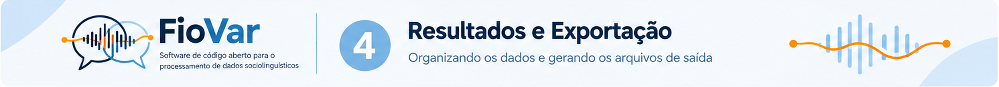

# **18. Codificação e tabulação dos dados**

Nesta etapa, utilizaremos uma rotina adaptada a partir do DMSocio para reunir a codificação das ocorrências e os preditores em uma planilha. As adaptações atendem à estrutura dos arquivos EAF e ao fluxo de processamento do FioVar.


## **18.1 Quais arquivos enviar?**

Utilize os EAFs após conferir os candidatos e codificar a variável nas trilhas `/r/ em coda interna` e `/r/ em coda final`.

Preserve a etiqueta com o pseudônimo e os códigos sociais. Envie somente uma versão de cada arquivo, evitando duplicar ocorrências.

Não é necessário enviar o áudio. A célula utiliza as anotações e os vínculos armazenados nos EAFs.

## **18.2 O que conferir antes de executar?**

Confira os nomes das trilhas nas configurações do código. Por padrão, a análise utiliza as palavras, a morfologia e a fonologia de `S1`.

O campo `VD` preservará o conteúdo das trilhas de codificação, sem impor categorias. Resolva as marcações pendentes, como `a_codificar`, antes da análise estatística.

Em `STATUS_REVISAO`, mantenha `pendente` ou informe `revisada` ou `duvidosa`, conforme a situação dos dados. Esse valor será aplicado a todas as ocorrências da execução; não há verificação automática da revisão.

## **18.3 Como executar?**

Clique em ▶ na célula de código abaixo e selecione os EAFs a partir da caixa de selação que vai abrir na linha 1970. Para enviar vários arquivos, utilize Ctrl ou Shift durante a seleção.

Aguarde o processamento e o download de `Dados_FioVar_r_coda.xlsx`.

Se algum arquivo apresentar erro, a exportação será interrompida. Confira a mensagem, corrija o problema e execute novamente.

In [21]:
# ============================================================
# 20. CODIFICAÇÃO E TABULAÇÃO — UM OU MÚLTIPLOS EAFs
# ============================================================

from google.colab import files
from pathlib import Path

import xml.etree.ElementTree as ET
import re
import unicodedata
import importlib.util
import subprocess
import sys

# ============================================================
# 1. CONFIGURAÇÕES
# ============================================================

TRILHA_PALAVRAS = "S1_palavras"
TRILHA_MORFOLOGIA = "S1_morfologia"
TRILHA_FONETICA = "S1_fonetica"

NOMES_TRILHA_FONOLOGIA = (
    "S1_FONOLOGIA",
    "S1_fonologia",
)

TRILHAS_VD = {
    "/r/ em coda interna": "medial",
    "/r/ em coda final": "final",
}

QUANTIDADE_CONTEXTO = 5

SIMBOLOS_R = {
    "R", "r", "ɾ", "ʁ", "ɹ", "ɻ", "ʀ", "ɽ"
}

MARCADORES_TONICIDADE = {"’", "ˈ", "'"}
SEPARADORES_SILABA = {"-", ".", "·"}
FRONTEIRAS_PALAVRA = {"#", "|", "‖", " "}
ENVOLTORIOS = [("[", "]"), ("/", "/")]

PADRAO_PAUSA = re.compile(r"\.{4,}")

# Para desambiguar palavras com mais de um candidato:
# (ID_PARTICIPANTE, ID da palavra, posição): índice do candidato.
# A contagem dos candidatos começa em zero.

INDICES_R = {}

GENEROS = {
    "HOM": "Homem",
}

ESCOLARIDADES = {
    "SUP": "Superior",
    "FUND": "Fundamental",
}

CLASSES_POR_NOTACAO = {}

MAPA_UPOS = {
    "NOUN": "substantivo",
    "PROPN": "substantivo",
    "ADJ": "adjetivo",
    "NUM": "numeral",
    "PRON": "pronome",
    "VERB": "verbo",
    "AUX": "verbo",
    "ADV": "advérbio",
    "ADP": "preposição",
    "CCONJ": "conjunção",
    "SCONJ": "conjunção",
    "INTJ": "interjeição",
}

ARTIGOS = {
    "o", "a", "os", "as",
    "um", "uma", "uns", "umas",
}

STATUS_REVISAO = "pendente"

# ============================================================
# 2. SÍMBOLOS E MAPAS DO PORTUGUÊS BRASILEIRO
# ============================================================

ALIASES_SIMBOLOS = {
    "S": "ʃ",
    "Z": "ʒ",
    "N": "ɲ",
    "L": "ʎ",
}

MAPA_VOGAIS = {
    "i": ("alta", "anterior"),
    "e": ("media_alta", "anterior"),
    "ɛ": ("media_baixa", "anterior"),
    "a": ("baixa", "central"),
    "ɔ": ("media_baixa", "posterior"),
    "o": ("media_alta", "posterior"),
    "u": ("alta", "posterior"),
    "ɪ": ("alta", "anterior"),
    "ʊ": ("alta", "posterior"),
    "ɐ": ("baixa", "central"),
    "ə": ("indeterminado", "central"),
}

VOGAIS = set(MAPA_VOGAIS) | set(
    "áéíóúâêôãõà"
)

# Ordem dos valores:
# ponto fonético, modo, vozeamento, nasalidade e ponto amplo.

MAPA_CONSOANTES = {
    "p": (
        "bilabial", "oclusiva",
        "surda", "oral", "labial"
    ),
    "b": (
        "bilabial", "oclusiva",
        "sonora", "oral", "labial"
    ),
    "t": (
        "dental_alveolar", "oclusiva",
        "surda", "oral", "coronal"
    ),
    "d": (
        "dental_alveolar", "oclusiva",
        "sonora", "oral", "coronal"
    ),
    "k": (
        "velar", "oclusiva",
        "surda", "oral", "dorsal"
    ),
    "g": (
        "velar", "oclusiva",
        "sonora", "oral", "dorsal"
    ),
    "ɡ": (
        "velar", "oclusiva",
        "sonora", "oral", "dorsal"
    ),
    "f": (
        "labiodental", "fricativa",
        "surda", "oral", "labial"
    ),
    "v": (
        "labiodental", "fricativa",
        "sonora", "oral", "labial"
    ),
    "s": (
        "alveolar", "fricativa",
        "surda", "oral", "coronal"
    ),
    "z": (
        "alveolar", "fricativa",
        "sonora", "oral", "coronal"
    ),
    "ʃ": (
        "pos_alveolar", "fricativa",
        "surda", "oral", "coronal"
    ),
    "ʒ": (
        "pos_alveolar", "fricativa",
        "sonora", "oral", "coronal"
    ),
    "m": (
        "bilabial", "nasal",
        "sonora", "nasal", "labial"
    ),
    "n": (
        "alveolar", "nasal",
        "sonora", "nasal", "coronal"
    ),
    "ɲ": (
        "palatal", "nasal",
        "sonora", "nasal", "coronal"
    ),
    "ɱ": (
        "labiodental", "nasal",
        "sonora", "nasal", "labial"
    ),
    "ŋ": (
        "velar", "nasal",
        "sonora", "nasal", "dorsal"
    ),
    "l": (
        "alveolar", "aproximante_lateral",
        "sonora", "oral", "coronal"
    ),
    "ɫ": (
        "alveolar", "aproximante_lateral",
        "sonora", "oral", "coronal"
    ),
    "ʎ": (
        "palatal", "aproximante_lateral",
        "sonora", "oral", "coronal"
    ),
    "j": (
        "palatal", "aproximante",
        "sonora", "oral", "coronal"
    ),
    "w": (
        "labiovelar", "aproximante",
        "sonora", "oral", "labial+dorsal"
    ),
    "tʃ": (
        "pos_alveolar", "africada",
        "surda", "oral", "coronal"
    ),
    "dʒ": (
        "pos_alveolar", "africada",
        "sonora", "oral", "coronal"
    ),
    "t͡ʃ": (
        "pos_alveolar", "africada",
        "surda", "oral", "coronal"
    ),
    "d͡ʒ": (
        "pos_alveolar", "africada",
        "sonora", "oral", "coronal"
    ),
    "ɾ": (
        "alveolar", "tepe",
        "sonora", "oral", "coronal"
    ),
    "r": (
        "alveolar", "vibrante",
        "sonora", "oral", "coronal"
    ),
    "ɹ": (
        "alveolar", "aproximante",
        "sonora", "oral", "coronal"
    ),
    "ɻ": (
        "retroflexa", "aproximante",
        "sonora", "oral", "coronal"
    ),
    "ɽ": (
        "retroflexa", "tepe",
        "sonora", "oral", "coronal"
    ),
    "x": (
        "velar", "fricativa",
        "surda", "oral", "dorsal"
    ),
    "ɣ": (
        "velar", "fricativa",
        "sonora", "oral", "dorsal"
    ),
    "χ": (
        "uvular", "fricativa",
        "surda", "oral", "dorsal"
    ),
    "ʁ": (
        "uvular", "fricativa",
        "sonora", "oral", "dorsal"
    ),
    "ʀ": (
        "uvular", "vibrante",
        "sonora", "oral", "dorsal"
    ),
    "h": (
        "glotal", "fricativa",
        "surda", "oral", "sem_ponto_oral"
    ),
    "ɦ": (
        "glotal", "fricativa",
        "sonora", "oral", "sem_ponto_oral"
    ),
}

# ============================================================
# 3. COLUNAS DA PLANILHA
# ============================================================

CABECALHO = [
    "ID_PARTICIPANTE",
    "PSEUDONIMO",
    "IDADE",
    "GENERO",
    "ESCOLARIDADE",
    "ITEM_LEXICAL",
    "TRANSCRICAO_FONETICA",
    "TRANSCRICAO_FONOLOGICA",
    "VD",
    "POSICAO_CODA",
    "TONICIDADE_SILABA",
    "CLASSE_MORFOLOGICA",
    "NOTACAO_MORFOLOGICA",
    "SEGMENTO_ANTECEDENTE",
    "ALTURA_VOGAL_ANT",
    "ANTERIORIDADE_VOGAL_ANT",
    "NASALIDADE_VOGAL_ANT",
    "SEGMENTO_SEGUINTE",
    "PONTO_CONS_SEG",
    "MODO_CONS_SEG",
    "VOZEAMENTO_CONS_SEG",
    "CONTEXTO_ANTERIOR_PALAVRA",
    "PALAVRA",
    "CONTEXTO_SEGUINTE_PALAVRA",
    "STATUS_REVISAO",
]

# ============================================================
# 4. IDENTIFICAÇÃO E FATORES SOCIAIS
# ============================================================

def identificar_participante(nome_arquivo):
    etiqueta = re.sub(
        r"(?:\s*\(\d+\))+\s*$",
        "",
        Path(nome_arquivo).stem,
    ).strip()

    if not etiqueta:
        raise ValueError(
            "Etiqueta do participante vazia."
        )

    return etiqueta


def extrair_pseudonimo(etiqueta):
    return etiqueta.split("_", 1)[0].strip()


def fatores_sociais(etiqueta):
    def extrair(padrao):
        resultado = re.search(
            padrao, etiqueta
        )

        return (
            resultado.group(1)
            if resultado else ""
        )

    idade = extrair(
        r"(?:^|_)IDA(\d+)(?=_|$)"
    )

    genero = extrair(
        r"(?:^|_)GEN([^_]+)(?=_|$)"
    )

    escolaridade = extrair(
        r"(?:^|_)ESC([^_]+)(?=_|$)"
    )

    return {
        "IDADE": idade,
        "GENERO": GENEROS.get(
            genero, genero
        ),
        "ESCOLARIDADE": ESCOLARIDADES.get(
            escolaridade, escolaridade
        ),
    }


# ============================================================
# 5. CLASSIFICAÇÃO MORFOLÓGICA
# ============================================================

def classe_gramatical(notacao, palavra):
    tag = notacao.strip()

    if tag in CLASSES_POR_NOTACAO:
        return CLASSES_POR_NOTACAO[tag]

    declarados = re.findall(
        r"(?<!\w)UPOS\s*[:=]\s*([A-Z]+)(?!\w)",
        tag.upper(),
    )

    if declarados:
        candidatos = set(declarados)

    else:
        reconhecidos = set(MAPA_UPOS) | {
            "DET",
            "PART",
            "PUNCT",
            "SYM",
            "X",
        }

        candidatos = (
            {tag.upper()}
            if tag.upper() in reconhecidos
            else set()
        )

    if len(candidatos) != 1:
        return "indeterminado"

    upos = next(iter(candidatos))

    if upos in {"VERB", "AUX"}:
        formas = {
            forma.casefold()
            for forma in re.findall(
                r"(?<!\w)VerbForm\s*=\s*([A-Za-z]+)(?!\w)",
                tag,
                flags=re.IGNORECASE,
            )
        }

        if "inf" in formas:
            return (
                "verbo.inf"
                if len(formas) == 1
                else "indeterminado"
            )

        return "verbo"

    if upos == "DET":
        return (
            "artigo"
            if palavra.strip().casefold() in ARTIGOS
            else "indeterminado"
        )

    return MAPA_UPOS.get(
        upos, "indeterminado"
    )


# ============================================================
# 6. LEITURA DOS SÍMBOLOS E DIACRÍTICOS
# ============================================================

def normalizar_categoria(valor):
    decomposto = unicodedata.normalize(
        "NFD",
        str(valor).strip().casefold(),
    )

    texto = "".join(
        caractere
        for caractere in decomposto
        if not unicodedata.combining(caractere)
    )

    texto = re.sub(
        r"\s+", "_", texto
    )

    return (
        "verbo_infinitivo"
        if texto == "verbo.inf"
        else texto
    )


def simbolo_base(simbolo):
    valor = str(simbolo).strip()

    valor = ALIASES_SIMBOLOS.get(
        valor, valor
    )

    if valor.startswith("~"):
        valor = valor[1:]

    decomposto = unicodedata.normalize(
        "NFD", valor
    )

    ignorados = {
        "\u0303",
        "\u0301",
        "\u0302",
        "\u0300",
    }

    return unicodedata.normalize(
        "NFC",
        "".join(
            caractere
            for caractere in decomposto
            if caractere not in ignorados
        ),
    )


def analisar_simbolo(simbolo):
    original = str(simbolo).strip()

    nfd = unicodedata.normalize(
        "NFD", original
    )

    nasal = (
        original.startswith("~")
        or "\u0303" in nfd
    )

    voz = (
        "nao_vozeada"
        if any(
            marca in nfd
            for marca in (
                "\u0325",
                "\u030a",
            )
        )
        else "vozeada"
        if "\u032c" in nfd
        else None
    )

    dental = "\u032a" in nfd

    consulta = "".join(
        caractere
        for caractere in nfd
        if caractere not in {
            "\u0303",
            "\u0325",
            "\u030a",
            "\u032c",
            "\u032a",
        }
    )

    base = simbolo_base(
        unicodedata.normalize(
            "NFC", consulta
        )
    )

    return base, nasal, voz, dental


def eh_rotico(unidade):
    return (
        unidade in SIMBOLOS_R
        or simbolo_base(unidade) in SIMBOLOS_R
    )


def eh_vogal(unidade):
    return (
        unidade in VOGAIS
        or simbolo_base(unidade) in MAPA_VOGAIS
    )


# ============================================================
# 7. LEITURA DA REPRESENTAÇÃO FONOLÓGICA
# ============================================================

def unidades_fonologicas(transcricao):
    texto = unicodedata.normalize(
        "NFC", transcricao.strip()
    )

    for abertura, fechamento in ENVOLTORIOS:
        if (
            texto.startswith(abertura)
            and texto.endswith(fechamento)
        ):
            texto = texto[
                len(abertura):-len(fechamento)
            ]
            break

    unidades = []
    i = 0

    compostos = (
        "t͡ʃ",
        "d͡ʒ",
        "tʃ",
        "dʒ",
    )

    while i < len(texto):
        composto = next(
            (
                simbolo
                for simbolo in compostos
                if texto.startswith(simbolo, i)
            ),
            None,
        )

        if composto:
            unidades.append(composto)
            i += len(composto)

        elif (
            texto[i] == "~"
            and i + 1 < len(texto)
            and eh_vogal(texto[i + 1])
        ):
            unidades.append(
                texto[i:i + 2]
            )
            i += 2

        elif (
            unicodedata.combining(texto[i])
            and unidades
        ):
            unidades[-1] += texto[i]
            i += 1

        else:
            unidades.append(texto[i])
            i += 1

    return unidades


def primeiro_segmento_fonologico(transcricao):
    unidades = unidades_fonologicas(
        transcricao
    )

    if not unidades:
        return "indeterminado"

    ignorados = (
        MARCADORES_TONICIDADE
        | SEPARADORES_SILABA
        | FRONTEIRAS_PALAVRA
    )

    i = 0

    while i < len(unidades):
        unidade = unidades[i]

        if (
            unidade in ignorados
            or unidade.isspace()
        ):
            i += 1
            continue

        if unidade == "~":
            if (
                i + 1 < len(unidades)
                and eh_vogal(unidades[i + 1])
            ):
                return "~" + unidades[i + 1]

            return "indeterminado"

        for quantidade in (3, 2):
            trecho = unidades[
                i:i + quantidade
            ]

            if len(trecho) != quantidade:
                continue

            if any(
                parte in ignorados
                or parte.isspace()
                for parte in trecho
            ):
                continue

            composto = "".join(trecho)

            if composto in MAPA_CONSOANTES:
                return composto

        if any(
            unicodedata.category(c).startswith("L")
            for c in unidade
        ):
            return unidade

        return "indeterminado"

    return "indeterminado"


# ============================================================
# 8. IDENTIFICAÇÃO DO ALVO E DOS CONTEXTOS
# ============================================================

def identificar_alvo(
    unidades,
    posicao,
    id_palavra,
    id_participante,
):
    marcas = (
        MARCADORES_TONICIDADE
        | SEPARADORES_SILABA
    )

    segmentos = [
        i
        for i, unidade in enumerate(unidades)
        if unidade not in marcas
    ]

    while segmentos:
        unidade = unidades[segmentos[-1]]

        if (
            unidade in FRONTEIRAS_PALAVRA
            or unidade.isspace()
        ):
            segmentos.pop()

        else:
            break

    if not segmentos:
        return None

    ultimo = segmentos[-1]

    candidatos = [
        i
        for i, unidade in enumerate(unidades)
        if eh_rotico(unidade)
        and (
            (
                posicao == "final"
                and i == ultimo
            )
            or (
                posicao == "medial"
                and i < ultimo
            )
        )
    ]

    chave = (
        id_participante,
        id_palavra,
        posicao,
    )

    if chave in INDICES_R:
        indice = INDICES_R[chave]

        if (
            not isinstance(indice, int)
            or not 0 <= indice < len(candidatos)
        ):
            raise ValueError(
                f"Índice de /r/ inválido para {chave}."
            )

        return candidatos[indice]

    return (
        candidatos[0]
        if len(candidatos) == 1
        else None
    )


def contexto_vizinho(
    unidades,
    alvo,
    direcao,
):
    indice = alvo + direcao

    while 0 <= indice < len(unidades):
        unidade = unidades[indice]

        if unidade in (
            MARCADORES_TONICIDADE
            | SEPARADORES_SILABA
        ):
            indice += direcao
            continue

        if (
            unidade in FRONTEIRAS_PALAVRA
            or unidade.isspace()
        ):
            return "fronteira de palavra"

        if any(
            unicodedata.category(c).startswith("L")
            for c in unidade
        ):
            return unidade

        return "indeterminado"

    return (
        "início de palavra"
        if direcao < 0
        else "fim de palavra"
    )


def completar_contexto_seguinte(
    contexto_fonologico,
    palavras_seguintes,
    referencias_fonologicas,
):
    if contexto_fonologico not in {
        "fim de palavra", ""
    }:
        return contexto_fonologico

    for palavra in palavras_seguintes:
        texto = palavra["texto"]

        primeira_letra = next(
            (
                indice
                for indice, caractere in enumerate(texto)
                if caractere.isalpha()
            ),
            None,
        )

        pausa = PADRAO_PAUSA.search(texto)

        if pausa is not None and (
            primeira_letra is None
            or pausa.start() < primeira_letra
        ):
            return "pausa"

        if primeira_letra is None:
            continue

        transcricao = referencias_fonologicas.get(
            palavra["id"], ""
        )

        if not transcricao.strip():
            return "indeterminado"

        return primeiro_segmento_fonologico(
            transcricao
        )

    return "indeterminado"


# ============================================================
# 9. TONICIDADE
# ============================================================

def tonicidade_silaba(
    unidades,
    alvo,
    palavra="",
    notacao="",
):
    if alvo is None:
        return "indeterminado"

    silabas = []
    atual = []

    for i, unidade in enumerate(unidades):
        if unidade in SEPARADORES_SILABA:
            if atual:
                silabas.append(atual)

            atual = []

        else:
            atual.append(i)

    if atual:
        silabas.append(atual)

    silabas_com_vogal = [
        silaba
        for silaba in silabas
        if any(
            eh_vogal(unidades[i])
            for i in silaba
        )
    ]

    silaba_alvo = next(
        (
            silaba
            for silaba in silabas_com_vogal
            if alvo in silaba
        ),
        None,
    )

    if silaba_alvo is None:
        return "indeterminado"

    tem_separador = any(
        unidade in SEPARADORES_SILABA
        for unidade in unidades
    )

    nucleos = [
        i
        for i, unidade in enumerate(unidades)
        if eh_vogal(unidade)
    ]

    marcadores = [
        i
        for i, unidade in enumerate(unidades)
        if unidade in MARCADORES_TONICIDADE
    ]

    monossilabo = (
        len(silabas_com_vogal) == 1
        and (
            tem_separador
            or len(nucleos) == 1
        )
    )

    if monossilabo:
        item = palavra.strip().casefold()

        classe = classe_gramatical(
            notacao, palavra
        )

        if len(marcadores) == 1:
            marcador = marcadores[0]

            if any(
                i > marcador
                and eh_vogal(unidades[i])
                for i in silaba_alvo
            ):
                return "tônica"

            return "indeterminado"

        if len(marcadores) > 1:
            return "indeterminado"

        if (
            item == "por"
            and classe == "preposição"
        ):
            return "átona"

        if classe in {
            "substantivo",
            "adjetivo",
            "verbo",
            "verbo.inf",
            "numeral",
        }:
            return "tônica"

        return "indeterminado"

    if len(marcadores) != 1:
        return "indeterminado"

    marcador = marcadores[0]

    if tem_separador:
        silaba_tonica = next(
            (
                silaba
                for silaba in silabas_com_vogal
                if marcador in silaba
            ),
            None,
        )

        if silaba_tonica is None:
            return "indeterminado"

        if not any(
            i > marcador
            and eh_vogal(unidades[i])
            for i in silaba_tonica
        ):
            return "indeterminado"

        return (
            "tônica"
            if silaba_alvo == silaba_tonica
            else "átona"
        )

    for anterior, seguinte in zip(
        nucleos, nucleos[1:]
    ):
        entre = unidades[
            anterior + 1:seguinte
        ]

        if all(
            unidade in MARCADORES_TONICIDADE
            for unidade in entre
        ):
            return "indeterminado"

    anteriores = [
        i for i in nucleos
        if i < alvo
    ]

    posteriores = [
        i for i in nucleos
        if i > marcador
    ]

    if not anteriores or not posteriores:
        return "indeterminado"

    nucleo_alvo = anteriores[-1]
    nucleo_tonico = posteriores[0]

    def intervalo_valido(inicio, fim):
        for unidade in unidades[inicio + 1:fim]:
            if unidade in MARCADORES_TONICIDADE:
                continue

            if (
                unidade in FRONTEIRAS_PALAVRA
                or unidade.isspace()
            ):
                return False

            if not any(
                unicodedata.category(c).startswith("L")
                for c in unidade
            ):
                return False

        return True

    if not intervalo_valido(
        nucleo_alvo, alvo
    ):
        return "indeterminado"

    if not intervalo_valido(
        marcador, nucleo_tonico
    ):
        return "indeterminado"

    return (
        "tônica"
        if nucleo_alvo == nucleo_tonico
        else "átona"
    )


def analisar_fonologia(
    transcricao,
    posicao,
    id_palavra,
    id_participante,
    palavra="",
    notacao="",
):
    unidades = unidades_fonologicas(
        transcricao
    )

    alvo = identificar_alvo(
        unidades,
        posicao,
        id_palavra,
        id_participante,
    )

    if alvo is None:
        return (
            "indeterminado",
            "indeterminado",
            "indeterminado",
        )

    return (
        contexto_vizinho(
            unidades, alvo, -1
        ),
        contexto_vizinho(
            unidades, alvo, 1
        ),
        tonicidade_silaba(
            unidades,
            alvo,
            palavra,
            notacao,
        ),
    )


# ============================================================
# 10. CLASSIFICAÇÃO DOS PREDITORES
# ============================================================

def classificar_contextos(
    antecedente,
    seguinte,
):
    dados = {
        coluna: "indeterminado"
        for coluna in (
            "ALTURA_VOGAL_ANT",
            "ANTERIORIDADE_VOGAL_ANT",
            "NASALIDADE_VOGAL_ANT",
            "PONTO_CONS_SEG",
            "MODO_CONS_SEG",
            "VOZEAMENTO_CONS_SEG",
        )
    }

    (
        base_ant,
        nasal_ant,
        _,
        _,
    ) = analisar_simbolo(antecedente)

    if base_ant in MAPA_VOGAIS:
        altura, anterioridade = MAPA_VOGAIS[
            base_ant
        ]

        dados.update({
            "ALTURA_VOGAL_ANT": altura,
            "ANTERIORIDADE_VOGAL_ANT": anterioridade,
            "NASALIDADE_VOGAL_ANT": (
                "nasalizada"
                if nasal_ant
                else "oral"
            ),
        })

    elif base_ant in MAPA_CONSOANTES:
        for coluna in (
            "ALTURA_VOGAL_ANT",
            "ANTERIORIDADE_VOGAL_ANT",
            "NASALIDADE_VOGAL_ANT",
        ):
            dados[coluna] = "nao_aplicavel"

    (
        base,
        _,
        voz_marcada,
        _,
    ) = analisar_simbolo(seguinte)

    if seguinte == "pausa":
        dados.update({
            "PONTO_CONS_SEG": "pausa",
            "MODO_CONS_SEG": "nao_aplicavel",
            "VOZEAMENTO_CONS_SEG": "nao_aplicavel",
        })

        return dados

    if base in MAPA_VOGAIS:
        for coluna in (
            "PONTO_CONS_SEG",
            "MODO_CONS_SEG",
            "VOZEAMENTO_CONS_SEG",
        ):
            dados[coluna] = "nao_aplicavel"

        return dados

    if base not in MAPA_CONSOANTES:
        return dados

    (
        _,
        modo,
        voz,
        _,
        ponto,
    ) = MAPA_CONSOANTES[base]

    dados["PONTO_CONS_SEG"] = (
        ponto
        if ponto in {
            "labial",
            "coronal",
            "dorsal",
        }
        else "indeterminado"
    )

    if base in {"ɻ", "ɽ"}:
        modo = "retroflexa"

    elif modo == "aproximante_lateral":
        modo = "lateral"

    if modo not in {
        "oclusiva",
        "africada",
        "fricativa",
        "nasal",
        "tepe",
        "vibrante",
        "retroflexa",
        "lateral",
    }:
        modo = "indeterminado"

    dados["MODO_CONS_SEG"] = modo

    dados["VOZEAMENTO_CONS_SEG"] = (
        voz_marcada
        or {
            "sonora": "vozeada",
            "surda": "nao_vozeada",
        }.get(
            voz, "indeterminado"
        )
    )

    return dados


# ============================================================
# 11. ORDEM DAS PALAVRAS
# ============================================================

def ordenar_grupo(grupo):
    ids = {
        palavra["id"]
        for palavra in grupo
    }

    anteriores = {}
    sucessores = {}

    for palavra in grupo:
        anterior = palavra["elemento"].get(
            "PREVIOUS_ANNOTATION"
        )

        if anterior:
            if anterior not in ids:
                raise ValueError(
                    "PREVIOUS_ANNOTATION fora do trecho: "
                    f"{palavra['id']}"
                )

            if anterior in sucessores:
                raise ValueError(
                    "Sequência de palavras com ramificação."
                )

            anteriores[
                palavra["id"]
            ] = anterior

            sucessores[
                anterior
            ] = palavra["id"]

    pendentes = {
        palavra["id"]: palavra
        for palavra in grupo
    }

    resultado = []

    while pendentes:
        disponiveis = [
            palavra
            for palavra in pendentes.values()
            if anteriores.get(
                palavra["id"]
            ) not in pendentes
        ]

        if not disponiveis:
            raise ValueError(
                "Ciclo na sequência das palavras."
            )

        escolhida = min(
            disponiveis,
            key=lambda palavra: (
                palavra["inicio"],
                palavra["fim"],
                palavra["ordem"],
            ),
        )

        resultado.append(escolhida)
        del pendentes[escolhida["id"]]

    return resultado


# ============================================================
# 12. PROCESSAMENTO DO EAF
# ============================================================

def processar_eaf(nome_arquivo, conteudo):
    participante = identificar_participante(
        nome_arquivo
    )

    pseudonimo = extrair_pseudonimo(
        participante
    )

    sociais = fatores_sociais(
        participante
    )

    raiz = ET.fromstring(conteudo)

    trilhas = {}
    anotacoes = {}
    por_trilha = {}

    for tier in raiz.findall("TIER"):
        nome = tier.get("TIER_ID")

        if not nome or nome in trilhas:
            raise ValueError(
                "Nome de trilha ausente ou duplicado: "
                f"{nome}"
            )

        trilhas[nome] = tier
        por_trilha[nome] = []

        for wrapper in tier.findall("ANNOTATION"):
            elementos = list(wrapper)

            if len(elementos) != 1:
                raise ValueError(
                    "Estrutura de anotação inválida "
                    f"em {nome}."
                )

            elemento = elementos[0]
            aid = elemento.get("ANNOTATION_ID")

            if not aid or aid in anotacoes:
                raise ValueError(
                    f"ID ausente ou duplicado: {aid}"
                )

            registro = {
                "id": aid,
                "trilha": nome,
                "elemento": elemento,
                "texto": elemento.findtext(
                    "ANNOTATION_VALUE",
                    default="",
                ),
                "ordem": len(
                    por_trilha[nome]
                ),
            }

            anotacoes[aid] = registro
            por_trilha[nome].append(registro)

    fonologias = [
        nome
        for nome in NOMES_TRILHA_FONOLOGIA
        if nome in trilhas
    ]

    if len(fonologias) != 1:
        raise ValueError(
            "É necessária uma única trilha de fonologia. "
            f"Encontradas: {fonologias}."
        )

    trilha_fonologia = fonologias[0]

    obrigatorias = {
        TRILHA_PALAVRAS,
        TRILHA_MORFOLOGIA,
        trilha_fonologia,
        *TRILHAS_VD,
    }

    faltantes = (
        obrigatorias - trilhas.keys()
    )

    if faltantes:
        raise ValueError(
            f"Trilhas ausentes: {sorted(faltantes)}."
        )

    slots = {
        slot.get("TIME_SLOT_ID"): slot.get("TIME_VALUE")
        for slot in raiz.findall(
            "./TIME_ORDER/TIME_SLOT"
        )
    }

    def cadeia(aid):
        visitados = set()

        while aid:
            if aid in visitados:
                raise ValueError(
                    "Ciclo nas referências de anotações."
                )

            if aid not in anotacoes:
                raise ValueError(
                    f"Referência inexistente: {aid}"
                )

            visitados.add(aid)

            registro = anotacoes[aid]
            yield registro

            aid = registro["elemento"].get(
                "ANNOTATION_REF"
            )

    def tempos(aid):
        for registro in cadeia(aid):
            elemento = registro["elemento"]

            if elemento.tag == "ALIGNABLE_ANNOTATION":
                try:
                    inicio = int(
                        slots[
                            elemento.get(
                                "TIME_SLOT_REF1"
                            )
                        ]
                    )

                    fim = int(
                        slots[
                            elemento.get(
                                "TIME_SLOT_REF2"
                            )
                        ]
                    )

                except (
                    KeyError,
                    TypeError,
                    ValueError,
                ) as erro:
                    raise ValueError(
                        "Tempo ausente ou inválido: "
                        f"{registro['id']}"
                    ) from erro

                if inicio < 0 or fim <= inicio:
                    raise ValueError(
                        "Intervalo inválido: "
                        f"{registro['id']}"
                    )

                return inicio, fim

        raise ValueError(
            "Anotação sem tempo resolvível: "
            f"{aid}"
        )

    palavras = por_trilha[
        TRILHA_PALAVRAS
    ]

    palavras_por_id = {
        palavra["id"]: palavra
        for palavra in palavras
    }

    for palavra in palavras:
        (
            palavra["inicio"],
            palavra["fim"],
        ) = tempos(palavra["id"])

        ancestrais = list(
            cadeia(palavra["id"])
        )[1:]

        palavra["grupo"] = (
            ancestrais[0]["id"]
            if ancestrais else None
        )

        if palavra["grupo"] is None:
            pai_tier = trilhas[
                TRILHA_PALAVRAS
            ].get("PARENT_REF")

            pais = []

            for pai in por_trilha.get(
                pai_tier, []
            ):
                inicio, fim = tempos(
                    pai["id"]
                )

                if (
                    inicio <= palavra["inicio"]
                    and palavra["fim"] <= fim
                ):
                    pais.append(pai["id"])

            if len(pais) != 1:
                raise ValueError(
                    "Trecho da palavra não identificado "
                    "de forma única: "
                    f"{palavra['id']}"
                )

            palavra["grupo"] = pais[0]

    def palavra_relacionada(registro):
        for ancestral in cadeia(
            registro["id"]
        ):
            if (
                ancestral["trilha"]
                == TRILHA_PALAVRAS
            ):
                return ancestral["id"]

        inicio, fim = tempos(
            registro["id"]
        )

        candidatos = [
            palavra["id"]
            for palavra in palavras
            if palavra["inicio"] <= inicio
            and fim <= palavra["fim"]
        ]

        if len(candidatos) != 1:
            raise ValueError(
                "Associação temporal ambígua ou ausente "
                f"para {registro['id']} "
                f"em {registro['trilha']}."
            )

        return candidatos[0]

    camadas = {}

    for nome in (
        TRILHA_MORFOLOGIA,
        trilha_fonologia,
        TRILHA_FONETICA,
    ):
        valores = {}

        for registro in por_trilha.get(
            nome, []
        ):
            id_palavra = palavra_relacionada(
                registro
            )

            if id_palavra in valores:
                raise ValueError(
                    f"Mais de uma anotação em {nome} "
                    f"para {id_palavra}."
                )

            valores[
                id_palavra
            ] = registro["texto"]

        camadas[nome] = valores

    grupos = {}

    for palavra in palavras:
        grupos.setdefault(
            palavra["grupo"], []
        ).append(palavra)

    contextos = {}
    palavras_seguintes_por_id = {}

    for grupo in grupos.values():
        grupo = ordenar_grupo(grupo)

        for indice, palavra in enumerate(grupo):
            anteriores = grupo[
                max(
                    0,
                    indice - QUANTIDADE_CONTEXTO,
                ):indice
            ]

            seguintes = grupo[
                indice + 1:
                indice + 1 + QUANTIDADE_CONTEXTO
            ]

            contextos[
                palavra["id"]
            ] = (
                " ".join(
                    p["texto"]
                    for p in anteriores
                ),
                " ".join(
                    p["texto"]
                    for p in seguintes
                ),
            )

            palavras_seguintes_por_id[
                palavra["id"]
            ] = seguintes

    ocorrencias = []

    for trilha_vd, posicao in TRILHAS_VD.items():
        for registro in por_trilha[trilha_vd]:
            vd = registro["texto"].strip()

            if not vd:
                continue

            id_palavra = palavra_relacionada(
                registro
            )

            palavra = palavras_por_id[
                id_palavra
            ]

            item = palavra["texto"]

            notacao = camadas[
                TRILHA_MORFOLOGIA
            ].get(id_palavra, "")

            fonetica = camadas[
                TRILHA_FONETICA
            ].get(id_palavra, "")

            fonologia = camadas[
                trilha_fonologia
            ].get(id_palavra, "")

            (
                antecedente,
                seguinte,
                tonicidade,
            ) = analisar_fonologia(
                fonologia,
                posicao,
                id_palavra,
                participante,
                palavra=item,
                notacao=notacao,
            )

            (
                contexto_anterior,
                contexto_seguinte,
            ) = contextos[id_palavra]

            seguinte = completar_contexto_seguinte(
                seguinte,
                palavras_seguintes_por_id[
                    id_palavra
                ],
                camadas[trilha_fonologia],
            )

            classificacao = classificar_contextos(
                antecedente,
                seguinte,
            )

            linha = {
                "ID_PARTICIPANTE": participante,
                "PSEUDONIMO": pseudonimo,
                **sociais,
                "ITEM_LEXICAL": item,
                "TRANSCRICAO_FONETICA": fonetica,
                "TRANSCRICAO_FONOLOGICA": fonologia,
                "VD": vd,
                "POSICAO_CODA": posicao,

                "TONICIDADE_SILABA": normalizar_categoria(
                    tonicidade
                ),

                "CLASSE_MORFOLOGICA": normalizar_categoria(
                    classe_gramatical(
                        notacao, item
                    )
                ),

                "NOTACAO_MORFOLOGICA": notacao,
                "SEGMENTO_ANTECEDENTE": antecedente,
                "SEGMENTO_SEGUINTE": seguinte,

                **classificacao,

                "CONTEXTO_ANTERIOR_PALAVRA": contexto_anterior,
                "PALAVRA": item,
                "CONTEXTO_SEGUINTE_PALAVRA": contexto_seguinte,
                "STATUS_REVISAO": STATUS_REVISAO,
            }

            ocorrencias.append((
                palavra["inicio"],
                palavra["fim"],
                palavra["ordem"],
                registro["ordem"],
                linha,
            ))

    ocorrencias.sort(
        key=lambda item: item[:4]
    )

    return [
        item[4]
        for item in ocorrencias
    ]


# ============================================================
# 13. VERIFICAÇÃO DAS ETIQUETAS
# ============================================================

def verificar_etiquetas(enviados):
    vistas = {}

    for nome in enviados:
        etiqueta = identificar_participante(
            nome
        )

        if etiqueta in vistas:
            raise ValueError(
                "Dois arquivos possuem a mesma etiqueta: "
                f"{vistas[etiqueta]} e {nome}. "
                "Envie apenas um por etiqueta."
            )

        vistas[etiqueta] = nome


# ============================================================
# 14. CONFERÊNCIA E ENVIO DOS ARQUIVOS
# ============================================================

if STATUS_REVISAO not in {
    "pendente",
    "revisada",
    "duvidosa",
}:
    raise ValueError(
        "STATUS_REVISAO inválido."
    )

if (
    not isinstance(QUANTIDADE_CONTEXTO, int)
    or QUANTIDADE_CONTEXTO < 1
):
    raise ValueError(
        "QUANTIDADE_CONTEXTO deve ser "
        "um inteiro positivo."
    )

print(
    "Selecione um ou vários EAFs "
    "com a variável codificada."
)

enviados = files.upload()

if not enviados:
    raise ValueError(
        "Nenhum arquivo enviado."
    )

if any(
    Path(nome).suffix.lower() != ".eaf"
    for nome in enviados
):
    raise ValueError(
        "Envie somente arquivos EAF."
    )

verificar_etiquetas(enviados)

# ============================================================
# 15. CONSOLIDAÇÃO
# ============================================================

linhas_finais = []
erros = []

for nome, conteudo in sorted(
    enviados.items(),
    key=lambda item: item[0].casefold(),
):
    try:
        linhas = processar_eaf(
            nome, conteudo
        )

        linhas_finais.extend(linhas)

        print(
            f"OK — {nome}: "
            f"{len(linhas)} ocorrência(s)."
        )

    except (ValueError, ET.ParseError) as erro:
        erros.append(
            f"{nome}: {erro}"
        )

if erros:
    raise ValueError(
        "A planilha não foi gerada.\n"
        + "\n".join(erros)
    )

# ============================================================
# 16. EXPORTAÇÃO E DOWNLOAD
# ============================================================

if importlib.util.find_spec("openpyxl") is None:
    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "openpyxl",
    ])

from openpyxl import Workbook
from openpyxl.styles import Font, Alignment
from openpyxl.utils import get_column_letter

if len(linhas_finais) > 1_048_575:
    raise ValueError(
        "O total ultrapassa o limite "
        "de uma aba do Excel."
    )

wb = Workbook()
ws = wb.active
ws.title = "DADOS"

ws.append(CABECALHO)

for linha in linhas_finais:
    valores = []

    for coluna in CABECALHO:
        valor = linha.get(coluna, "")

        if coluna == "IDADE":
            texto = str(valor).strip()
            valor = int(texto) if texto else None
        else:
            valor = str(valor)

        valores.append(valor)

    if any(
        isinstance(valor, str) and len(valor) > 32_767
        for valor in valores
    ):
        raise ValueError(
            "Um valor ultrapassa o limite "
            "de uma célula do Excel."
        )

    ws.append(valores)

    for coluna, celula in zip(
        CABECALHO, ws[ws.max_row]
    ):
        if coluna == "IDADE":
            celula.number_format = "0"
        else:
            celula.data_type = "s"
for celula in ws[1]:
    celula.font = Font(
        bold=True
    )

    celula.alignment = Alignment(
        vertical="center",
        wrap_text=True,
    )

ws.row_dimensions[1].height = 65
ws.freeze_panes = "A2"
ws.auto_filter.ref = ws.dimensions

for indice, coluna in enumerate(
    CABECALHO, start=1
):
    largura = 28

    if (
        coluna.startswith("CONTEXTO_")
        or coluna == "NOTACAO_MORFOLOGICA"
    ):
        largura = 48

    elif coluna == "ID_PARTICIPANTE":
        largura = 48

    ws.column_dimensions[
        get_column_letter(indice)
    ].width = largura

destino = Path(
    "Dados_FioVar_r_coda.xlsx"
)

wb.save(destino)

print()

print(
    "Ocorrências exportadas:",
    len(linhas_finais),
)

print(
    "Fim de segmento sem contexto seguinte "
    "não foi convertido em pausa."
)

print(
    "Confira os valores indeterminados "
    "antes da análise."
)

print(
    "Arquivo gerado:",
    destino.name,
)

files.download(str(destino))

Selecione um ou vários EAFs com a variável codificada.


Saving CarlosC_IDA62_GENHOM_ESCSUP_COD_R.eaf to CarlosC_IDA62_GENHOM_ESCSUP_COD_R.eaf
OK — CarlosC_IDA62_GENHOM_ESCSUP_COD_R.eaf: 157 ocorrência(s).

Ocorrências exportadas: 157
Fim de segmento sem contexto seguinte não foi convertido em pausa.
Confira os valores indeterminados antes da análise.
Arquivo gerado: Dados_FioVar_r_coda.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## **18.4 O que a planilha reúne?**

A planilha apresenta a identificação do participante, os fatores sociais, as transcrições, a VD e os preditores linguísticos.

As propriedades segmentais são classificadas a partir da trilha de fonologia. A transcrição fonética é incluída para consulta.

As colunas de contexto mostram até cinco palavras anteriores e seguintes dentro do mesmo segmento, com a palavra alvo entre elas. Essa janela auxilia a revisão e não constitui um preditor fonológico.

## **18.5 O que conferir no resultado?**

Confira a quantidade de ocorrências, as categorias da VD e os fatores sociais. Revise também os valores `indeterminado`, que indicam informação insuficiente, e `nao_aplicavel`, que indica uma propriedade inaplicável ao contexto.

A tabulação não confirma o envelope de variação nem substitui a revisão das anotações. Verifique as classificações antes de selecionar e agrupar os fatores para a análise estatística.

Salve a planilha na pasta de trabalho e preserve os EAFs utilizados em sua geração.

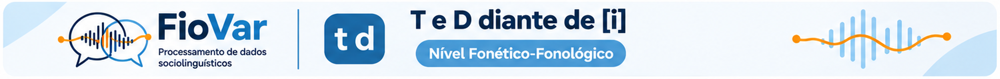

Em construção.

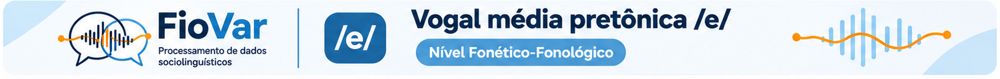

Em construção.

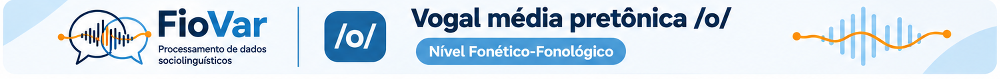

Em construção.

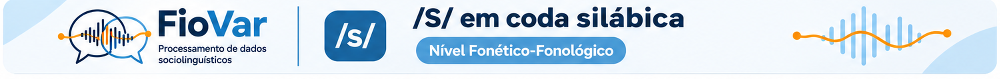

Em construção.

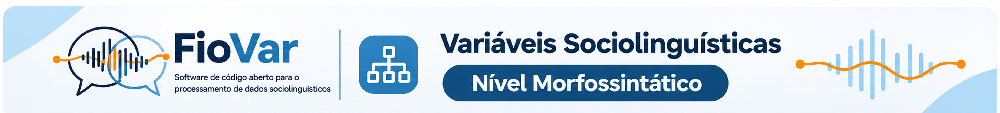

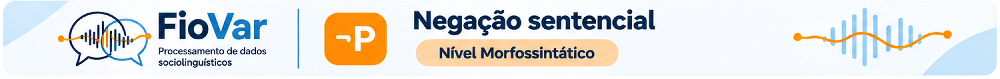

Em construção.

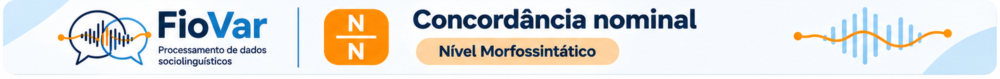

Em construção.

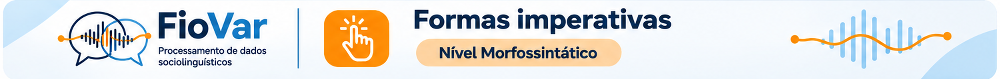

Em construção.

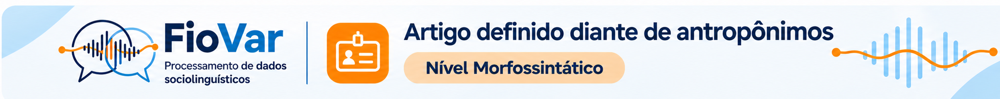

Em construção.

## **Declaração de uso de inteligência artificial**

Na construção do FioVar, utilizei o ChatGPT e o Codex, da OpenAI, ferramentas baseadas em modelos de linguagem capazes de gerar textos e códigos a partir de instruções em linguagem natural. Essas ferramentas auxiliaram na elaboração e reorganização de código Python, na proposição de soluções para integrar ferramentas de processamento linguístico e na redação da documentação do software. Seu uso teve caráter de assistência ao desenvolvimento, sem substituir as decisões metodológicas, a revisão humana ou os testes necessários à validação do programa.

# **Licença de uso do FioVar**

O código original do FioVar é disponibilizado sob a licença MIT. Bibliotecas, modelos, ferramentas e códigos de terceiros mantêm suas respectivas licenças e condições de utilização; a licença do FioVar não substitui essas condições nem autoriza seu relicenciamento.

A versão v0.1.0-alpha é experimental e fornecida sem garantia. Suas saídas requerem revisão humana e avaliação de adequação aos objetivos de cada pesquisa. A licença do software não concede autorização para divulgar gravações, dados pessoais ou outros materiais de pesquisa.

# **REFERÊNCIAS**


AUTORIDADE NACIONAL DE PROTEÇÃO DE DADOS. **Guia orientativo: tratamento de dados pessoais para fins acadêmicos e para a realização de estudos e pesquisas**. Brasília, DF: ANPD, 2024. Disponível em: [página oficial do guia](https://www.gov.br/anpd/pt-br/centrais-de-conteudo/materiais-educativos-e-publicacoes/guia-orientativo-tratamento-de-dados-pessoais-para-fins-academicos-e-para-a-realizacao-de-estudos-e-pesquisas). Acesso em: 1 nov. 2026.

BAIN, Max; HUH, Jaesung; HAN, Tengda; ZISSERMAN, Andrew. WhisperX: time-accurate speech transcription of long-form audio. In: INTERSPEECH, 24., 2023, Dublin. **Proceedings […]**. [S. l.]: International Speech Communication Association, 2023. p. 4489–4493. Disponível em: [texto integral](https://www.isca-archive.org/interspeech_2023/bain23_interspeech.pdf). Acesso em: 1 nov. 2026.

BARBOSA, Plínio A.; ALBANO, Eleonora C. Brazilian Portuguese. **Journal of the International Phonetic Association**, v. 34, n. 2, p. 227–232, 2004. DOI: 10.1017/S0025100304001756. Disponível em: [texto integral](https://www.cambridge.org/core/services/aop-cambridge-core/content/view/8EE69D52AE2D06C1EDA2841EA2E14FEC/S0025100304001756a.pdf/brazilian_portuguese.pdf). Acesso em: 1 nov. 2026.

BRASIL. **Lei nº 13.709, de 14 de agosto de 2018**. Lei Geral de Proteção de Dados Pessoais (LGPD). Brasília, DF: Presidência da República, 2018. Disponível em: [texto atualizado da lei](https://www.planalto.gov.br/ccivil_03/_ato2015-2018/2018/lei/l13709.htm). Acesso em: 1 nov. 2026.

CAIOCROCHA. **wav2vec2-large-xlsr-53-phoneme-portuguese**. [S. l.]: Hugging Face, [s. d.]. Modelo de reconhecimento de fala. Disponível em: [página do modelo](https://huggingface.co/caiocrocha/wav2vec2-large-xlsr-53-phoneme-portuguese). Acesso em: 1 nov. 2026.

CLEMENTS, George N.; HUME, Elizabeth V. The internal organization of speech sounds. In: GOLDSMITH, John A. (ed.). **The handbook of phonological theory**. Oxford: Blackwell, 1995. p. 245–306. Disponível em: [cópia digital do capítulo](https://coehuman.uodiyala.edu.iq/uploads/Coehuman%20library%20pdf/English%20library%D9%83%D8%AA%D8%A8%20%D8%A7%D9%84%D8%A7%D9%86%D9%83%D9%84%D9%8A%D8%B2%D9%8A/linguistics22/the%20handbook%20of%20phonology/7.%20The%20Internal%20Organization%20of%20Speech%20Sounds.pdf). Acesso em: 1 nov. 2026.

FFMPEG DEVELOPERS. **FFmpeg: documentation**. [S. l.], [s. d.]. Disponível em: [documentação oficial](https://ffmpeg.org/documentation.html). Acesso em: 1 nov. 2026.

GOOGLE. **Colaboratory: frequently asked questions**. [S. l.], [s. d.]. Disponível em: [perguntas frequentes do Colab](https://research.google.com/colaboratory/faq.html). Acesso em: 1 nov. 2026.

GOOGLE. **Colaboratory: termos do serviço**. [S. l.], [s. d.]. Disponível em: [termos do serviço](https://research.google.com/colaboratory/tos_v6.html). Acesso em: 1 nov. 2026.

GOOGLE. **Como o Google retém os dados que coletamos**. [S. l.], [s. d.]. Disponível em: [política de retenção de dados](https://policies.google.com/technologies/retention?hl=pt-BR). Acesso em: 1 nov. 2026.

GOOGLE. **Política de Privacidade**. [S. l.], [s. d.]. Disponível em: [Política de Privacidade do Google](https://policies.google.com/privacy?hl=pt-BR). Acesso em: 1 nov. 2026.

GROSMAN, Jonatas. **wav2vec2-large-xlsr-53-portuguese**. [S. l.]: Hugging Face, [s. d.]. Modelo de reconhecimento de fala. Disponível em: [página do modelo](https://huggingface.co/jonatasgrosman/wav2vec2-large-xlsr-53-portuguese). Acesso em: 1 nov. 2026.

HUGGING FACE. **Hugging Face Hub: documentation**. [S. l.], [s. d.]. Disponível em: [documentação do Hugging Face Hub](https://huggingface.co/docs/huggingface_hub/). Acesso em: 1 nov. 2026.

HUGGING FACE. **Transformers: documentation**. [S. l.], [s. d.]. Disponível em: [documentação do Transformers](https://huggingface.co/docs/transformers/). Acesso em: 1 nov. 2026.

HUGGING FACE. **User access tokens**. [S. l.], [s. d.]. Disponível em: [documentação de tokens de acesso](https://huggingface.co/docs/hub/security-tokens). Acesso em: 1 nov. 2026.

LABOV, William. **Sociolinguistic patterns**. Philadelphia: University of Pennsylvania Press, 1972.

MAX PLANCK INSTITUTE FOR PSYCHOLINGUISTICS. **ELAN: manual**. Nijmegen: Max Planck Institute for Psycholinguistics, [s. d.]. Disponível em: [manual do ELAN](https://www.mpi.nl/tools/elan/docs/ELAN_manual.pdf). Acesso em: 1 nov. 2026.

NUMBA DEVELOPERS. **Numba: documentation**. [S. l.], [s. d.]. Disponível em: [documentação do Numba](https://numba.readthedocs.io/). Acesso em: 1 nov. 2026.

NUMPY DEVELOPERS. **NumPy: documentation**. [S. l.], [s. d.]. Disponível em: [documentação do NumPy](https://numpy.org/doc/). Acesso em: 1 nov. 2026.

OPENNMT. **CTranslate2: quantization**. [S. l.], [s. d.]. Disponível em: [documentação sobre quantização](https://github.com/OpenNMT/CTranslate2/blob/master/docs/quantization.md). Acesso em: 1 nov. 2026.

OPENPYXL DEVELOPERS. **openpyxl: documentation**. [S. l.], [s. d.]. Disponível em: [documentação do openpyxl](https://openpyxl.readthedocs.io/). Acesso em: 1 nov. 2026.

OUSHIRO, Lívia. **DMSocio: aplicativo para manipulação de dados sociolinguísticos**. [S. l.], [s. d.]. Software. Disponível em: [DMSocio](https://oushiro.shinyapps.io/dmsocio/). Acesso em: 1 nov. 2026.

OUSHIRO, Lívia. **Identidade na pluralidade: avaliação, produção e percepção linguística na cidade de São Paulo**. 2015. Tese (Doutorado em Semiótica e Linguística Geral) — Faculdade de Filosofia, Letras e Ciências Humanas, Universidade de São Paulo, São Paulo, 2015. Disponível em: [Biblioteca Digital de Teses e Dissertações da USP](https://teses.usp.br/teses/disponiveis/8/8139/tde-15062015-104952/pt-br.html). Acesso em: 1 nov. 2026.

OUSHIRO, Lívia. **SILAC: transcrição fonológica de textos transcritos ortograficamente**. [S. l.], [s. d.]. Software. Disponível em: [repositório do SILAC](https://github.com/oushiro/silac). Acesso em: 1 nov. 2026.

PYANNOTE. **speaker-diarization-community-1**. [S. l.]: Hugging Face, [s. d.]. Modelo de diarização. Disponível em: [página do modelo](https://huggingface.co/pyannote/speaker-diarization-community-1). Acesso em: 1 nov. 2026.

PYMPI. **pympi: documentation**. [S. l.], [s. d.]. Disponível em: [documentação do pympi](https://dopefishh.github.io/pympi/). Acesso em: 1 nov. 2026.

PYTHON SOFTWARE FOUNDATION. **Python 3: documentation**. [S. l.], [s. d.]. Disponível em: [documentação do Python](https://docs.python.org/3/). Acesso em: 1 nov. 2026.

PYTORCH CONTRIBUTORS. **PyTorch: documentation**. [S. l.], [s. d.]. Disponível em: [documentação do PyTorch](https://pytorch.org/docs/stable/index.html). Acesso em: 1 nov. 2026.

QI, Peng; ZHANG, Yuhao; ZHANG, Yuhui; BOLTON, Jason; MANNING, Christopher D. Stanza: a Python natural language processing toolkit for many human languages. In: ANNUAL MEETING OF THE ASSOCIATION FOR COMPUTATIONAL LINGUISTICS, 58., 2020, Online. **Proceedings […]: system demonstrations**. [S. l.]: Association for Computational Linguistics, 2020. p. 101–108. DOI: 10.18653/v1/2020.acl-demos.14. Disponível em: [texto integral](https://aclanthology.org/2020.acl-demos.14/). Acesso em: 1 nov. 2026.

R CORE TEAM. **R: a language and environment for statistical computing**. Vienna: R Foundation for Statistical Computing, [s. d.]. Software. Disponível em: [Projeto R](https://www.r-project.org/). Acesso em: 1 nov. 2026.

SOUZA, Emerson Santos de. **A plasticidade dialetal de migrantes baianos na Região Metropolitana de São Paulo**. 2023. Tese (Doutorado em Linguística) — Instituto de Estudos da Linguagem, Universidade Estadual de Campinas, Campinas, 2023. Disponível em: [Repositório da Universidade Estadual de Campinas](https://hdl.handle.net/20.500.12733/15971). Acesso em: 1 nov. 2026.